In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np

# Arquivo com as 45.004 células completas
arquivo = "grid_50_model_complete_cases.gpkg"

# Carregar GeoPackage
gdf = gpd.read_file(arquivo)

print("Dimensões:", gdf.shape)
print("CRS:", gdf.crs)
print("\nColunas:")
print(gdf.columns.tolist())

Dimensões: (45004, 24)
CRS: EPSG:31983

Colunas:
['id', 'left', 'top', 'right', 'bottom', 'cell_area', 'celular_n', 'veiculo_n', 'residencia_n', 'veg_area', 'veg_pct', 'shadow_area', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero', 'geometry']


In [2]:
# Variáveis ambientais principais
environmental_vars = [
    "veg_pct",
    "shadow_pct"
]

# Variáveis de controle candidatas
control_vars = [
    "infrastructure_index",
    "high_income",
    "streetlight",
    "schools_r500m",
    "transport_hubs_r500m",
    "police_station_r500m",
    "private_parking_r500m",
    "paid_parking_distance",
    "moradores",
    "distancia_marco_zero"
]

variables = environmental_vars + control_vars

# Matriz de correlação de Pearson
corr = gdf[variables].corr(method="pearson")

corr.round(3)

,veg_pct,shadow_pct,infrastructure_index,high_income,streetlight,schools_r500m,transport_hubs_r500m,police_station_r500m,private_parking_r500m,paid_parking_distance,moradores,distancia_marco_zero
veg_pct,1.000,-0.086,0.057,0.222,0.030,-0.054,-0.105,-0.006,0.016,-0.094,-0.151,-0.097
shadow_pct,-0.086,1.000,0.057,0.243,0.080,0.070,0.136,0.064,0.344,-0.267,-0.189,-0.271
infrastructure_index,0.057,0.057,1.000,0.367,-0.008,0.071,-0.058,-0.015,-0.027,-0.021,-0.122,0.026
high_income,0.222,0.243,0.367,1.000,0.021,0.255,-0.038,0.015,0.161,-0.323,-0.223,-0.146
streetlight,0.030,0.080,-0.008,0.021,1.000,-0.040,0.126,0.061,0.141,-0.076,-0.062,-0.143
schools_r500m,-0.054,0.070,0.071,0.255,-0.040,1.000,0.061,0.102,-0.046,-0.132,-0.028,0.099
transport_hubs_r500m,-0.105,0.136,-0.058,-0.038,0.126,0.061,1.000,0.099,0.269,-0.127,-0.061,-0.186
police_station_r500m,-0.006,0.064,-0.015,0.015,0.061,0.102,0.099,1.000,0.153,-0.124,-0.046,-0.105
private_parking_r500m,0.016,0.344,-0.027,0.161,0.141,-0.046,0.269,0.153,1.000,-0.534,-0.318,-0.492
paid_parking_distance,-0.094,-0.267,-0.021,-0.323,-0.076,-0.132,-0.127,-0.124,-0.534,1.000,0.355,0.657


In [3]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Preditores do modelo:
# variáveis ambientais principais + controles
X = gdf[environmental_vars + control_vars].astype(float)

# Adiciona intercepto
X_vif = add_constant(X)

vif = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Retira o intercepto da tabela e ordena do maior para o menor
vif = (
    vif[vif["variable"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

vif.round(3)

,variable,VIF
0,paid_parking_distance,2.292
1,distancia_marco_zero,2.037
2,private_parking_r500m,1.696
3,high_income,1.515
4,shadow_pct,1.238
5,moradores,1.234
6,schools_r500m,1.192
7,infrastructure_index,1.186
8,transport_hubs_r500m,1.133
9,veg_pct,1.126


In [4]:

import pandas as pd

# Diagnóstico das variáveis dependentes
resultados = []

for variavel in ["celular_n", "veiculo_n"]:
    y = gdf[variavel]

    resultados.append({
        "Crime": variavel,
        "N": y.count(),
        "Total de crimes": y.sum(),
        "Média": y.mean(),
        "Variância": y.var(),
        "Variância / Média": y.var() / y.mean(),
        "Mediana": y.median(),
        "Máximo": y.max(),
        "Células com zero (%)": (y == 0).mean() * 100
    })

diagnostico = pd.DataFrame(resultados)

display(diagnostico.round(3))

,Crime,N,Total de crimes,Média,Variância,Variância / Média,Mediana,Máximo,Células com zero (%)
0,celular_n,45004,58695.0,1.304,30.624,23.481,0.0,277.0,68.687
1,veiculo_n,45004,14705.0,0.327,1.262,3.861,0.0,42.0,82.868



celular_n
Frequências de 0 a 10 crimes:
celular_n
0     30912
1      6346
2      2707
3      1401
4       812
5       554
6       367
7       284
8       230
9       174
10      147
Name: count, dtype: int64


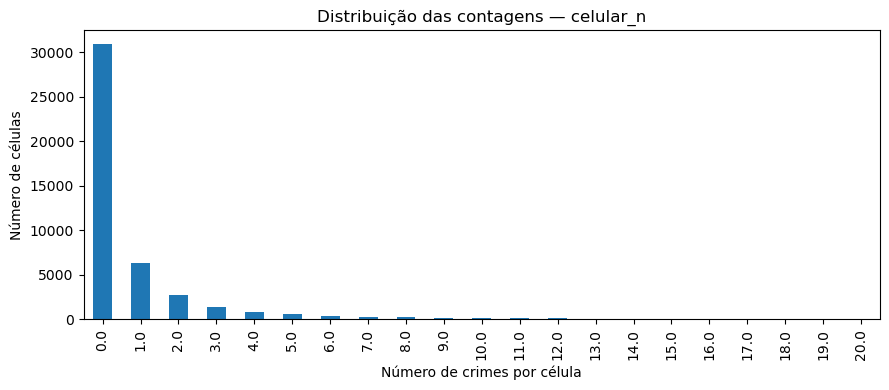


veiculo_n
Frequências de 0 a 10 crimes:
veiculo_n
0     37294
1      4907
2      1425
3       555
4       279
5       168
6       123
7        77
8        46
9        36
10       24
Name: count, dtype: int64


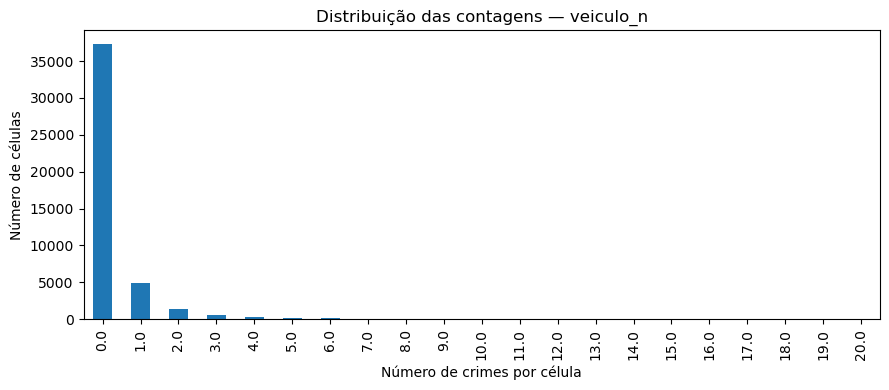

In [9]:

import matplotlib.pyplot as plt

for variavel in ["celular_n", "veiculo_n"]:
    frequencias = (
        gdf[variavel]
        .value_counts()
        .sort_index()
    )

    print(f"\n{variavel}")
    print("Frequências de 0 a 10 crimes:")
    print(frequencias.reindex(range(11), fill_value=0))

    plt.figure(figsize=(9, 4))

    frequencias.loc[frequencias.index <= 20].plot.bar()

    plt.title(f"Distribuição das contagens — {variavel}")
    plt.xlabel("Número de crimes por célula")
    plt.ylabel("Número de células")
    plt.tight_layout()
    plt.show()

In [11]:

import statsmodels.api as sm
from statsmodels.discrete.discrete_model import (
    Poisson,
    NegativeBinomial
)

X = sm.add_constant(
    gdf[["veg_pct", "shadow_pct"]].astype(float)
)

modelos_iniciais = {}

for crime in ["celular_n", "veiculo_n"]:
    y = gdf[crime].astype(int)

    poisson = Poisson(y, X).fit(
        disp=False,
        maxiter=200
    )

    nb = NegativeBinomial(
        y, X,
        loglike_method="nb2"
    ).fit(
        disp=False,
        maxiter=300
    )

    modelos_iniciais[crime] = {
        "Poisson": poisson,
        "NB2": nb
    }

    print(f"\n{'=' * 50}")
    print(crime)
    print(f"Poisson convergiu: {poisson.mle_retvals['converged']}")
    print(f"NB2 convergiu: {nb.mle_retvals['converged']}")
    print(f"AIC Poisson: {poisson.aic:.2f}")
    print(f"AIC NB2: {nb.aic:.2f}")
    print(f"Alpha NB2: {nb.params['alpha']:.4f}")


celular_n
Poisson convergiu: True
NB2 convergiu: True
AIC Poisson: 265398.53
AIC NB2: 114022.89
Alpha NB2: 5.7579

veiculo_n
Poisson convergiu: True
NB2 convergiu: True
AIC Poisson: 79507.56
AIC NB2: 60786.32
Alpha NB2: 5.5832


In [13]:

import numpy as np
import pandas as pd

resultados_zeros = []

for crime in ["celular_n", "veiculo_n"]:
    y = gdf[crime].astype(int)

    poisson = modelos_iniciais[crime]["Poisson"]
    nb = modelos_iniciais[crime]["NB2"]

    mu_p = poisson.predict()
    mu_nb = nb.predict()

    alpha = nb.params["alpha"]

    # Probabilidade de zero no Poisson
    p0_poisson = np.exp(-mu_p)

    # Probabilidade de zero na NB2
    p0_nb = (1 + alpha * mu_nb) ** (-1 / alpha)

    resultados_zeros.append({
        "Crime": crime,
        "Zeros observados (%)": (y == 0).mean() * 100,
        "Zeros previstos Poisson (%)": p0_poisson.mean() * 100,
        "Zeros previstos NB2 (%)": p0_nb.mean() * 100
    })

comparacao_zeros = pd.DataFrame(resultados_zeros)

display(comparacao_zeros.round(2))

,Crime,Zeros observados (%),Zeros previstos Poisson (%),Zeros previstos NB2 (%)
0,celular_n,68.69,29.86,69.70
1,veiculo_n,82.87,72.16,83.06


In [15]:

import statsmodels.api as sm
from statsmodels.discrete.discrete_model import NegativeBinomial

# Matriz de preditores: vegetação, sombra e dez controles
X_completo = sm.add_constant(
    gdf[environmental_vars + control_vars].astype(float)
)

modelos_completos = {}

for crime in ["celular_n", "veiculo_n"]:
    y = gdf[crime].astype(int)

    modelo = NegativeBinomial(
        y,
        X_completo,
        loglike_method="nb2"
    ).fit(
        method="bfgs",
        maxiter=500,
        disp=False
    )

    modelos_completos[crime] = modelo

    print(f"\n{'=' * 60}")
    print(crime)
    print("Convergiu:", modelo.mle_retvals["converged"])
    print("AIC:", round(modelo.aic, 2))
    print("Alpha:", round(modelo.params["alpha"], 4))
    print("\nCoeficientes ambientais:")
    print(
        modelo.summary2().tables[1].loc[
            ["veg_pct", "shadow_pct"]
        ]
    )


celular_n
Convergiu: True
AIC: 109483.72
Alpha: 4.3737

Coeficientes ambientais:
               Coef.  Std.Err.         z         P>|z|    [0.025    0.975]
veg_pct    -0.001369  0.000637 -2.149934  3.156047e-02 -0.002616 -0.000121
shadow_pct  0.003758  0.000755  4.975420  6.510640e-07  0.002277  0.005238


C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)



veiculo_n
Convergiu: True
AIC: 60403.83
Alpha: 5.2955

Coeficientes ambientais:
               Coef.  Std.Err.         z     P>|z|    [0.025    0.975]
veg_pct    -0.001804  0.000774 -2.331320  0.019736 -0.003320 -0.000287
shadow_pct  0.003478  0.000910  3.819778  0.000134  0.001693  0.005262


In [17]:

import numpy as np
import pandas as pd

diagnostico_residuos = []

for crime in ["celular_n", "veiculo_n"]:
    modelo = modelos_completos[crime]

    y = gdf[crime].to_numpy(dtype=float)
    mu = np.asarray(modelo.predict())
    alpha = float(modelo.params["alpha"])

    # Variância da NB2
    variancia = mu + alpha * mu**2

    # Resíduos de Pearson
    residuos = (y - mu) / np.sqrt(variancia)

    gdf[f"resid_{crime}"] = residuos

    diagnostico_residuos.append({
        "Crime": crime,
        "Média": np.mean(residuos),
        "Desvio-padrão": np.std(residuos, ddof=1),
        "Mínimo": np.min(residuos),
        "Mediana": np.median(residuos),
        "Máximo": np.max(residuos),
        "Valores não finitos": (~np.isfinite(residuos)).sum()
    })

display(pd.DataFrame(diagnostico_residuos).round(4))

,Crime,Média,Desvio-padrão,Mínimo,Mediana,Máximo,Valores não finitos
0,celular_n,-0.0002,1.7354,-0.4782,-0.3939,83.1660,0
1,veiculo_n,0.0003,1.1789,-0.4070,-0.3377,66.4467,0


In [19]:

import numpy as np

# Coordenadas dos centroides das células, em metros (EPSG:31983)
centroides = gdf.geometry.centroid

coords = np.column_stack([
    centroides.x.to_numpy(),
    centroides.y.to_numpy()
])

print("Número de células:", len(gdf))
print("Dimensões da matriz de coordenadas:", coords.shape)
print("Coordenadas não finitas:", (~np.isfinite(coords)).sum())
print("Centroides únicos:", len(np.unique(coords, axis=0)))
print("Centroides duplicados:", len(coords) - len(np.unique(coords, axis=0)))
print("CRS:", gdf.crs)

Número de células: 45004
Dimensões da matriz de coordenadas: (45004, 2)
Coordenadas não finitas: 0
Centroides únicos: 45004
Centroides duplicados: 0
CRS: EPSG:31983


In [21]:

from scipy.spatial import cKDTree
import pandas as pd

# Índice espacial eficiente para as 45.004 coordenadas
arvore = cKDTree(coords)

# Consulta dos 8 vizinhos mais próximos.
# k=9 inclui a própria célula na primeira posição.
distancias, indices = arvore.query(coords, k=9)

# Remove a própria célula (distância zero)
dist_vizinhos = distancias[:, 1:]

resumo_distancias = pd.DataFrame({
    "Vizinho": ["1º", "4º", "8º"],
    "Mínimo (m)": [
        dist_vizinhos[:, i].min() for i in [0, 3, 7]
    ],
    "Mediana (m)": [
        pd.Series(dist_vizinhos[:, i]).median() for i in [0, 3, 7]
    ],
    "P95 (m)": [
        pd.Series(dist_vizinhos[:, i]).quantile(0.95) for i in [0, 3, 7]
    ],
    "Máximo (m)": [
        dist_vizinhos[:, i].max() for i in [0, 3, 7]
    ]
})

display(resumo_distancias.round(2))

,Vizinho,Mínimo (m),Mediana (m),P95 (m),Máximo (m)
0,1º,50.00,50.00,50.00,380.79
1,4º,50.00,70.71,70.71,500.00
2,8º,70.71,100.00,111.80,570.09


In [23]:

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
import pandas as pd
import numpy as np

resultados_knn = []

n = len(coords)

for k in [4, 8]:

    # Vizinhos obtidos na consulta anterior
    vizinhos = indices[:, 1:k+1]

    linhas = np.repeat(np.arange(n), k)
    colunas = vizinhos.ravel()

    # Matriz esparsa de adjacência
    W = csr_matrix(
        (np.ones(len(linhas), dtype=np.int8),
         (linhas, colunas)),
        shape=(n, n)
    )

    # Simetrização: conexão se A escolhe B ou B escolhe A
    W = W.maximum(W.T)

    # Componentes conectados
    n_componentes, labels = connected_components(
        W,
        directed=False
    )

    tamanhos = np.bincount(labels)
    graus = np.diff(W.indptr)

    resultados_knn.append({
        "k": k,
        "Componentes": n_componentes,
        "Maior componente (células)": tamanhos.max(),
        "Maior componente (%)": tamanhos.max() / n * 100,
        "Menor nº de vizinhos": graus.min(),
        "Mediana de vizinhos": np.median(graus),
        "Maior nº de vizinhos": graus.max(),
        "Células sem vizinhos": (graus == 0).sum()
    })

display(pd.DataFrame(resultados_knn).round(2))

,k,Componentes,Maior componente (células),Maior componente (%),Menor nº de vizinhos,Mediana de vizinhos,Maior nº de vizinhos,Células sem vizinhos
0,4,2,44996,99.98,4,4.0,9,0
1,8,1,45004,100.00,8,9.0,16,0


In [25]:

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
import numpy as np
import pandas as pd

resultados_distancia = []
n = len(coords)

for raio in [50.01, 70.72, 100.01]:

    # Pares de centroides separados por até o raio
    pares = arvore.query_pairs(r=raio, output_type="ndarray")

    # Adjacência simétrica, sem autovizinhança
    linhas = np.concatenate([pares[:, 0], pares[:, 1]])
    colunas = np.concatenate([pares[:, 1], pares[:, 0]])

    W_dist = csr_matrix(
        (
            np.ones(len(linhas), dtype=np.int8),
            (linhas, colunas)
        ),
        shape=(n, n)
    )

    componentes, labels = connected_components(
        W_dist,
        directed=False
    )

    tamanhos = np.bincount(labels)
    graus = np.diff(W_dist.indptr)

    resultados_distancia.append({
        "Raio (m)": raio,
        "Componentes": componentes,
        "Maior componente (%)": tamanhos.max() / n * 100,
        "Células sem vizinhos": (graus == 0).sum(),
        "Mediana de vizinhos": np.median(graus),
        "Máximo de vizinhos": graus.max()
    })

display(pd.DataFrame(resultados_distancia).round(2))

,Raio (m),Componentes,Maior componente (%),Células sem vizinhos,Mediana de vizinhos,Máximo de vizinhos
0,50.01,51,99.62,31,3.0,4
1,70.72,25,99.71,15,6.0,8
2,100.01,14,99.83,7,9.0,12


In [27]:

import numpy as np
from scipy.sparse import csr_matrix
from libpysal.weights import WSP
from esda.moran import Moran

# Reconstrói a matriz k-NN (k = 4), simetrizada
n = len(coords)
k = 4

vizinhos = indices[:, 1:k+1]

linhas = np.repeat(np.arange(n), k)
colunas = vizinhos.ravel()

W_knn4 = csr_matrix(
    (np.ones(len(linhas)), (linhas, colunas)),
    shape=(n, n)
)

W_knn4 = W_knn4.maximum(W_knn4.T)
W_knn4.setdiag(0)
W_knn4.eliminate_zeros()

# Converte para formato PySAL e padroniza por linha
w = WSP(W_knn4).to_W()
w.transform = "r"

for crime in ["celular_n", "veiculo_n"]:
    residuos = gdf[f"resid_{crime}"].to_numpy()

    moran = Moran(
        residuos,
        w,
        permutations=999,
        two_tailed=True
    )

    print(f"\n{'=' * 45}")
    print(crime)
    print(f"Moran's I: {moran.I:.6f}")
    print(f"I esperado: {moran.EI:.6f}")
    print(f"p-valor (permutações): {moran.p_sim:.4f}")
    print(f"z-score (permutações): {moran.z_sim:.4f}")

C:\Users\Amazonas\anaconda3\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)



celular_n
Moran's I: 0.099713
I esperado: -0.000022
p-valor (permutações): 0.0010
z-score (permutações): 31.6119

veiculo_n
Moran's I: 0.050409
I esperado: -0.000022
p-valor (permutações): 0.0010
z-score (permutações): 16.4791


In [29]:

from libpysal.weights import WSP
from esda.moran import Moran
import numpy as np

# Reutiliza a matriz de distância já construída,
# agora com raio equivalente à vizinhança Queen
pares = arvore.query_pairs(r=70.72, output_type="ndarray")

linhas = np.concatenate([pares[:, 0], pares[:, 1]])
colunas = np.concatenate([pares[:, 1], pares[:, 0]])

W_queen = csr_matrix(
    (np.ones(len(linhas)), (linhas, colunas)),
    shape=(len(coords), len(coords))
)

w_queen = WSP(W_queen).to_W(silence_warnings=True)
w_queen.transform = "r"

print("Células sem vizinhos:", len(w_queen.islands))
print("Componentes conectados:", w_queen.n_components)

for crime in ["celular_n", "veiculo_n"]:
    residuos = gdf[f"resid_{crime}"].to_numpy()

    moran = Moran(
        residuos,
        w_queen,
        permutations=999,
        two_tailed=True
    )

    print(f"\n{'=' * 45}")
    print(crime)
    print(f"Moran's I: {moran.I:.6f}")
    print(f"p-valor (permutações): {moran.p_sim:.4f}")
    print(f"z-score (permutações): {moran.z_sim:.4f}")

Células sem vizinhos: 15
Componentes conectados: 25

celular_n
Moran's I: 0.097739
p-valor (permutações): 0.0010
z-score (permutações): 35.8408

veiculo_n
Moran's I: 0.048167
p-valor (permutações): 0.0010
z-score (permutações): 17.3730


In [31]:

# Matriz de vizinhança por distância fixa de 100 m
pares = arvore.query_pairs(r=100.01, output_type="ndarray")

linhas = np.concatenate([pares[:, 0], pares[:, 1]])
colunas = np.concatenate([pares[:, 1], pares[:, 0]])

W_100m = csr_matrix(
    (np.ones(len(linhas)), (linhas, colunas)),
    shape=(len(coords), len(coords))
)

w_100m = WSP(W_100m).to_W(silence_warnings=True)
w_100m.transform = "r"

print("Células sem vizinhos:", len(w_100m.islands))
print("Componentes conectados:", w_100m.n_components)

for crime in ["celular_n", "veiculo_n"]:
    residuos = gdf[f"resid_{crime}"].to_numpy()

    moran = Moran(
        residuos,
        w_100m,
        permutations=999,
        two_tailed=True
    )

    print(f"\n{'=' * 45}")
    print(crime)
    print(f"Moran's I: {moran.I:.6f}")
    print(f"p-valor (permutações): {moran.p_sim:.4f}")
    print(f"z-score (permutações): {moran.z_sim:.4f}")

Células sem vizinhos: 7
Componentes conectados: 14

celular_n
Moran's I: 0.082437
p-valor (permutações): 0.0010
z-score (permutações): 37.2714

veiculo_n
Moran's I: 0.045748
p-valor (permutações): 0.0010
z-score (permutações): 20.8471


In [33]:

import numpy as np
import pandas as pd
from esda.moran import Moran

resultados_sensibilidade = []

for crime in ["celular_n", "veiculo_n"]:
    residuos = gdf[f"resid_{crime}"].to_numpy()

    limite_inferior, limite_superior = np.percentile(
        residuos, [0.5, 99.5]
    )

    residuos_limitados = np.clip(
        residuos, limite_inferior, limite_superior
    )

    for nome_w, matriz_w in [
        ("k-NN (k=4)", w),
        ("70,72 m", w_queen),
        ("100 m", w_100m)
    ]:
        moran = Moran(
            residuos_limitados,
            matriz_w,
            permutations=999
        )

        resultados_sensibilidade.append({
            "Crime": crime,
            "Matriz": nome_w,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Moran's I": moran.I,
            "p_sim": moran.p_sim
        })

display(
    pd.DataFrame(resultados_sensibilidade).round(4)
)

,Crime,Matriz,Limite inferior,Limite superior,Moran's I,p_sim
0,celular_n,k-NN (k=4),-0.4704,8.3382,0.1595,0.001
1,celular_n,"70,72 m",-0.4704,8.3382,0.1594,0.001
2,celular_n,100 m,-0.4704,8.3382,0.1424,0.001
3,veiculo_n,k-NN (k=4),-0.3783,6.8493,0.0657,0.001
4,veiculo_n,"70,72 m",-0.3783,6.8493,0.0628,0.001
5,veiculo_n,100 m,-0.3783,6.8493,0.0598,0.001


In [35]:

print([
    coluna for coluna in gdf.columns
    if any(termo in coluna.lower()
           for termo in ["distr", "district"])
])

[]


In [37]:

print(gdf.columns.tolist())

['id', 'left', 'top', 'right', 'bottom', 'cell_area', 'celular_n', 'veiculo_n', 'residencia_n', 'veg_area', 'veg_pct', 'shadow_area', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero', 'geometry', 'resid_celular_n', 'resid_veiculo_n']


In [39]:

print("Número de células:", len(gdf))
print("Desfechos utilizados nos modelos:", list(modelos_completos.keys()))
print("Variáveis explicativas do modelo de celulares:")
print(modelos_completos["celular_n"].model.exog_names)

Número de células: 45004
Desfechos utilizados nos modelos: ['celular_n', 'veiculo_n']
Variáveis explicativas do modelo de celulares:
['const', 'veg_pct', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero', 'alpha']


In [41]:

import importlib.util
import importlib.metadata

pacotes = [
    "pymc",
    "pytensor",
    "bambi",
    "statsmodels",
    "libpysal",
    "esda"
]

for pacote in pacotes:
    instalado = importlib.util.find_spec(pacote) is not None

    if instalado:
        try:
            versao = importlib.metadata.version(pacote)
        except importlib.metadata.PackageNotFoundError:
            versao = "versão não identificada"
    else:
        versao = "não instalado"

    print(f"{pacote}: {versao}")

pymc: não instalado
pytensor: não instalado
bambi: não instalado
statsmodels: 0.14.2
libpysal: 4.14.1
esda: 2.8.2


In [43]:

import psutil

memoria = psutil.virtual_memory()

print(f"RAM total: {memoria.total / 1024**3:.2f} GB")
print(f"RAM disponível: {memoria.available / 1024**3:.2f} GB")

RAM total: 15.90 GB
RAM disponível: 6.19 GB


In [45]:

import inspect

modelo = modelos_completos["celular_n"]

print("Método get_robustcov_results disponível:",
      hasattr(modelo, "get_robustcov_results"))

print("Tipos de covariância disponíveis na documentação do fit:")
print(inspect.signature(modelo.model.fit))

print("Matriz de covariância atual:", modelo.cov_type)

Método get_robustcov_results disponível: False
Tipos de covariância disponíveis na documentação do fit:
(start_params=None, method='bfgs', maxiter=35, full_output=1, disp=1, callback=None, cov_type='nonrobust', cov_kwds=None, use_t=None, optim_kwds_prelim=None, **kwargs)
Matriz de covariância atual: nonrobust


In [47]:

import numpy as np

for crime in ["celular_n", "veiculo_n"]:
    modelo = modelos_completos[crime]

    print(f"\n{crime}")
    print("Observações:", modelo.nobs)
    print("Parâmetros:", len(modelo.params))
    print("Score por observação disponível:",
          hasattr(modelo.model, "score_obs"))
    print("Hessiana disponível:",
          hasattr(modelo.model, "hessian"))
    print("Parâmetros finitos:",
          np.isfinite(modelo.params.to_numpy()).all())


celular_n
Observações: 45004
Parâmetros: 14
Score por observação disponível: True
Hessiana disponível: True
Parâmetros finitos: True

veiculo_n
Observações: 45004
Parâmetros: 14
Score por observação disponível: True
Hessiana disponível: True
Parâmetros finitos: True


In [49]:

import numpy as np

for crime in ["celular_n", "veiculo_n"]:
    modelo = modelos_completos[crime]

    scores = np.asarray(
        modelo.model.score_obs(modelo.params)
    )

    hessiana = np.asarray(
        modelo.model.hessian(modelo.params)
    )

    print(f"\n{crime}")
    print("Dimensão dos scores:", scores.shape)
    print("Dimensão da Hessiana:", hessiana.shape)
    print("Scores finitos:", np.isfinite(scores).all())
    print("Hessiana finita:", np.isfinite(hessiana).all())
    print("Maior score absoluto:", np.abs(scores).max())

C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3386: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  alpha = params[-1]
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3581: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  alpha = params[-1]



celular_n
Dimensão dos scores: (45004, 14)
Dimensão da Hessiana: (14, 14)
Scores finitos: True
Hessiana finita: True
Maior score absoluto: 270794.47208693513

veiculo_n
Dimensão dos scores: (45004, 14)
Dimensão da Hessiana: (14, 14)
Scores finitos: True
Hessiana finita: True
Maior score absoluto: 165224.55204250882


In [51]:

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.stats import norm

# Pares de células dentro de 100 m
raio = 100.01
pares = arvore.query_pairs(r=raio, output_type="ndarray")

# Distâncias e pesos espaciais (kernel triangular)
dist = np.linalg.norm(
    coords[pares[:, 0]] - coords[pares[:, 1]],
    axis=1
)
pesos = np.maximum(0, 1 - dist / raio)

# Matriz esparsa simétrica, com diagonal igual a 1
n = len(coords)
linhas = np.concatenate([pares[:, 0], pares[:, 1], np.arange(n)])
colunas = np.concatenate([pares[:, 1], pares[:, 0], np.arange(n)])
valores = np.concatenate([pesos, pesos, np.ones(n)])

K = csr_matrix((valores, (linhas, colunas)), shape=(n, n))

resultados_espaciais = []

for crime in ["celular_n", "veiculo_n"]:
    modelo = modelos_completos[crime]
    params = modelo.params.to_numpy()

    scores = np.asarray(modelo.model.score_obs(params))
    H = np.asarray(modelo.model.hessian(params))

    # Matriz de informação e parte central da sandwich
    H_inv = np.linalg.inv(-H)
    meat = scores.T @ (K @ scores)

    cov_espacial = H_inv @ meat @ H_inv
    cov_espacial = (cov_espacial + cov_espacial.T) / 2

    for variavel in ["veg_pct", "shadow_pct"]:
        i = modelo.params.index.get_loc(variavel)
        beta = params[i]
        ep = np.sqrt(cov_espacial[i, i])
        z = beta / ep
        p = 2 * norm.sf(abs(z))

        resultados_espaciais.append({
            "Crime": crime,
            "Variável": variavel,
            "Coeficiente": beta,
            "EP convencional": modelo.bse.iloc[i],
            "EP espacial": ep,
            "p espacial": p,
            "IC 95% inferior": beta - 1.96 * ep,
            "IC 95% superior": beta + 1.96 * ep
        })

display(pd.DataFrame(resultados_espaciais).round(6))

,Crime,Variável,Coeficiente,EP convencional,EP espacial,p espacial,IC 95% inferior,IC 95% superior
0,celular_n,veg_pct,-0.001369,0.000637,0.001219,0.261472,-0.003757,0.001020
1,celular_n,shadow_pct,0.003758,0.000755,0.001341,0.005082,0.001129,0.006386
2,veiculo_n,veg_pct,-0.001804,0.000774,0.000933,0.053277,-0.003633,0.000026
3,veiculo_n,shadow_pct,0.003478,0.000910,0.001094,0.001484,0.001333,0.005623


In [53]:

import numpy as np

print("Matriz K:")
print("Dimensão:", K.shape)
print("Elementos não nulos:", K.nnz)
print("Simétrica:", (K - K.T).nnz == 0)

for crime in ["celular_n", "veiculo_n"]:
    modelo = modelos_completos[crime]
    params = modelo.params.to_numpy()

    scores = np.asarray(modelo.model.score_obs(params))
    H = np.asarray(modelo.model.hessian(params))

    H_inv = np.linalg.inv(-H)
    meat = scores.T @ (K @ scores)

    cov = H_inv @ meat @ H_inv
    cov = (cov + cov.T) / 2

    autovalores = np.linalg.eigvalsh(cov)

    print(f"\n{crime}")
    print("Covariância finita:", np.isfinite(cov).all())
    print("Menor autovalor:", autovalores.min())
    print("Maior autovalor:", autovalores.max())
    print("Variâncias diagonais positivas:", (np.diag(cov) > 0).all())

Matriz K:
Dimensão: (45004, 45004)
Elementos não nulos: 456726
Simétrica: True

celular_n
Covariância finita: True
Menor autovalor: 7.2034326930674826e-12
Maior autovalor: 0.014719533716863457
Variâncias diagonais positivas: True

veiculo_n
Covariância finita: True
Menor autovalor: 6.417261787568124e-12
Maior autovalor: 0.019116264761336738
Variâncias diagonais positivas: True


In [55]:

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.stats import norm

resultados_raios = []
n = len(coords)

for raio in [70.72, 100.01, 200.0]:
    pares = arvore.query_pairs(r=raio, output_type="ndarray")

    dist = np.linalg.norm(
        coords[pares[:, 0]] - coords[pares[:, 1]],
        axis=1
    )
    pesos = np.maximum(0, 1 - dist / raio)

    linhas = np.concatenate([
        pares[:, 0], pares[:, 1], np.arange(n)
    ])
    colunas = np.concatenate([
        pares[:, 1], pares[:, 0], np.arange(n)
    ])
    valores = np.concatenate([
        pesos, pesos, np.ones(n)
    ])

    K_raio = csr_matrix(
        (valores, (linhas, colunas)),
        shape=(n, n)
    )

    for crime in ["celular_n", "veiculo_n"]:
        modelo = modelos_completos[crime]
        params = modelo.params.to_numpy()

        scores = np.asarray(modelo.model.score_obs(params))
        H = np.asarray(modelo.model.hessian(params))

        H_inv = np.linalg.inv(-H)
        meat = scores.T @ (K_raio @ scores)

        cov = H_inv @ meat @ H_inv
        cov = (cov + cov.T) / 2

        for variavel in ["veg_pct", "shadow_pct"]:
            i = modelo.params.index.get_loc(variavel)
            beta = params[i]
            ep = np.sqrt(cov[i, i])
            p = 2 * norm.sf(abs(beta / ep))

            resultados_raios.append({
                "Crime": crime,
                "Variável": variavel,
                "Raio (m)": raio,
                "EP espacial": ep,
                "p espacial": p,
                "IC inferior": beta - 1.96 * ep,
                "IC superior": beta + 1.96 * ep
            })

display(pd.DataFrame(resultados_raios).round(6))

,Crime,Variável,Raio (m),EP espacial,p espacial,IC inferior,IC superior
0,celular_n,veg_pct,70.72,0.001182,0.246948,-0.003685,0.000948
1,celular_n,shadow_pct,70.72,0.001310,0.004112,0.001191,0.006324
2,veiculo_n,veg_pct,70.72,0.000917,0.049178,-0.003601,-0.000006
3,veiculo_n,shadow_pct,70.72,0.001075,0.001215,0.001371,0.005585
4,celular_n,veg_pct,100.01,0.001219,0.261472,-0.003757,0.001020
5,celular_n,shadow_pct,100.01,0.001341,0.005082,0.001129,0.006386
6,veiculo_n,veg_pct,100.01,0.000933,0.053277,-0.003633,0.000026
7,veiculo_n,shadow_pct,100.01,0.001094,0.001484,0.001333,0.005623
8,celular_n,veg_pct,200.00,0.001306,0.294600,-0.003928,0.001191
9,celular_n,shadow_pct,200.00,0.001421,0.008175,0.000973,0.006543


In [57]:

from scipy.sparse.linalg import eigsh
import scipy
import numpy as np

print("SciPy:", scipy.__version__)
print("Matriz Queen disponível:", "W_queen" in globals())

if "W_queen" in globals():
    print("Dimensão:", W_queen.shape)
    print("Elementos não nulos:", W_queen.nnz)
    print("Matriz esparsa:", scipy.sparse.issparse(W_queen))

print("Observações:", len(gdf))
print("Coordenadas:", coords.shape)

SciPy: 1.13.1
Matriz Queen disponível: True
Dimensão: (45004, 45004)
Elementos não nulos: 276652
Matriz esparsa: True
Observações: 45004
Coordenadas: (45004, 2)


In [59]:

import numpy as np
from scipy.sparse import diags, eye
from scipy.sparse.csgraph import connected_components

# Matriz Queen binária e simétrica
A = W_queen.astype(float).tocsr()
A = A.maximum(A.T)

A.setdiag(0)
A.eliminate_zeros()

# Número de vizinhos por célula
graus = np.asarray(A.sum(axis=1)).ravel()

# Normalização simétrica: D^(-1/2) A D^(-1/2)
# Células sem vizinhos recebem fator zero
fatores = np.zeros_like(graus)
mascara = graus > 0
fatores[mascara] = 1 / np.sqrt(graus[mascara])

D_inv_sqrt = diags(fatores)

S = (D_inv_sqrt @ A @ D_inv_sqrt).tocsr()

n_componentes, _ = connected_components(
    A, directed=False
)

print("Dimensão:", S.shape)
print("Elementos não nulos:", S.nnz)
print("Células sem vizinhos:", np.sum(graus == 0))
print("Componentes conectados:", n_componentes)
print("Simétrica:", (S - S.T).nnz == 0)
print("Valores finitos:", np.isfinite(S.data).all())

Dimensão: (45004, 45004)
Elementos não nulos: 276652
Células sem vizinhos: 15
Componentes conectados: 25
Simétrica: True
Valores finitos: True


In [61]:

from scipy.sparse.linalg import eigsh
import numpy as np
import pandas as pd

# Extrai os 20 maiores autovalores e seus autovetores
autovalores, autovetores = eigsh(
    S,
    k=20,
    which="LA",
    tol=1e-5
)

# Organiza do maior para o menor
ordem = np.argsort(autovalores)[::-1]

autovalores = autovalores[ordem]
autovetores = autovetores[:, ordem]

resumo_componentes = pd.DataFrame({
    "Componente": np.arange(1, 21),
    "Autovalor": autovalores
})

print("Dimensão dos autovetores:", autovetores.shape)
print("Valores finitos:", np.isfinite(autovetores).all())

display(resumo_componentes.round(6))

Dimensão dos autovetores: (45004, 20)
Valores finitos: True


,Componente,Autovalor
0,1,1.000000
1,2,1.000000
2,3,0.999978
3,4,0.999972
4,5,0.999946
5,6,0.999934
6,7,0.999881
7,8,0.999847
8,9,0.999817
9,10,0.999805


In [63]:

import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components

# Identifica os componentes conectados da matriz Queen
n_componentes, labels = connected_components(
    A, directed=False
)

tamanhos = np.bincount(labels)
maior_componente = np.argmax(tamanhos)

# Vetor característico do maior componente para a
# matriz normalizada S: proporcional à raiz do grau
vetor_principal = np.zeros(len(graus))
mascara_principal = labels == maior_componente

vetor_principal[mascara_principal] = np.sqrt(
    graus[mascara_principal]
)

vetor_principal /= np.linalg.norm(vetor_principal)

# Correlação absoluta de cada autovetor com esse padrão
alinhamento = np.abs(autovetores.T @ vetor_principal)

resumo = pd.DataFrame({
    "Componente": np.arange(1, 21),
    "Autovalor": autovalores,
    "Alinhamento com maior componente": alinhamento
})

print("Tamanho do maior componente:", tamanhos.max())
print("Número de componentes:", n_componentes)

display(resumo.round(6))

Tamanho do maior componente: 44873
Número de componentes: 25


,Componente,Autovalor,Alinhamento com maior componente
0,1,1.000000,0.437075
1,2,1.000000,0.104889
2,3,0.999978,0.000000
3,4,0.999972,0.000000
4,5,0.999946,0.000000
5,6,0.999934,0.000000
6,7,0.999881,0.000000
7,8,0.999847,0.000000
8,9,0.999817,0.000000
9,10,0.999805,0.000000


In [65]:

import numpy as np
import pandas as pd

# Para cada autovetor, calcula a proporção de sua energia
# (soma dos quadrados) localizada no maior componente.
energia_maior = np.sum(
    autovetores[mascara_principal, :] ** 2,
    axis=0
)

resumo_localizacao = pd.DataFrame({
    "Componente": np.arange(1, 21),
    "Autovalor": autovalores,
    "Energia no maior componente (%)": 100 * energia_maior,
    "Energia nos demais (%)": 100 * (1 - energia_maior)
})

print(
    "Células fora do maior componente:",
    len(gdf) - tamanhos.max()
)

display(resumo_localizacao.round(4))

Células fora do maior componente: 131


,Componente,Autovalor,Energia no maior componente (%),Energia nos demais (%)
0,1,1.0000,19.1034,80.8966
1,2,1.0000,1.1002,98.8998
2,3,1.0000,100.0000,0.0000
3,4,1.0000,100.0000,0.0000
4,5,0.9999,100.0000,0.0000
5,6,0.9999,100.0000,0.0000
6,7,0.9999,100.0000,0.0000
7,8,0.9998,100.0000,0.0000
8,9,0.9998,100.0000,0.0000
9,10,0.9998,100.0000,0.0000


In [67]:

import numpy as np
import pandas as pd

# Descarta os dois autovetores concentrados nos fragmentos
filtros_candidatos = autovetores[:, 2:20].copy()

# Padroniza os filtros para facilitar a comparação
medias = filtros_candidatos.mean(axis=0)
desvios = filtros_candidatos.std(axis=0)

filtros_padronizados = (
    filtros_candidatos - medias
) / desvios

resumo_correlacoes = []

for variavel in ["veg_pct", "shadow_pct"]:
    valores = gdf[variavel].to_numpy(dtype=float)

    correlacoes = [
        np.corrcoef(
            valores,
            filtros_padronizados[:, j]
        )[0, 1]
        for j in range(filtros_padronizados.shape[1])
    ]

    resumo_correlacoes.append({
        "Variável": variavel,
        "Correlação absoluta máxima": np.max(np.abs(correlacoes)),
        "Correlação absoluta média": np.mean(np.abs(correlacoes)),
        "Filtro com maior correlação": np.argmax(np.abs(correlacoes)) + 3
    })

display(pd.DataFrame(resumo_correlacoes).round(4))

,Variável,Correlação absoluta máxima,Correlação absoluta média,Filtro com maior correlação
0,veg_pct,0.2818,0.0575,4
1,shadow_pct,0.2771,0.0662,4


In [69]:

import numpy as np
import pandas as pd

# Acrescenta intercepto aos 18 filtros espaciais
X_aux = np.column_stack([
    np.ones(len(gdf)),
    filtros_padronizados
])

resultados_aux = []

for variavel in ["veg_pct", "shadow_pct"]:
    y_aux = gdf[variavel].to_numpy(dtype=float)

    coeficientes, *_ = np.linalg.lstsq(
        X_aux, y_aux, rcond=None
    )

    previsto = X_aux @ coeficientes

    r2 = 1 - (
        np.sum((y_aux - previsto) ** 2)
        / np.sum((y_aux - y_aux.mean()) ** 2)
    )

    resultados_aux.append({
        "Variável": variavel,
        "R² explicado pelos 18 filtros": r2,
        "VIF equivalente": 1 / (1 - r2)
    })

display(pd.DataFrame(resultados_aux).round(4))

,Variável,R² explicado pelos 18 filtros,VIF equivalente
0,veg_pct,0.1361,1.1575
1,shadow_pct,0.1523,1.1797


In [71]:

import numpy as np
import pandas as pd

# Localiza os modelos NB2 já estimados no notebook
candidatos = {
    nome: valor
    for nome, valor in globals().items()
    if hasattr(valor, "params")
    and hasattr(valor, "model")
    and hasattr(valor.model, "exog_names")
    and "veg_pct" in valor.model.exog_names
    and "shadow_pct" in valor.model.exog_names
}

for nome, modelo in candidatos.items():
    print(
        nome,
        "| parâmetros:", len(modelo.params),
        "| AIC:", round(modelo.aic, 2)
    )
    print("Preditores:", modelo.model.exog_names)
    print()

poisson | parâmetros: 3 | AIC: 79507.56
Preditores: ['const', 'veg_pct', 'shadow_pct']

nb | parâmetros: 4 | AIC: 60786.32
Preditores: ['const', 'veg_pct', 'shadow_pct', 'alpha']

modelo | parâmetros: 14 | AIC: 60403.83
Preditores: ['const', 'veg_pct', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero', 'alpha']



In [73]:

import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Guarda uma referência explícita ao modelo original de veículos
modelo_veiculo_original = modelo

# Recupera os preditores, excluindo alpha
nomes_originais = [
    nome for nome in modelo_veiculo_original.model.exog_names
    if nome != "alpha"
]

# Usa a matriz exata empregada no ajuste original
X_original = np.asarray(
    modelo_veiculo_original.model.exog,
    dtype=float
)

# Acrescenta os 18 filtros espaciais
nomes_filtros = [
    f"filtro_espacial_{i:02d}"
    for i in range(1, 19)
]

X_espacial = np.column_stack([
    X_original,
    filtros_padronizados
])

nomes_espaciais = nomes_originais + nomes_filtros

# Calcula VIF sem incluir o intercepto
vifs = pd.DataFrame({
    "Variável": nomes_espaciais[1:],
    "VIF": [
        variance_inflation_factor(X_espacial, j)
        for j in range(1, X_espacial.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print("Dimensão da matriz:", X_espacial.shape)
print("Valores finitos:", np.isfinite(X_espacial).all())
print("Maior VIF:", round(vifs["VIF"].max(), 4))

display(vifs.head(10).round(4))

Dimensão da matriz: (45004, 31)
Valores finitos: True
Maior VIF: 23.9989


,Variável,VIF
11,distancia_marco_zero,23.9989
17,filtro_espacial_06,9.2812
9,paid_parking_distance,5.5545
13,filtro_espacial_02,5.3172
15,filtro_espacial_04,3.1347
8,private_parking_r500m,2.4483
16,filtro_espacial_05,2.3207
3,high_income,2.2874
20,filtro_espacial_09,2.2416
18,filtro_espacial_07,1.6991


In [75]:

import numpy as np
import pandas as pd

distancia = gdf["distancia_marco_zero"].to_numpy(dtype=float)

correlacoes_distancia = [
    np.corrcoef(
        distancia,
        filtros_padronizados[:, j]
    )[0, 1]
    for j in range(filtros_padronizados.shape[1])
]

resumo_distancia = pd.DataFrame({
    "Filtro": nomes_filtros,
    "Correlação com distancia_marco_zero": correlacoes_distancia,
    "Correlação absoluta": np.abs(correlacoes_distancia)
}).sort_values("Correlação absoluta", ascending=False)

print("VIF das variáveis de interesse:")
display(
    vifs[vifs["Variável"].isin(["veg_pct", "shadow_pct"])]
    .round(4)
)

print("\nFiltros mais correlacionados com a distância:")
display(resumo_distancia.head(10).round(4))

VIF das variáveis de interesse:


,Variável,VIF
1,shadow_pct,1.2893
0,veg_pct,1.2327



Filtros mais correlacionados com a distância:


,Filtro,Correlação com distancia_marco_zero,Correlação absoluta
5,filtro_espacial_06,0.6290,0.6290
1,filtro_espacial_02,-0.4821,0.4821
3,filtro_espacial_04,0.3285,0.3285
4,filtro_espacial_05,0.2745,0.2745
8,filtro_espacial_09,-0.2219,0.2219
12,filtro_espacial_13,-0.1385,0.1385
10,filtro_espacial_11,0.1302,0.1302
2,filtro_espacial_03,-0.1059,0.1059
6,filtro_espacial_07,-0.0993,0.0993
0,filtro_espacial_01,-0.0822,0.0822


In [77]:

import numpy as np
import pandas as pd

# Projeta os filtros sobre todos os preditores originais,
# incluindo o intercepto.
coef_projecao, *_ = np.linalg.lstsq(
    X_original,
    filtros_padronizados,
    rcond=None
)

# Retém apenas a parcela não explicada pelos preditores originais.
filtros_ortogonais = (
    filtros_padronizados
    - X_original @ coef_projecao
)

# Verifica a ortogonalidade numericamente.
correlacoes_cruzadas = (
    X_original.T @ filtros_ortogonais
)

erro_relativo = (
    np.linalg.norm(correlacoes_cruzadas)
    / (
        np.linalg.norm(X_original)
        * np.linalg.norm(filtros_ortogonais)
    )
)

# Verifica se os 18 filtros continuam linearmente independentes.
posto = np.linalg.matrix_rank(filtros_ortogonais)

print("Dimensão:", filtros_ortogonais.shape)
print("Valores finitos:", np.isfinite(filtros_ortogonais).all())
print("Erro relativo de ortogonalidade:", f"{erro_relativo:.3e}")
print("Posto dos filtros:", posto, "de", filtros_ortogonais.shape[1])

Dimensão: (45004, 18)
Valores finitos: True
Erro relativo de ortogonalidade: 2.369e-15
Posto dos filtros: 18 de 18


In [79]:

import numpy as np
import pandas as pd
import warnings
from statsmodels.discrete.discrete_model import NegativeBinomial

# Matriz original + 18 filtros ortogonalizados
X_veiculo_filtros = np.column_stack([
    X_original,
    filtros_ortogonais
])

# Recupera a variável dependente do ajuste original
y_veiculo = np.asarray(
    modelo_veiculo_original.model.endog,
    dtype=float
)

# Usa os parâmetros originais como ponto de partida;
# os coeficientes iniciais dos filtros são zero.
inicio = np.concatenate([
    modelo_veiculo_original.params.to_numpy(),
    np.zeros(filtros_ortogonais.shape[1])
])

# Em NegativeBinomial, alpha deve permanecer na última posição.
inicio = np.concatenate([
    inicio[:len(nomes_originais)],
    inicio[len(nomes_originais) + 1:],
    [inicio[len(nomes_originais)]]
])

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")

    modelo_veiculo_filtros = NegativeBinomial(
        y_veiculo,
        X_veiculo_filtros,
        loglike_method="nb2"
    ).fit(
        start_params=inicio,
        method="bfgs",
        maxiter=300,
        disp=False
    )

print("Convergiu:", modelo_veiculo_filtros.mle_retvals["converged"])
print("AIC original:", round(modelo_veiculo_original.aic, 2))
print("AIC com filtros:", round(modelo_veiculo_filtros.aic, 2))
print("Número de parâmetros:", len(modelo_veiculo_filtros.params))
print("Avisos durante o ajuste:", len(avisos))

for aviso in avisos[:5]:
    print(type(aviso.message).__name__, ":", str(aviso.message))

Convergiu: True
AIC original: 60403.83
AIC com filtros: 60029.4
Número de parâmetros: 32
Avisos durante o ajuste: 0


In [81]:

import numpy as np
import pandas as pd
from libpysal.weights import WSP
from esda.moran import Moran

# Média prevista pela NB2 com filtros
mu = np.asarray(
    modelo_veiculo_filtros.predict(),
    dtype=float
)

# Parâmetro de dispersão: último parâmetro da NB2
alpha = float(modelo_veiculo_filtros.params[-1])

# Resíduos de Pearson da NB2
residuos_veiculo_filtros = (
    y_veiculo - mu
) / np.sqrt(mu + alpha * mu**2)

# Matriz Queen binária, com padronização por linha
w_queen_teste = WSP(A).to_W()
w_queen_teste.transform = "R"

moran_veiculo_filtros = Moran(
    residuos_veiculo_filtros,
    w_queen_teste,
    permutations=999
)

print("Resíduos finitos:", np.isfinite(residuos_veiculo_filtros).all())
print("Média dos resíduos:", round(residuos_veiculo_filtros.mean(), 6))
print("Desvio-padrão:", round(residuos_veiculo_filtros.std(), 6))
print("Moran I original (Queen): 0.048167")
print("Moran I com filtros:", round(moran_veiculo_filtros.I, 6))
print("p por permutação:", moran_veiculo_filtros.p_sim)

C:\Users\Amazonas\anaconda3\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 25 disconnected components.
 There are 15 islands with ids: 641, 1423, 1947, 2598, 8898, 10491, 10492, 13934, 14155, 14532, 35628, 37351, 37509, 42425, 42620.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


('WARNING: ', 641, ' is an island (no neighbors)')
('WARNING: ', 1423, ' is an island (no neighbors)')
('WARNING: ', 1947, ' is an island (no neighbors)')
('WARNING: ', 2598, ' is an island (no neighbors)')
('WARNING: ', 8898, ' is an island (no neighbors)')
('WARNING: ', 10491, ' is an island (no neighbors)')
('WARNING: ', 10492, ' is an island (no neighbors)')
('WARNING: ', 13934, ' is an island (no neighbors)')
('WARNING: ', 14155, ' is an island (no neighbors)')
('WARNING: ', 14532, ' is an island (no neighbors)')
('WARNING: ', 35628, ' is an island (no neighbors)')
('WARNING: ', 37351, ' is an island (no neighbors)')
('WARNING: ', 37509, ' is an island (no neighbors)')
('WARNING: ', 42425, ' is an island (no neighbors)')
('WARNING: ', 42620, ' is an island (no neighbors)')
Resíduos finitos: True
Média dos resíduos: -1.2e-05
Desvio-padrão: 1.173097
Moran I original (Queen): 0.048167
Moran I com filtros: 0.040882
p por permutação: 0.001


In [85]:

from libpysal.weights import W, WSP
from scipy.sparse import issparse

for nome, objeto in list(globals().items()):
    if nome.startswith("_"):
        continue

    if isinstance(objeto, (W, WSP)):
        print(
            nome,
            "| tipo:", type(objeto).__name__,
            "| observações:", objeto.n
        )

    elif issparse(objeto) and objeto.shape == (len(gdf), len(gdf)):
        print(
            nome,
            "| matriz esparsa",
            "| elementos não nulos:", objeto.nnz
        )

W_dist | matriz esparsa | elementos não nulos: 411722
W_knn4 | matriz esparsa | elementos não nulos: 202144
w | tipo: W | observações: 45004
W_queen | matriz esparsa | elementos não nulos: 276652
w_queen | tipo: W | observações: 45004
W_100m | matriz esparsa | elementos não nulos: 411722
w_100m | tipo: W | observações: 45004
matriz_w | tipo: W | observações: 45004
K | matriz esparsa | elementos não nulos: 456726
K_raio | matriz esparsa | elementos não nulos: 1642668
A | matriz esparsa | elementos não nulos: 276652
D_inv_sqrt | matriz esparsa | elementos não nulos: 45004
S | matriz esparsa | elementos não nulos: 276652
w_queen_teste | tipo: W | observações: 45004


In [87]:

import pandas as pd
from libpysal.weights import WSP
from esda.moran import Moran

# Converte a matriz kNN4 já existente para o formato do libpysal.
w_knn4_teste = WSP(W_knn4).to_W(silence_warnings=True)

resultados_moran_filtros = []

for nome, pesos in [
    ("kNN 4", w_knn4_teste),
    ("Queen 70,72 m", w_queen_teste),
    ("Distância 100 m", w_100m)
]:
    pesos.transform = "R"

    resultado = Moran(
        residuos_veiculo_filtros,
        pesos,
        permutations=999
    )

    resultados_moran_filtros.append({
        "Vizinhança": nome,
        "Moran I original": {
            "kNN 4": 0.050409,
            "Queen 70,72 m": 0.048167,
            "Distância 100 m": 0.045748
        }[nome],
        "Moran I com filtros": resultado.I,
        "p por permutação": resultado.p_sim
    })

display(pd.DataFrame(resultados_moran_filtros).round(6))

,Vizinhança,Moran I original,Moran I com filtros,p por permutação
0,kNN 4,0.050409,0.042591,0.001
1,"Queen 70,72 m",0.048167,0.040882,0.001
2,Distância 100 m,0.045748,0.037640,0.001


In [89]:

import numpy as np
import pandas as pd

resultados_comparacao = []

for variavel in ["veg_pct", "shadow_pct"]:
    posicao = nomes_originais.index(variavel)

    for nome, ajuste in [
        ("NB2 original", modelo_veiculo_original),
        ("NB2 com 18 filtros", modelo_veiculo_filtros)
    ]:
        resultados_comparacao.append({
            "Variável": variavel,
            "Modelo": nome,
            "Coeficiente": ajuste.params.iloc[posicao]
                if hasattr(ajuste.params, "iloc")
                else ajuste.params[posicao],
            "EP convencional": ajuste.bse.iloc[posicao]
                if hasattr(ajuste.bse, "iloc")
                else ajuste.bse[posicao],
            "p convencional": ajuste.pvalues.iloc[posicao]
                if hasattr(ajuste.pvalues, "iloc")
                else ajuste.pvalues[posicao]
        })

display(pd.DataFrame(resultados_comparacao).round(6))

,Variável,Modelo,Coeficiente,EP convencional,p convencional
0,veg_pct,NB2 original,-0.001804,0.000774,0.019736
1,veg_pct,NB2 com 18 filtros,-0.002424,0.000773,0.001722
2,shadow_pct,NB2 original,0.003478,0.000910,0.000134
3,shadow_pct,NB2 com 18 filtros,0.003393,0.000907,0.000185


In [91]:

import numpy as np

cov = np.asarray(modelo_veiculo_filtros.cov_params(), dtype=float)
cov = (cov + cov.T) / 2

autovalores_cov = np.linalg.eigvalsh(cov)

print("Convergiu:", modelo_veiculo_filtros.mle_retvals["converged"])
print("Covariância finita:", np.isfinite(cov).all())
print("Diagonal positiva:", np.all(np.diag(cov) > 0))
print("Menor autovalor:", autovalores_cov.min())
print("Maior autovalor:", autovalores_cov.max())
print("Número de autovalores não positivos:", np.sum(autovalores_cov <= 0))

Convergiu: True
Covariância finita: True
Diagonal positiva: True
Menor autovalor: 4.444914299167627e-12
Maior autovalor: 0.01037621373446275
Número de autovalores não positivos: 0


In [93]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# Parâmetros e contribuições individuais ao escore
params = np.asarray(modelo_veiculo_filtros.params, dtype=float)

scores = np.asarray(
    modelo_veiculo_filtros.model.score_obs(params),
    dtype=float
)

# Hessiana da log-verossimilhança
H = np.asarray(
    modelo_veiculo_filtros.model.hessian(params),
    dtype=float
)

H_inv = np.linalg.inv(-H)

# Usa a matriz espacial K de raio 100,01 m já construída
meat = scores.T @ (K @ scores)

cov_espacial_filtros = H_inv @ meat @ H_inv
cov_espacial_filtros = (
    cov_espacial_filtros + cov_espacial_filtros.T
) / 2

ep_espacial = np.sqrt(np.diag(cov_espacial_filtros))

resultados = []

for variavel in ["veg_pct", "shadow_pct"]:
    j = nomes_originais.index(variavel)

    beta = params[j]
    ep = ep_espacial[j]
    p = 2 * norm.sf(abs(beta / ep))

    resultados.append({
        "Variável": variavel,
        "Coeficiente": beta,
        "EP espacial": ep,
        "p espacial": p,
        "IC inferior": beta - 1.96 * ep,
        "IC superior": beta + 1.96 * ep
    })

print("Escores finitos:", np.isfinite(scores).all())
print("Covariância finita:", np.isfinite(cov_espacial_filtros).all())
print("Diagonal positiva:", np.all(np.diag(cov_espacial_filtros) > 0))

display(pd.DataFrame(resultados).round(6))

Escores finitos: True
Covariância finita: True
Diagonal positiva: True


,Variável,Coeficiente,EP espacial,p espacial,IC inferior,IC superior
0,veg_pct,-0.002424,0.000902,0.007192,-0.004191,-0.000656
1,shadow_pct,0.003393,0.001023,0.000910,0.001388,0.005398


In [95]:

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.stats import norm

params = np.asarray(modelo_veiculo_filtros.params, dtype=float)
scores = np.asarray(
    modelo_veiculo_filtros.model.score_obs(params),
    dtype=float
)
H = np.asarray(
    modelo_veiculo_filtros.model.hessian(params),
    dtype=float
)
H_inv = np.linalg.inv(-H)

resultados_raios_filtros = []

for raio in [70.72, 100.01, 200.0]:

    # Pares de células dentro do raio
    pares = arvore.query_pairs(raio, output_type="ndarray")

    i = pares[:, 0]
    j = pares[:, 1]

    dist = np.linalg.norm(coords[i] - coords[j], axis=1)
    pesos = np.maximum(0, 1 - dist / raio)

    n = len(gdf)

    linhas = np.concatenate([i, j, np.arange(n)])
    colunas = np.concatenate([j, i, np.arange(n)])
    valores = np.concatenate([pesos, pesos, np.ones(n)])

    K_teste = csr_matrix(
        (valores, (linhas, colunas)),
        shape=(n, n)
    )

    meat = scores.T @ (K_teste @ scores)
    cov = H_inv @ meat @ H_inv
    cov = (cov + cov.T) / 2

    ep = np.sqrt(np.diag(cov))

    for variavel in ["veg_pct", "shadow_pct"]:
        pos = nomes_originais.index(variavel)

        beta = params[pos]
        erro = ep[pos]

        resultados_raios_filtros.append({
            "Variável": variavel,
            "Raio (m)": raio,
            "EP espacial": erro,
            "p espacial": 2 * norm.sf(abs(beta / erro)),
            "IC inferior": beta - 1.96 * erro,
            "IC superior": beta + 1.96 * erro
        })

display(pd.DataFrame(resultados_raios_filtros).round(6))

,Variável,Raio (m),EP espacial,p espacial,IC inferior,IC superior
0,veg_pct,70.72,0.000887,0.006274,-0.004161,-0.000686
1,shadow_pct,70.72,0.001005,0.000739,0.001422,0.005363
2,veg_pct,100.01,0.000902,0.007192,-0.004191,-0.000656
3,shadow_pct,100.01,0.001023,0.000910,0.001388,0.005398
4,veg_pct,200.00,0.000973,0.012741,-0.004330,-0.000517
5,shadow_pct,200.00,0.001061,0.001389,0.001313,0.005473


In [97]:

import numpy as np
from scipy.sparse import coo_matrix

# Largura de banda em cada eixo, em metros
banda = 100.0

# Seleciona pares candidatos.
# A distância euclidiana máxima dentro do quadrado é 100*sqrt(2).
pares = arvore.query_pairs(
    banda * np.sqrt(2),
    output_type="ndarray"
)

i = pares[:, 0]
j = pares[:, 1]

dx = np.abs(coords[i, 0] - coords[j, 0])
dy = np.abs(coords[i, 1] - coords[j, 1])

# Mantém apenas pares dentro da banda em ambos os eixos
mascara = (dx < banda) & (dy < banda)

i = i[mascara]
j = j[mascara]
dx = dx[mascara]
dy = dy[mascara]

# Produto de dois kernels de Bartlett unidimensionais
pesos = (1 - dx / banda) * (1 - dy / banda)

n = len(gdf)

linhas = np.concatenate([i, j, np.arange(n)])
colunas = np.concatenate([j, i, np.arange(n)])
valores = np.concatenate([pesos, pesos, np.ones(n)])

K_bartlett = coo_matrix(
    (valores, (linhas, colunas)),
    shape=(n, n)
).tocsr()

print("Dimensão:", K_bartlett.shape)
print("Elementos não nulos:", K_bartlett.nnz)
print("Simétrica:", (K_bartlett - K_bartlett.T).nnz == 0)
print("Diagonal igual a 1:",
      np.allclose(K_bartlett.diagonal(), 1))
print("Pesos finitos:", np.isfinite(K_bartlett.data).all())
print("Menor peso armazenado:", K_bartlett.data.min())
print("Maior peso armazenado:", K_bartlett.data.max())

Dimensão: (45004, 45004)
Elementos não nulos: 321688
Simétrica: True
Diagonal igual a 1: True
Pesos finitos: True
Menor peso armazenado: 5.4211297695222475e-24
Maior peso armazenado: 1.0


In [99]:

import numpy as np
import pandas as pd
from scipy.stats import norm

resultados_bartlett = []

for nome, ajuste in [
    ("NB2 original", modelo_veiculo_original),
    ("NB2 com 18 filtros", modelo_veiculo_filtros)
]:
    params = np.asarray(ajuste.params, dtype=float)

    scores = np.asarray(
        ajuste.model.score_obs(params),
        dtype=float
    )

    H = np.asarray(
        ajuste.model.hessian(params),
        dtype=float
    )

    H_inv = np.linalg.inv(-H)

    meat = scores.T @ (K_bartlett @ scores)

    cov_bartlett = H_inv @ meat @ H_inv
    cov_bartlett = (cov_bartlett + cov_bartlett.T) / 2

    ep_bartlett = np.sqrt(np.diag(cov_bartlett))

    for variavel in ["veg_pct", "shadow_pct"]:
        j = nomes_originais.index(variavel)

        beta = params[j]
        ep = ep_bartlett[j]

        resultados_bartlett.append({
            "Modelo": nome,
            "Variável": variavel,
            "Coeficiente": beta,
            "EP Bartlett": ep,
            "p Bartlett": 2 * norm.sf(abs(beta / ep)),
            "IC inferior": beta - 1.96 * ep,
            "IC superior": beta + 1.96 * ep
        })

    print(
        nome,
        "| escores finitos:", np.isfinite(scores).all(),
        "| covariância finita:", np.isfinite(cov_bartlett).all(),
        "| diagonal positiva:", np.all(np.diag(cov_bartlett) > 0)
    )

display(pd.DataFrame(resultados_bartlett).round(6))

NB2 original | escores finitos: True | covariância finita: True | diagonal positiva: True
NB2 com 18 filtros | escores finitos: True | covariância finita: True | diagonal positiva: True


,Modelo,Variável,Coeficiente,EP Bartlett,p Bartlett,IC inferior,IC superior
0,NB2 original,veg_pct,-0.001804,0.000933,0.053077,-0.003632,0.000024
1,NB2 original,shadow_pct,0.003478,0.001093,0.001469,0.001335,0.005621
2,NB2 com 18 filtros,veg_pct,-0.002424,0.000901,0.007147,-0.004189,-0.000658
3,NB2 com 18 filtros,shadow_pct,0.003393,0.001022,0.000901,0.001390,0.005396


In [101]:

import numpy as np
import pandas as pd

verificacoes = []

for nome, ajuste in [
    ("NB2 original", modelo_veiculo_original),
    ("NB2 com 18 filtros", modelo_veiculo_filtros)
]:
    params = np.asarray(ajuste.params, dtype=float)
    scores = np.asarray(ajuste.model.score_obs(params), dtype=float)
    H = np.asarray(ajuste.model.hessian(params), dtype=float)

    H_inv = np.linalg.inv(-H)
    cov = H_inv @ (scores.T @ (K_bartlett @ scores)) @ H_inv
    cov = (cov + cov.T) / 2

    autovalores_cov = np.linalg.eigvalsh(cov)

    verificacoes.append({
        "Modelo": nome,
        "Menor autovalor": autovalores_cov.min(),
        "Autovalores não positivos": int(np.sum(autovalores_cov <= 0)),
        "EP finitos": bool(np.isfinite(np.sqrt(np.diag(cov))).all())
    })

display(pd.DataFrame(verificacoes))

,Modelo,Menor autovalor,Autovalores não positivos,EP finitos
0,NB2 original,6.382975e-12,0,True
1,NB2 com 18 filtros,5.755603e-12,0,True


In [103]:

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.stats import norm

resultados_bandas = []

for banda in [100.0, 200.0, 300.0]:

    pares = arvore.query_pairs(
        banda * np.sqrt(2),
        output_type="ndarray"
    )

    i, j = pares[:, 0], pares[:, 1]

    dx = np.abs(coords[i, 0] - coords[j, 0])
    dy = np.abs(coords[i, 1] - coords[j, 1])

    dentro = (dx < banda) & (dy < banda)

    i, j = i[dentro], j[dentro]
    dx, dy = dx[dentro], dy[dentro]

    pesos = (1 - dx / banda) * (1 - dy / banda)

    n = len(gdf)

    K_banda = coo_matrix(
        (
            np.concatenate([pesos, pesos, np.ones(n)]),
            (
                np.concatenate([i, j, np.arange(n)]),
                np.concatenate([j, i, np.arange(n)])
            )
        ),
        shape=(n, n)
    ).tocsr()

    for nome, ajuste in [
        ("NB2 original", modelo_veiculo_original),
        ("NB2 com filtros", modelo_veiculo_filtros)
    ]:
        params = np.asarray(ajuste.params, dtype=float)
        scores = np.asarray(
            ajuste.model.score_obs(params), dtype=float
        )
        H = np.asarray(
            ajuste.model.hessian(params), dtype=float
        )

        H_inv = np.linalg.inv(-H)
        cov = H_inv @ (scores.T @ (K_banda @ scores)) @ H_inv
        cov = (cov + cov.T) / 2

        ep = np.sqrt(np.diag(cov))

        for variavel in ["veg_pct", "shadow_pct"]:
            pos = nomes_originais.index(variavel)

            beta = params[pos]
            erro = ep[pos]

            resultados_bandas.append({
                "Modelo": nome,
                "Variável": variavel,
                "Banda (m)": banda,
                "EP Bartlett": erro,
                "p Bartlett": 2 * norm.sf(abs(beta / erro)),
                "IC inferior": beta - 1.96 * erro,
                "IC superior": beta + 1.96 * erro
            })

display(pd.DataFrame(resultados_bandas).round(6))

,Modelo,Variável,Banda (m),EP Bartlett,p Bartlett,IC inferior,IC superior
0,NB2 original,veg_pct,100.0,0.000933,0.053077,-0.003632,0.000024
1,NB2 original,shadow_pct,100.0,0.001093,0.001469,0.001335,0.005621
2,NB2 com filtros,veg_pct,100.0,0.000901,0.007147,-0.004189,-0.000658
3,NB2 com filtros,shadow_pct,100.0,0.001022,0.000901,0.001390,0.005396
4,NB2 original,veg_pct,200.0,0.001011,0.074351,-0.003785,0.000177
5,NB2 original,shadow_pct,200.0,0.001133,0.002143,0.001257,0.005698
6,NB2 com filtros,veg_pct,200.0,0.000968,0.012301,-0.004321,-0.000526
7,NB2 com filtros,shadow_pct,200.0,0.001059,0.001353,0.001318,0.005468
8,NB2 original,veg_pct,300.0,0.001073,0.092845,-0.003908,0.000300
9,NB2 original,shadow_pct,300.0,0.001149,0.002465,0.001226,0.005729


In [105]:

import numpy as np

# Resíduos de Pearson da NB2 original de veículos
mu_original = np.asarray(
    modelo_veiculo_original.predict(),
    dtype=float
)

alpha_original = float(
    np.asarray(modelo_veiculo_original.params)[-1]
)

residuos_originais = (
    y_veiculo - mu_original
) / np.sqrt(
    mu_original + alpha_original * mu_original**2
)

# Regressão auxiliar dos resíduos nos 18 filtros
X_aux_residuos = np.column_stack([
    np.ones(len(gdf)),
    filtros_ortogonais
])

coef_aux, *_ = np.linalg.lstsq(
    X_aux_residuos,
    residuos_originais,
    rcond=None
)

previsto_aux = X_aux_residuos @ coef_aux

r2_residuos = 1 - (
    np.sum((residuos_originais - previsto_aux)**2)
    / np.sum((residuos_originais - residuos_originais.mean())**2)
)

print("Resíduos finitos:", np.isfinite(residuos_originais).all())
print("R² auxiliar dos 18 filtros:", round(r2_residuos, 6))

Resíduos finitos: True
R² auxiliar dos 18 filtros: 0.005835


In [107]:

import importlib.util
import scipy
import statsmodels

bibliotecas = [
    "pymc",
    "pytensor",
    "bambi",
    "jax",
    "numpyro",
    "cmdstanpy",
    "pygam",
    "sklearn"
]

print("Bibliotecas disponíveis:")
for nome in bibliotecas:
    disponivel = importlib.util.find_spec(nome) is not None
    print(f"{nome}: {'SIM' if disponivel else 'NÃO'}")

print("\nSciPy:", scipy.__version__)
print("statsmodels:", statsmodels.__version__)
print("Observações:", len(gdf))

Bibliotecas disponíveis:
pymc: NÃO
pytensor: NÃO
bambi: NÃO
jax: NÃO
numpyro: NÃO
cmdstanpy: NÃO
pygam: NÃO
sklearn: SIM

SciPy: 1.13.1
statsmodels: 0.14.2
Observações: 45004


In [109]:

import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components

n_componentes, rotulos = connected_components(
    A,
    directed=False
)

tamanhos = np.bincount(rotulos)
ordem = np.argsort(tamanhos)[::-1]

print("Número de componentes:", n_componentes)
print("Células no maior componente:", tamanhos[ordem[0]])
print("Células fora do maior componente:", len(gdf) - tamanhos[ordem[0]])
print("Componentes com apenas uma célula:", np.sum(tamanhos == 1))

display(
    pd.DataFrame({
        "Componente": ordem[:10],
        "Número de células": tamanhos[ordem[:10]]
    })
)

Número de componentes: 25
Células no maior componente: 44873
Células fora do maior componente: 131
Componentes com apenas uma célula: 15


,Componente,Número de células
0,0,44873
1,4,36
2,22,31
3,24,25
4,9,7
5,17,6
6,13,4
7,8,3
8,2,2
9,3,2


In [111]:

import numpy as np

# Identifica o componente com maior número de células
componente_principal = np.argmax(tamanhos)

# Máscara na ordem original das 45.004 observações
mascara_principal = (rotulos == componente_principal)

# Índices que permitem retornar à ordem original posteriormente
indices_principais = np.flatnonzero(mascara_principal)
indices_externos = np.flatnonzero(~mascara_principal)

# Adjacência restrita ao componente principal
A_principal = A[indices_principais, :][:, indices_principais].tocsr()

print("Total de observações:", len(gdf))
print("Células no componente principal:", len(indices_principais))
print("Células nos demais componentes:", len(indices_externos))
print("Dimensão da adjacência principal:", A_principal.shape)
print("Adjacência simétrica:", (A_principal - A_principal.T).nnz == 0)
print("Células isoladas no componente principal:",
      np.sum(np.asarray(A_principal.sum(axis=1)).ravel() == 0))

Total de observações: 45004
Células no componente principal: 44873
Células nos demais componentes: 131
Dimensão da adjacência principal: (44873, 44873)
Adjacência simétrica: True
Células isoladas no componente principal: 0


In [113]:

import numpy as np
from scipy.sparse import diags
from scipy.sparse.csgraph import connected_components

# Número de vizinhos de cada célula do componente principal
graus = np.asarray(A_principal.sum(axis=1)).ravel()

# Laplaciano não normalizado: L = D - A
L_principal = (
    diags(graus, format="csr") - A_principal
).tocsr()

# Verificações estruturais
n_comp, _ = connected_components(
    A_principal,
    directed=False
)

soma_linhas = np.asarray(
    L_principal.sum(axis=1)
).ravel()

print("Dimensão:", L_principal.shape)
print("Elementos não nulos:", L_principal.nnz)
print("Componentes conectados:", n_comp)
print("Grau mínimo:", graus.min())
print("Grau máximo:", graus.max())
print("Laplaciano simétrico:",
      (L_principal - L_principal.T).nnz == 0)
print("Maior soma absoluta das linhas:",
      np.abs(soma_linhas).max())
print("Diagonal corresponde aos graus:",
      np.allclose(L_principal.diagonal(), graus))

Dimensão: (44873, 44873)
Elementos não nulos: 321043
Componentes conectados: 1
Grau mínimo: 1.0
Grau máximo: 8.0
Laplaciano simétrico: True
Maior soma absoluta das linhas: 0.0
Diagonal corresponde aos graus: True


In [115]:

import numpy as np
from scipy.sparse.linalg import eigsh

# Calcula 31 modos: o primeiro deve corresponder
# ao autovalor zero do Laplaciano conectado.
autovalores_L, autovetores_L = eigsh(
    L_principal,
    k=31,
    which="SM",
    tol=1e-5,
    maxiter=10000
)

# Ordena os resultados
ordem_L = np.argsort(autovalores_L)
autovalores_L = autovalores_L[ordem_L]
autovetores_L = autovetores_L[:, ordem_L]

# Exclui o modo constante
valores_espaciais = autovalores_L[1:]
base_espacial_principal = autovetores_L[:, 1:]

# Verifica a precisão dos autovetores calculados
erros = np.linalg.norm(
    L_principal @ autovetores_L
    - autovetores_L * autovalores_L,
    axis=0
)

print("Menor autovalor:", autovalores_L[0])
print("Segundo autovalor:", autovalores_L[1])
print("Maior autovalor calculado:", autovalores_L[-1])
print("Dimensão da base:", base_espacial_principal.shape)
print("Maior erro dos autopares:", erros.max())
print("Média absoluta do primeiro autovetor:",
      np.mean(np.abs(autovetores_L[:, 0])))
print("Desvio-padrão do primeiro autovetor:",
      np.std(autovetores_L[:, 0]))

Menor autovalor: 1.277079148922979e-16
Segundo autovalor: 0.00014044688491760975
Maior autovalor calculado: 0.006041244614486719
Dimensão da base: (44873, 30)
Maior erro dos autopares: 5.749990105449475e-08
Média absoluta do primeiro autovetor: 0.0047207113628325165
Desvio-padrão do primeiro autovetor: 9.122071470352131e-15


In [117]:

import numpy as np
import pandas as pd

# Base espacial na ordem original das observações
base_espacial_completa = np.zeros(
    (len(gdf), base_espacial_principal.shape[1]),
    dtype=float
)

base_espacial_completa[indices_principais, :] = (
    base_espacial_principal
)

# Padronização para facilitar a comparação numérica
base_espacial_padronizada = (
    base_espacial_completa
    - base_espacial_completa.mean(axis=0)
) / base_espacial_completa.std(axis=0)

resultados_associacao = []

for variavel in ["veg_pct", "shadow_pct"]:
    pos = nomes_originais.index(variavel)
    y_aux = X_original[:, pos]

    X_aux = np.column_stack([
        np.ones(len(gdf)),
        base_espacial_padronizada
    ])

    coef_aux, *_ = np.linalg.lstsq(
        X_aux, y_aux, rcond=None
    )

    previsto = X_aux @ coef_aux

    r2 = 1 - (
        np.sum((y_aux - previsto)**2)
        / np.sum((y_aux - y_aux.mean())**2)
    )

    correlacoes = np.corrcoef(
        np.column_stack([y_aux, base_espacial_padronizada]),
        rowvar=False
    )[0, 1:]

    resultados_associacao.append({
        "Variável": variavel,
        "R² com 30 modos": r2,
        "Maior correlação absoluta": np.max(np.abs(correlacoes))
    })

print("Dimensão da base completa:", base_espacial_completa.shape)
print("Valores finitos:",
      np.isfinite(base_espacial_padronizada).all())

display(pd.DataFrame(resultados_associacao).round(6))

Dimensão da base completa: (45004, 30)
Valores finitos: True


,Variável,R² com 30 modos,Maior correlação absoluta
0,veg_pct,0.139725,0.273353
1,shadow_pct,0.171982,0.280865


In [119]:

import numpy as np

# Remove da base espacial sua projeção linear
# sobre o intercepto e os 12 preditores originais.
coef_projecao_L, *_ = np.linalg.lstsq(
    X_original,
    base_espacial_padronizada,
    rcond=None
)

base_espacial_ortogonal = (
    base_espacial_padronizada
    - X_original @ coef_projecao_L
)

# Verifica a ortogonalidade numericamente
produto = X_original.T @ base_espacial_ortogonal

erro_relativo = (
    np.linalg.norm(produto)
    / (
        np.linalg.norm(X_original)
        * np.linalg.norm(base_espacial_ortogonal)
    )
)

print("Dimensão:", base_espacial_ortogonal.shape)
print("Valores finitos:",
      np.isfinite(base_espacial_ortogonal).all())
print("Posto da base:",
      np.linalg.matrix_rank(base_espacial_ortogonal))
print("Erro relativo de ortogonalidade:",
      erro_relativo)
print("Menor desvio-padrão dos modos:",
      base_espacial_ortogonal.std(axis=0).min())
print("Maior desvio-padrão dos modos:",
      base_espacial_ortogonal.std(axis=0).max())

Dimensão: (45004, 30)
Valores finitos: True
Posto da base: 30
Erro relativo de ortogonalidade: 2.23520691150474e-15
Menor desvio-padrão dos modos: 0.6936561346752843
Maior desvio-padrão dos modos: 0.989984145551153


In [121]:

import numpy as np
import pandas as pd

# Bases restritas ao componente principal
B_antes = base_espacial_padronizada[indices_principais, :]
B_depois = base_espacial_ortogonal[indices_principais, :]

def energia_espacial(B, L):
    numerador = np.sum(B * (L @ B), axis=0)
    denominador = np.sum(B**2, axis=0)
    return numerador / denominador

energia_antes = energia_espacial(B_antes, L_principal)
energia_depois = energia_espacial(B_depois, L_principal)

comparacao_suavidade = pd.DataFrame({
    "Modo": np.arange(1, 31),
    "Energia antes": energia_antes,
    "Energia depois": energia_depois,
    "Razão depois/antes": energia_depois / energia_antes
})

print("Energia mediana antes:",
      np.median(energia_antes))
print("Energia mediana depois:",
      np.median(energia_depois))
print("Maior razão depois/antes:",
      np.max(energia_depois / energia_antes))

display(comparacao_suavidade.round(6))

Energia mediana antes: 0.002993329167068704
Energia mediana depois: 0.0427252424543363
Maior razão depois/antes: 2572.3398838987814


,Modo,Energia antes,Energia depois,Razão depois/antes
0,1,0.000140,0.142764,1016.500968
1,2,0.000173,0.443836,2572.339884
2,3,0.000343,0.041442,120.738059
3,4,0.000406,0.079027,194.802791
4,5,0.000755,0.066132,87.639351
5,6,0.000920,0.140993,153.311098
6,7,0.001115,0.043048,38.608662
7,8,0.001136,0.043553,38.335865
8,9,0.001365,0.251627,184.317735
9,10,0.001549,0.041487,26.781620


In [123]:

import numpy as np

B_externa = base_espacial_ortogonal[indices_externos, :]

efeitos_externos = np.linalg.norm(B_externa, axis=1)

print("Células externas:", len(indices_externos))
print(
    "Maior valor absoluto na base externa:",
    np.max(np.abs(B_externa))
)
print(
    "Mediana da norma dos efeitos externos:",
    np.median(efeitos_externos)
)
print(
    "Maior norma dos efeitos externos:",
    np.max(efeitos_externos)
)
print(
    "Células externas com algum valor não nulo:",
    np.sum(np.any(np.abs(B_externa) > 1e-10, axis=1))
)

Células externas: 131
Maior valor absoluto na base externa: 1.7195236653773869
Mediana da norma dos efeitos externos: 2.139056209802725
Maior norma dos efeitos externos: 3.2108708633284255
Células externas com algum valor não nulo: 131


In [125]:

import numpy as np

# Recupera os modos suaves originais, antes da projeção
B_suave = base_espacial_completa.copy()

# Verificações no componente principal
B_principal = B_suave[indices_principais, :]

energia_suave = (
    np.sum(B_principal * (L_principal @ B_principal), axis=0)
    / np.sum(B_principal**2, axis=0)
)

# Verificações nas células externas
B_externa = B_suave[indices_externos, :]

print("Dimensão:", B_suave.shape)
print("Valores finitos:", np.isfinite(B_suave).all())
print("Posto da base principal:", np.linalg.matrix_rank(B_principal))
print("Maior valor absoluto nas células externas:",
      np.max(np.abs(B_externa)))
print("Energia mediana:", np.median(energia_suave))
print("Menor energia:", energia_suave.min())
print("Maior energia:", energia_suave.max())

Dimensão: (45004, 30)
Valores finitos: True
Posto da base principal: 30
Maior valor absoluto nas células externas: 0.0
Energia mediana: 0.0029933291670686956
Menor energia: 0.00014044688491703146
Maior energia: 0.006041244614486455


In [127]:

import numpy as np

# Usa apenas o componente principal, onde a vizinhança
# e o efeito espacial estruturado foram definidos.
B_principal = B_suave[indices_principais, :]

# Matriz de penalização na escala efetiva dos 30 modos
P_espacial = B_principal.T @ (L_principal @ B_principal)

# Remove pequenas assimetrias decorrentes de arredondamento
P_espacial = (P_espacial + P_espacial.T) / 2

autovalores_P = np.linalg.eigvalsh(P_espacial)

print("Dimensão:", P_espacial.shape)
print("Valores finitos:", np.isfinite(P_espacial).all())
print("Simétrica:", np.allclose(P_espacial, P_espacial.T))
print("Menor autovalor:", autovalores_P.min())
print("Maior autovalor:", autovalores_P.max())
print("Número de autovalores não positivos:",
      np.sum(autovalores_P <= 0))
print("Menor elemento diagonal:", P_espacial.diagonal().min())
print("Maior elemento diagonal:", P_espacial.diagonal().max())

Dimensão: (30, 30)
Valores finitos: True
Simétrica: True
Menor autovalor: 0.0001404468849170281
Maior autovalor: 0.006041244614486394
Número de autovalores não positivos: 0
Menor elemento diagonal: 0.0001404468849170281
Maior elemento diagonal: 0.006041244614486397


In [129]:

import numpy as np

# Matriz de desenho: preditores originais + 30 modos espaciais
X_penalizado = np.column_stack([
    X_original,
    B_suave
])

# Parâmetro de dispersão da NB2 original de veículos
alpha_fixo = float(
    np.asarray(modelo_veiculo_original.params)[-1]
)

# Coeficientes originais como ponto de partida;
# efeitos espaciais inicialmente iguais a zero
theta_inicial = np.concatenate([
    np.asarray(modelo_veiculo_original.params)[:-1],
    np.zeros(B_suave.shape[1])
])

print("Dimensão de X:", X_penalizado.shape)
print("Dimensão dos parâmetros:", theta_inicial.shape)
print("Alpha fixo:", alpha_fixo)
print("Matriz de penalização:", P_espacial.shape)
print("Valores finitos em X:",
      np.isfinite(X_penalizado).all())
print("Valores finitos nos parâmetros:",
      np.isfinite(theta_inicial).all())

# Escala da penalização para um vetor de 30 coeficientes iguais a 1
gamma_teste = np.ones(30)

penalizacao_teste = (
    0.5 * gamma_teste @ P_espacial @ gamma_teste
)

print("Penalização com lambda=1 e gamma=1:",
      penalizacao_teste)

Dimensão de X: (45004, 43)
Dimensão dos parâmetros: (43,)
Alpha fixo: 5.295450112605127
Matriz de penalização: (30, 30)
Valores finitos em X: True
Valores finitos nos parâmetros: True
Penalização com lambda=1 e gamma=1: 0.04543053229936608


In [131]:

import numpy as np
from scipy.special import gammaln, expit

# Número de coeficientes originais, incluindo intercepto
p_original = X_original.shape[1]

def objetivo_nb2_penalizada(theta, lambda_espacial):
    eta = X_penalizado @ theta

    # Proteção contra valores extremos durante a otimização.
    # Não deve atuar no ponto inicial.
    if not np.isfinite(eta).all() or np.max(np.abs(eta)) > 30:
        return 1e100, np.zeros_like(theta)

    mu = np.exp(eta)
    alpha = alpha_fixo
    r = 1.0 / alpha

    # Log-verossimilhança NB2, sem omitir termos de y
    loglik_i = (
        gammaln(y_veiculo + r)
        - gammaln(r)
        - gammaln(y_veiculo + 1)
        + r * (np.log(r) - np.log(r + mu))
        + y_veiculo * (np.log(mu) - np.log(r + mu))
    )

    gamma = theta[p_original:]

    penalizacao = (
        0.5 * lambda_espacial
        * gamma @ P_espacial @ gamma
    )

    objetivo = -np.sum(loglik_i) + penalizacao

    # Derivada da log-verossimilhança em relação a eta
    score_eta = (y_veiculo - mu) / (1 + alpha * mu)

    gradiente = -(X_penalizado.T @ score_eta)

    gradiente[p_original:] += (
        lambda_espacial * (P_espacial @ gamma)
    )

    return objetivo, gradiente


# Apenas avaliação no ponto inicial: nenhuma otimização
valor_inicial, gradiente_inicial = objetivo_nb2_penalizada(
    theta_inicial,
    lambda_espacial=1.0
)

print("Objetivo inicial:", valor_inicial)
print("Gradiente finito:", np.isfinite(gradiente_inicial).all())
print("Norma do gradiente:", np.linalg.norm(gradiente_inicial))
print("Maior gradiente absoluto:", np.max(np.abs(gradiente_inicial)))

# Comparação com a log-verossimilhança do modelo original
print(
    "Diferença para -llf da NB2 original:",
    valor_inicial + modelo_veiculo_original.llf
)

Objetivo inicial: 30187.916006757958
Gradiente finito: True
Norma do gradiente: 8.5668362091339
Maior gradiente absoluto: 4.084674215235196
Diferença para -llf da NB2 original: 0.0


In [133]:

import numpy as np
import pandas as pd

lambda_teste = 1.0

_, gradiente_analitico = objetivo_nb2_penalizada(
    theta_inicial,
    lambda_teste
)

# Intercepto, vegetação, sombra e três modos espaciais
indices_teste = [
    0,
    nomes_originais.index("veg_pct"),
    nomes_originais.index("shadow_pct"),
    p_original,
    p_original + 14,
    p_original + 29
]

nomes_teste = [
    "Intercepto",
    "Vegetação",
    "Sombra",
    "Modo espacial 1",
    "Modo espacial 15",
    "Modo espacial 30"
]

resultados_gradiente = []

for nome, j in zip(nomes_teste, indices_teste):
    passo = 1e-5 * max(1.0, abs(theta_inicial[j]))

    theta_mais = theta_inicial.copy()
    theta_menos = theta_inicial.copy()

    theta_mais[j] += passo
    theta_menos[j] -= passo

    f_mais, _ = objetivo_nb2_penalizada(
        theta_mais, lambda_teste
    )
    f_menos, _ = objetivo_nb2_penalizada(
        theta_menos, lambda_teste
    )

    gradiente_numerico = (
        f_mais - f_menos
    ) / (2 * passo)

    gradiente_exato = gradiente_analitico[j]

    erro_relativo = (
        abs(gradiente_exato - gradiente_numerico)
        / max(1.0, abs(gradiente_exato), abs(gradiente_numerico))
    )

    resultados_gradiente.append({
        "Parâmetro": nome,
        "Gradiente analítico": gradiente_exato,
        "Gradiente numérico": gradiente_numerico,
        "Erro relativo": erro_relativo
    })

display(pd.DataFrame(resultados_gradiente))

,Parâmetro,Gradiente analítico,Gradiente numérico,Erro relativo
0,Intercepto,-0.000014,-0.000014,8.885426e-08
1,Vegetação,-0.000556,-0.001018,4.623447e-04
2,Sombra,-0.000052,-0.000653,6.018187e-04
3,Modo espacial 1,4.084674,4.084674,4.557234e-08
4,Modo espacial 15,1.321026,1.321026,6.327749e-08
5,Modo espacial 30,0.617858,0.617858,1.006117e-07


In [135]:

import numpy as np
import pandas as pd

_, grad_analitico = objetivo_nb2_penalizada(
    theta_inicial, lambda_espacial=1.0
)

resultados_passos = []

for variavel in ["veg_pct", "shadow_pct"]:
    j = nomes_originais.index(variavel)

    for passo in [1e-3, 1e-4, 1e-5, 1e-6]:
        theta_mais = theta_inicial.copy()
        theta_menos = theta_inicial.copy()

        theta_mais[j] += passo
        theta_menos[j] -= passo

        f_mais, _ = objetivo_nb2_penalizada(
            theta_mais, 1.0
        )
        f_menos, _ = objetivo_nb2_penalizada(
            theta_menos, 1.0
        )

        grad_numerico = (f_mais - f_menos) / (2 * passo)

        resultados_passos.append({
            "Variável": variavel,
            "Passo": passo,
            "Gradiente analítico": grad_analitico[j],
            "Gradiente numérico": grad_numerico,
            "Diferença absoluta": abs(
                grad_analitico[j] - grad_numerico
            )
        })

display(pd.DataFrame(resultados_passos))

,Variável,Passo,Gradiente analítico,Gradiente numérico,Diferença absoluta
0,veg_pct,0.001000,-0.000556,-4.624643,4.624087
1,veg_pct,0.000100,-0.000556,-0.046814,0.046258
2,veg_pct,0.000010,-0.000556,-0.001018,0.000462
3,veg_pct,0.000001,-0.000556,-0.000558,0.000003
4,shadow_pct,0.001000,-0.000052,-6.016298,6.016246
5,shadow_pct,0.000100,-0.000052,-0.060231,0.060179
6,shadow_pct,0.000010,-0.000052,-0.000653,0.000602
7,shadow_pct,0.000001,-0.000052,-0.000055,0.000003


In [137]:

import numpy as np
from scipy.optimize import minimize

lambda_experimental = 100.0

ajuste_penalizado_100 = minimize(
    fun=objetivo_nb2_penalizada,
    x0=theta_inicial,
    args=(lambda_experimental,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 300,
        "ftol": 1e-10,
        "gtol": 1e-5,
        "maxls": 30
    }
)

theta_100 = ajuste_penalizado_100.x
gamma_100 = theta_100[p_original:]

print("Sucesso:", ajuste_penalizado_100.success)
print("Mensagem:", ajuste_penalizado_100.message)
print("Iterações:", ajuste_penalizado_100.nit)
print("Avaliações da função:", ajuste_penalizado_100.nfev)
print("Objetivo inicial:", valor_inicial)
print("Objetivo final:", ajuste_penalizado_100.fun)
print("Gradiente final (norma):",
      np.linalg.norm(ajuste_penalizado_100.jac))
print("Maior gradiente absoluto:",
      np.max(np.abs(ajuste_penalizado_100.jac)))
print("Norma dos coeficientes espaciais:",
      np.linalg.norm(gamma_100))
print("Valores finitos:",
      np.isfinite(theta_100).all())

Sucesso: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 1
Avaliações da função: 3
Objetivo inicial: 30187.916006757958
Objetivo final: 30187.916006757958
Gradiente final (norma): 8.5668362091339
Maior gradiente absoluto: 4.084674215235196
Norma dos coeficientes espaciais: 0.0
Valores finitos: True


In [139]:

import numpy as np
import pandas as pd

lambda_teste = 100.0

f0, g0 = objetivo_nb2_penalizada(
    theta_inicial, lambda_teste
)

# Move apenas os 30 coeficientes espaciais.
# Normaliza a direção para controlar o tamanho do deslocamento.
direcao = np.zeros_like(theta_inicial)
direcao[p_original:] = -g0[p_original:]

norma_direcao = np.linalg.norm(direcao)
direcao /= norma_direcao

resultados_passos = []

for passo in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]:
    theta_teste = theta_inicial + passo * direcao

    f_teste, _ = objetivo_nb2_penalizada(
        theta_teste, lambda_teste
    )

    resultados_passos.append({
        "Passo": passo,
        "Objetivo": f_teste,
        "Variação (novo - inicial)": f_teste - f0
    })

print("Objetivo inicial:", f0)
print("Norma do gradiente espacial:", norma_direcao)
print(
    "Derivada direcional esperada:",
    g0 @ direcao
)

display(pd.DataFrame(resultados_passos))

Objetivo inicial: 30187.916006757958
Norma do gradiente espacial: 8.563672230688903
Derivada direcional esperada: -8.563672230688903


,Passo,Objetivo,Variação (novo - inicial)
0,0.10000,30187.061804,-0.854203
1,0.01000,30187.830392,-0.085615
2,0.00100,30187.907443,-0.008563
3,0.00010,30187.915150,-0.000856
4,0.00001,30187.915921,-0.000086


In [141]:

import numpy as np
from scipy.optimize import minimize

lambda_experimental = 100.0

# Direção de descida já verificada
f0, g0 = objetivo_nb2_penalizada(
    theta_inicial, lambda_experimental
)

direcao = np.zeros_like(theta_inicial)
direcao[p_original:] = -g0[p_original:]
direcao /= np.linalg.norm(direcao)

# Ponto com objetivo menor que o inicial
theta_partida = theta_inicial + 0.1 * direcao

f_partida, _ = objetivo_nb2_penalizada(
    theta_partida, lambda_experimental
)

print("Objetivo original:", f0)
print("Objetivo da nova partida:", f_partida)

# Não usamos o critério de redução relativa como parada.
ajuste_penalizado_100_v2 = minimize(
    fun=objetivo_nb2_penalizada,
    x0=theta_partida,
    args=(lambda_experimental,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 300,
        "ftol": 0.0,
        "gtol": 1e-5,
        "maxls": 40
    }
)

theta_100_v2 = ajuste_penalizado_100_v2.x

print("\nSucesso:", ajuste_penalizado_100_v2.success)
print("Mensagem:", ajuste_penalizado_100_v2.message)
print("Iterações:", ajuste_penalizado_100_v2.nit)
print("Avaliações:", ajuste_penalizado_100_v2.nfev)
print("Objetivo final:", ajuste_penalizado_100_v2.fun)
print(
    "Redução desde a nova partida:",
    f_partida - ajuste_penalizado_100_v2.fun
)
print(
    "Maior gradiente absoluto:",
    np.max(np.abs(ajuste_penalizado_100_v2.jac))
)
print(
    "Norma dos coeficientes espaciais:",
    np.linalg.norm(theta_100_v2[p_original:])
)

Objetivo original: 30187.916006757958
Objetivo da nova partida: 30187.061804110606

Sucesso: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 1
Avaliações: 3
Objetivo final: 30187.061804110606
Redução desde a nova partida: 0.0
Maior gradiente absoluto: 3770.7986246402143
Norma dos coeficientes espaciais: 0.1


In [143]:

import numpy as np
import pandas as pd

f_partida, g_partida = objetivo_nb2_penalizada(
    theta_partida, lambda_experimental
)

# Seleciona o parâmetro com maior gradiente absoluto,
# além de vegetação, sombra e o primeiro modo espacial.
j_max = int(np.argmax(np.abs(g_partida)))

indices = list(dict.fromkeys([
    j_max,
    nomes_originais.index("veg_pct"),
    nomes_originais.index("shadow_pct"),
    p_original
]))

resultados = []

for j in indices:
    # Passo pequeno para evitar erro de truncamento
    h = 1e-6 / max(1.0, abs(X_penalizado[:, j]).max())

    theta_mais = theta_partida.copy()
    theta_menos = theta_partida.copy()

    theta_mais[j] += h
    theta_menos[j] -= h

    f_mais, _ = objetivo_nb2_penalizada(
        theta_mais, lambda_experimental
    )
    f_menos, _ = objetivo_nb2_penalizada(
        theta_menos, lambda_experimental
    )

    g_numerico = (f_mais - f_menos) / (2 * h)

    nome = (
        nomes_originais[j]
        if j < p_original
        else f"Modo espacial {j - p_original + 1}"
    )

    resultados.append({
        "Parâmetro": nome,
        "Gradiente analítico": g_partida[j],
        "Gradiente numérico": g_numerico,
        "Diferença absoluta": abs(g_partida[j] - g_numerico)
    })

print("Objetivo na nova partida:", f_partida)
print("Maior gradiente absoluto:", np.max(np.abs(g_partida)))

display(pd.DataFrame(resultados))

Objetivo na nova partida: 30187.061804110606
Maior gradiente absoluto: 3770.7986246402143


,Parâmetro,Gradiente analítico,Gradiente numérico,Diferença absoluta
0,distancia_marco_zero,3770.798625,3770.816491,0.017867
1,veg_pct,2.630410,2.630441,0.000031
2,shadow_pct,5.901008,5.900984,0.000025
3,Modo espacial 1,4.078169,4.078171,0.000002


In [145]:

import numpy as np

# Escala baseada na magnitude de cada coluna da matriz de desenho
escala_colunas = np.sqrt(
    np.mean(X_penalizado**2, axis=0)
)

# Evita divisão por zero
assert np.all(escala_colunas > 0)

# theta = z / escala_colunas
def objetivo_reparametrizado(z, lambda_espacial):
    theta = z / escala_colunas

    valor, grad_theta = objetivo_nb2_penalizada(
        theta, lambda_espacial
    )

    # Regra da cadeia
    grad_z = grad_theta / escala_colunas

    return valor, grad_z

# Converte o ponto de partida já testado
z_partida = theta_partida * escala_colunas

f_z, g_z = objetivo_reparametrizado(
    z_partida, lambda_experimental
)

f_theta, _ = objetivo_nb2_penalizada(
    theta_partida, lambda_experimental
)

print("Objetivos coincidem:", np.isclose(f_z, f_theta))
print("Diferença entre objetivos:", f_z - f_theta)
print("Gradiente transformado finito:", np.isfinite(g_z).all())
print("Maior gradiente absoluto transformado:",
      np.max(np.abs(g_z)))
print("Menor escala de coluna:", escala_colunas.min())
print("Maior escala de coluna:", escala_colunas.max())
print(
    "Escala de distancia_marco_zero:",
    escala_colunas[nomes_originais.index("distancia_marco_zero")]
)

Objetivos coincidem: True
Diferença entre objetivos: 0.0
Gradiente transformado finito: True
Maior gradiente absoluto transformado: 865.1486605031317
Menor escala de coluna: 0.004713835708756415
Maior escala de coluna: 6414.745731131668
Escala de distancia_marco_zero: 6414.745731131668


In [147]:

import numpy as np
from scipy.optimize import minimize

ajuste_reparametrizado_100 = minimize(
    fun=objetivo_reparametrizado,
    x0=z_partida,
    args=(lambda_experimental,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 300,
        "ftol": 1e-12,
        "gtol": 1e-5,
        "maxls": 40,
        "maxcor": 20
    }
)

# Retorna à escala original dos coeficientes
theta_reparametrizado_100 = (
    ajuste_reparametrizado_100.x / escala_colunas
)

# Reavalia o gradiente nas duas escalas
f_final, g_theta_final = objetivo_nb2_penalizada(
    theta_reparametrizado_100,
    lambda_experimental
)

_, g_z_final = objetivo_reparametrizado(
    ajuste_reparametrizado_100.x,
    lambda_experimental
)

print("Sucesso informado:", ajuste_reparametrizado_100.success)
print("Mensagem:", ajuste_reparametrizado_100.message)
print("Iterações:", ajuste_reparametrizado_100.nit)
print("Avaliações:", ajuste_reparametrizado_100.nfev)
print("Objetivo da partida:", f_z)
print("Objetivo final:", f_final)
print("Redução do objetivo:", f_z - f_final)
print("Maior gradiente absoluto em z:",
      np.max(np.abs(g_z_final)))
print("Maior gradiente absoluto em theta:",
      np.max(np.abs(g_theta_final)))
print("Norma dos coeficientes espaciais:",
      np.linalg.norm(theta_reparametrizado_100[p_original:]))
print("Parâmetros finitos:",
      np.isfinite(theta_reparametrizado_100).all())

Sucesso informado: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 54
Avaliações: 59
Objetivo da partida: 30187.061804110606
Objetivo final: 30033.631110080052
Redução do objetivo: 153.43069403055415
Maior gradiente absoluto em z: 0.004801110471301309
Maior gradiente absoluto em theta: 3.5424040409270674
Norma dos coeficientes espaciais: 46.74771103280505
Parâmetros finitos: True


In [149]:

import numpy as np
import pandas as pd

theta_ajustado = theta_reparametrizado_100
gamma_ajustado = theta_ajustado[p_original:]

# Penalização espacial no ajuste final
penalizacao_final = (
    0.5 * lambda_experimental
    * gamma_ajustado @ P_espacial @ gamma_ajustado
)

# A função objetivo é: -logverossimilhança + penalização
objetivo_final, _ = objetivo_nb2_penalizada(
    theta_ajustado, lambda_experimental
)

loglik_final = -(objetivo_final - penalizacao_final)
loglik_original = modelo_veiculo_original.llf

comparacao = pd.DataFrame({
    "Medida": [
        "Log-verossimilhança",
        "−Log-verossimilhança",
        "Penalização espacial",
        "Objetivo penalizado"
    ],
    "NB2 original": [
        loglik_original,
        -loglik_original,
        0.0,
        -loglik_original
    ],
    "NB2 espacial (λ=100)": [
        loglik_final,
        -loglik_final,
        penalizacao_final,
        objetivo_final
    ]
})

display(comparacao)

print(
    "Melhora da log-verossimilhança:",
    loglik_final - loglik_original
)
print(
    "Energia espacial γ'Pγ:",
    gamma_ajustado @ P_espacial @ gamma_ajustado
)
print(
    "Maior |γ|:",
    np.max(np.abs(gamma_ajustado))
)

,Medida,NB2 original,NB2 espacial (λ=100)
0,Log-verossimilhança,-30187.916007,-29975.44906
1,−Log-verossimilhança,30187.916007,29975.44906
2,Penalização espacial,0.000000,58.18205
3,Objetivo penalizado,30187.916007,30033.63111


Melhora da log-verossimilhança: 212.4669469671644
Energia espacial γ'Pγ: 1.1636410057851714
Maior |γ|: 39.76685404318721


In [151]:

import numpy as np
from scipy.sparse import diags

# Predição do NB2 espacial penalizado
eta_espacial = X_penalizado @ theta_reparametrizado_100
mu_espacial = np.exp(eta_espacial)

# Resíduos de Pearson, mantendo alpha fixo
residuos_espaciais = (
    (y_veiculo - mu_espacial)
    / np.sqrt(mu_espacial + alpha_fixo * mu_espacial**2)
)

# Resíduos equivalentes do NB2 original
mu_original = modelo_veiculo_original.predict()
residuos_originais = (
    (y_veiculo - mu_original)
    / np.sqrt(mu_original + alpha_fixo * mu_original**2)
)

# Queen padronizada por linha; isolados permanecem com linha zero
graus_queen = np.asarray(A.sum(axis=1)).ravel()
graus_inversos = np.divide(
    1.0,
    graus_queen,
    out=np.zeros_like(graus_queen, dtype=float),
    where=graus_queen > 0
)
W_queen = diags(graus_inversos) @ A

def moran_global(residuos, W):
    z = residuos - np.mean(residuos)
    n = len(z)
    s0 = float(W.sum())
    return float((n / s0) * (z @ (W @ z)) / (z @ z))

moran_original = moran_global(residuos_originais, W_queen)
moran_espacial = moran_global(residuos_espaciais, W_queen)

print("Moran Queen — NB2 original:", moran_original)
print("Moran Queen — NB2 espacial:", moran_espacial)
print(
    "Redução relativa do Moran:",
    100 * (moran_original - moran_espacial) / abs(moran_original),
    "%"
)
print("Resíduos espaciais finitos:", np.isfinite(residuos_espaciais).all())
print("Média dos resíduos espaciais:", np.mean(residuos_espaciais))
print("Desvio-padrão dos resíduos espaciais:", np.std(residuos_espaciais))

Moran Queen — NB2 original: 0.04816735625405244
Moran Queen — NB2 espacial: 0.04165999906134493
Redução relativa do Moran: 13.50989072014935 %
Resíduos espaciais finitos: True
Média dos resíduos espaciais: -0.0013258849007204358
Desvio-padrão dos resíduos espaciais: 1.148411395492242


In [153]:

import numpy as np
import pandas as pd

variaveis_interesse = ["veg_pct", "shadow_pct"]

resultados_coeficientes = []

for nome in variaveis_interesse:
    j = nomes_originais.index(nome)

    beta_original = modelo_veiculo_original.params[j]
    beta_espacial = theta_reparametrizado_100[j]

    resultados_coeficientes.append({
        "Variável": nome,
        "β NB2 original": beta_original,
        "β NB2 espacial": beta_espacial,
        "Variação de β": beta_espacial - beta_original,
        "IRR original (+10 p.p.)": np.exp(10 * beta_original),
        "IRR espacial (+10 p.p.)": np.exp(10 * beta_espacial),
        "Variação % esperada original": 100 * (
            np.exp(10 * beta_original) - 1
        ),
        "Variação % esperada espacial": 100 * (
            np.exp(10 * beta_espacial) - 1
        )
    })

display(pd.DataFrame(resultados_coeficientes).round(6))

print(
    "Amplitude do efeito espacial no log-risco:",
    np.min(B_suave @ theta_reparametrizado_100[p_original:]),
    np.max(B_suave @ theta_reparametrizado_100[p_original:])
)

C:\Users\Amazonas\AppData\Local\Temp\ipykernel_5852\3513646994.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta_original = modelo_veiculo_original.params[j]


,Variável,β NB2 original,β NB2 espacial,Variação de β,IRR original (+10 p.p.),IRR espacial (+10 p.p.),Variação % esperada original,Variação % esperada espacial
0,veg_pct,-0.001804,-0.000084,0.001720,0.982123,0.999160,-1.787683,-0.084046
1,shadow_pct,0.003478,0.004112,0.000634,1.035389,1.041976,3.538877,4.197594


Amplitude do efeito espacial no log-risco: -0.5662834494226326 0.5886966984279414


In [155]:

import numpy as np
import pandas as pd

efeito_espacial = (
    B_suave @ theta_reparametrizado_100[p_original:]
)

resultados_sobreposicao = []

for nome in ["veg_pct", "shadow_pct"]:
    j = nomes_originais.index(nome)
    x = np.asarray(X_original[:, j]).ravel()

    correlacao = np.corrcoef(x, efeito_espacial)[0, 1]

    resultados_sobreposicao.append({
        "Variável": nome,
        "Correlação com efeito espacial": correlacao,
        "R² linear simples": correlacao**2
    })

display(pd.DataFrame(resultados_sobreposicao).round(6))

print(
    "Desvio-padrão do efeito espacial:",
    np.std(efeito_espacial)
)
print(
    "Média do efeito espacial:",
    np.mean(efeito_espacial)
)
print(
    "Percentis 5, 50 e 95:",
    np.percentile(efeito_espacial, [5, 50, 95])
)

,Variável,Correlação com efeito espacial,R² linear simples
0,veg_pct,-0.244742,0.059899
1,shadow_pct,-0.089864,0.008076


Desvio-padrão do efeito espacial: 0.2203610295690639
Média do efeito espacial: -1.7057951650011073e-13
Percentis 5, 50 e 95: [-0.40070254 -0.00835145  0.31853071]


In [157]:

import numpy as np
from scipy.optimize import minimize

lambda_1000 = 1000.0

# Partida: solução já encontrada para lambda=100,
# convertida para as coordenadas reparametrizadas.
z_partida_1000 = theta_reparametrizado_100 * escala_colunas

f_partida_1000, _ = objetivo_reparametrizado(
    z_partida_1000, lambda_1000
)

ajuste_reparametrizado_1000 = minimize(
    fun=objetivo_reparametrizado,
    x0=z_partida_1000,
    args=(lambda_1000,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 300,
        "ftol": 1e-12,
        "gtol": 1e-5,
        "maxls": 40,
        "maxcor": 20
    }
)

theta_reparametrizado_1000 = (
    ajuste_reparametrizado_1000.x / escala_colunas
)

f_final_1000, _ = objetivo_nb2_penalizada(
    theta_reparametrizado_1000,
    lambda_1000
)

print("Sucesso informado:", ajuste_reparametrizado_1000.success)
print("Mensagem:", ajuste_reparametrizado_1000.message)
print("Iterações:", ajuste_reparametrizado_1000.nit)
print("Objetivo da partida:", f_partida_1000)
print("Objetivo final:", f_final_1000)
print("Redução do objetivo:", f_partida_1000 - f_final_1000)
print(
    "Maior gradiente absoluto em z:",
    np.max(np.abs(ajuste_reparametrizado_1000.jac))
)

for nome in ["veg_pct", "shadow_pct"]:
    j = nomes_originais.index(nome)
    print(
        f"{nome}: "
        f"β(lambda=100)={theta_reparametrizado_100[j]:.6f}; "
        f"β(lambda=1000)={theta_reparametrizado_1000[j]:.6f}"
    )

Sucesso informado: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 159
Objetivo da partida: 30557.269562683377
Objetivo final: 30139.76741777127
Redução do objetivo: 417.50214491210863
Maior gradiente absoluto em z: 0.019901867700767684
veg_pct: β(lambda=100)=-0.000084; β(lambda=1000)=-0.001200
shadow_pct: β(lambda=100)=0.004112; β(lambda=1000)=0.003731


In [159]:

import numpy as np
import pandas as pd

# Predições e resíduos de Pearson para lambda=1000
eta_1000 = X_penalizado @ theta_reparametrizado_1000
mu_1000 = np.exp(eta_1000)

residuos_1000 = (
    (y_veiculo - mu_1000)
    / np.sqrt(mu_1000 + alpha_fixo * mu_1000**2)
)

# Mesma matriz Queen e mesma função de Moran das etapas anteriores
moran_1000 = moran_global(residuos_1000, W_queen)

comparacao_moran = pd.DataFrame({
    "Modelo": [
        "NB2 original",
        "NB2 espacial (λ=100)",
        "NB2 espacial (λ=1000)"
    ],
    "Moran I — Queen": [
        moran_original,
        moran_espacial,
        moran_1000
    ]
})

display(comparacao_moran.round(6))

print(
    "Redução relativa vs. NB2 original:",
    100 * (moran_original - moran_1000) / abs(moran_original),
    "%"
)
print("Resíduos finitos:", np.isfinite(residuos_1000).all())
print("Média dos resíduos:", np.mean(residuos_1000))
print("Desvio-padrão dos resíduos:", np.std(residuos_1000))

,Modelo,Moran I — Queen
0,NB2 original,0.048167
1,NB2 espacial (λ=100),0.041660
2,NB2 espacial (λ=1000),0.046090


Redução relativa vs. NB2 original: 4.312632398089835 %
Resíduos finitos: True
Média dos resíduos: -0.0005679697764169763
Desvio-padrão dos resíduos: 1.1677136886498367


In [161]:

import numpy as np

rng = np.random.default_rng(20260921)

z = residuos_espaciais - np.mean(residuos_espaciais)
denominador = float(z @ z)

n = len(z)
s0 = float(W_queen.sum())
fator = n / s0

moran_observado = float(
    fator * (z @ (W_queen @ z)) / denominador
)

n_permutacoes = 999
moran_permutado = np.empty(n_permutacoes)

for b in range(n_permutacoes):
    z_perm = rng.permutation(z)

    moran_permutado[b] = float(
        fator
        * (z_perm @ (W_queen @ z_perm))
        / denominador
    )

# Teste unilateral para autocorrelação positiva
p_positivo = (
    1 + np.count_nonzero(moran_permutado >= moran_observado)
) / (n_permutacoes + 1)

print("Moran I observado:", moran_observado)
print("Média das permutações:", np.mean(moran_permutado))
print("Desvio-padrão das permutações:", np.std(moran_permutado))
print("Maior Moran permutado:", np.max(moran_permutado))
print("p unilateral (autocorrelação positiva):", p_positivo)

Moran I observado: 0.04165999906134493
Média das permutações: -0.0001112462288054212
Desvio-padrão das permutações: 0.0027694589162013013
Maior Moran permutado: 0.012815401018734462
p unilateral (autocorrelação positiva): 0.001


In [163]:

import numpy as np
import pandas as pd
from scipy.sparse import diags

# Matriz Queen restrita ao maior componente conectado
graus_principal = np.asarray(A_principal.sum(axis=1)).ravel()

W_principal = (
    diags(1.0 / graus_principal) @ A_principal
)

comparacao_componentes = []

for nome, residuos in [
    ("NB2 original", residuos_originais),
    ("Espacial λ=100", residuos_espaciais),
    ("Espacial λ=1000", residuos_1000)
]:
    comparacao_componentes.append({
        "Modelo": nome,
        "Moran Queen — todas as células": moran_global(
            residuos, W_queen
        ),
        "Moran Queen — componente principal": moran_global(
            residuos[indices_principais], W_principal
        )
    })

display(pd.DataFrame(comparacao_componentes).round(6))

print("Células no componente principal:", len(indices_principais))
print("Células externas:", len(indices_externos))

,Modelo,Moran Queen — todas as células,Moran Queen — componente principal
0,NB2 original,0.048167,0.048113
1,Espacial λ=100,0.041660,0.041588
2,Espacial λ=1000,0.046090,0.046030


Células no componente principal: 44873
Células externas: 131


In [165]:

import numpy as np
import pandas as pd

# Pares não ordenados de células até 300 m
pares = arvore.query_pairs(r=300.0, output_type="ndarray")

i = pares[:, 0]
j = pares[:, 1]

distancias = np.linalg.norm(coords[i] - coords[j], axis=1)

# Resíduos centrados e padronizados
z_original = (
    residuos_originais - np.mean(residuos_originais)
) / np.std(residuos_originais)

z_espacial = (
    residuos_espaciais - np.mean(residuos_espaciais)
) / np.std(residuos_espaciais)

faixas = [
    (0, 75),
    (75, 125),
    (125, 175),
    (175, 225),
    (225, 300)
]

resultados_distancia = []

for inicio, fim in faixas:
    mascara = (distancias > inicio) & (distancias <= fim)

    resultados_distancia.append({
        "Distância (m)": f"{inicio}–{fim}",
        "Número de pares": int(mascara.sum()),
        "Produto médio — NB2 original": np.mean(
            z_original[i[mascara]] * z_original[j[mascara]]
        ),
        "Produto médio — espacial λ=100": np.mean(
            z_espacial[i[mascara]] * z_espacial[j[mascara]]
        )
    })

display(pd.DataFrame(resultados_distancia).round(6))

print("Total de pares até 300 m:", len(pares))

,Distância (m),Número de pares,Produto médio — NB2 original,Produto médio — espacial λ=100
0,0–75,138326,0.044061,0.038427
1,75–125,201411,0.035697,0.028745
2,125–175,263676,0.031175,0.024907
3,175–225,517081,0.023723,0.018981
4,225–300,698271,0.019698,0.014721


Total de pares até 300 m: 1818765


In [167]:

import numpy as np
import pandas as pd

# B_suave contém os 30 autovetores ortonormais no
# componente principal e zeros nas células externas.
erro_ortonormalidade = np.max(
    np.abs(B_suave.T @ B_suave - np.eye(B_suave.shape[1]))
)

resultados_projecao = []

for nome, residuos in [
    ("NB2 original", residuos_originais),
    ("Espacial λ=100", residuos_espaciais),
    ("Espacial λ=1000", residuos_1000)
]:
    z = residuos - np.mean(residuos)

    # Projeção ortogonal nos 30 modos existentes
    coef_projecao = B_suave.T @ z
    projecao = B_suave @ coef_projecao

    fracao_variancia = (
        (projecao @ projecao) / (z @ z)
    )

    resultados_projecao.append({
        "Modelo": nome,
        "Fração da soma de quadrados projetada": fracao_variancia,
        "Percentual (%)": 100 * fracao_variancia
    })

print("Erro máximo de ortonormalidade:", erro_ortonormalidade)
display(pd.DataFrame(resultados_projecao).round(6))

Erro máximo de ortonormalidade: 2.0650148258027912e-14


,Modelo,Fração da soma de quadrados projetada,Percentual (%)
0,NB2 original,0.009885,0.988511
1,Espacial λ=100,0.004382,0.438234
2,Espacial λ=1000,0.007882,0.788150


In [169]:

import numpy as np
import pandas as pd

resultados_energia = []

for nome, residuos in [
    ("NB2 original", residuos_originais),
    ("Espacial λ=100", residuos_espaciais),
    ("Espacial λ=1000", residuos_1000)
]:
    # Mesma população usada na construção dos autovetores
    z = np.asarray(residuos[indices_principais], dtype=float)
    z = z - z.mean()

    energia = float(z @ (L_principal @ z))
    norma2 = float(z @ z)

    resultados_energia.append({
        "Modelo": nome,
        "Energia normalizada z'Lz / z'z": energia / norma2,
        "Moran Queen — componente principal": moran_global(
            residuos[indices_principais], W_principal
        )
    })

display(pd.DataFrame(resultados_energia).round(6))

,Modelo,Energia normalizada z'Lz / z'z,Moran Queen — componente principal
0,NB2 original,5.854546,0.048113
1,Espacial λ=100,5.914389,0.041588
2,Espacial λ=1000,5.872960,0.046030


In [171]:

import numpy as np
import pandas as pd

# Resíduos centrados do modelo espacial com lambda=100
z = residuos_espaciais - np.mean(residuos_espaciais)

# Projeção em cada modo ortonormal
coef_projecao = B_suave.T @ z

# Parcela da soma de quadrados residual associada a cada modo
participacao_pct = 100 * coef_projecao**2 / float(z @ z)

diagnostico_modos = pd.DataFrame({
    "Modo": np.arange(1, B_suave.shape[1] + 1),
    "Autovalor Laplaciano": np.diag(P_espacial),
    "Coeficiente da projeção residual": coef_projecao,
    "Participação residual (%)": participacao_pct
})

print("Participação total dos 30 modos (%):",
      participacao_pct.sum())

print("\n10 modos com maior participação residual:")
display(
    diagnostico_modos
    .sort_values("Participação residual (%)", ascending=False)
    .head(10)
    .round(6)
)

print("\nParticipação acumulada por grupos:")
for inicio, fim in [(1, 10), (11, 20), (21, 30)]:
    print(
        f"Modos {inicio:02d}–{fim:02d}: "
        f"{participacao_pct[inicio-1:fim].sum():.6f}%"
    )

Participação total dos 30 modos (%): 0.43823370334382045

10 modos com maior participação residual:


,Modo,Autovalor Laplaciano,Coeficiente da projeção residual,Participação residual (%)
20,21,0.004295,6.651007,0.074530
21,22,0.004750,6.515123,0.071515
27,28,0.005843,-6.286946,0.066594
8,9,0.001365,3.606568,0.021915
12,13,0.002323,3.569881,0.021471
28,29,0.005910,-3.441702,0.019957
26,27,0.005614,-3.373560,0.019175
25,26,0.005372,3.364284,0.019069
17,18,0.003765,3.341698,0.018814
14,15,0.002885,-3.202768,0.017282



Participação acumulada por grupos:
Modos 01–10: 0.056959%
Modos 11–20: 0.089129%
Modos 21–30: 0.292146%


In [173]:

import numpy as np

# Resíduos centrados do modelo com lambda=100
z = residuos_espaciais - np.mean(residuos_espaciais)

# Decomposição: projeção nos 30 modos + parte ortogonal
z_base = B_suave @ (B_suave.T @ z)
z_restante = z - z_base

# Decompõe o numerador do Moran, mantendo a mesma
# matriz de pesos e o mesmo denominador do Moran original.
fator = len(z) / float(W_queen.sum())
denominador = float(z @ z)

contrib_base = fator * float(
    z_base @ (W_queen @ z_base)
) / denominador

contrib_restante = fator * float(
    z_restante @ (W_queen @ z_restante)
) / denominador

contrib_cruzada = fator * float(
    z_base @ (W_queen @ z_restante)
    + z_restante @ (W_queen @ z_base)
) / denominador

moran_reconstruido = (
    contrib_base + contrib_restante + contrib_cruzada
)

print("Moran observado:", moran_espacial)
print("Contribuição dos 30 modos:", contrib_base)
print("Contribuição da parte restante:", contrib_restante)
print("Contribuição cruzada:", contrib_cruzada)
print("Moran reconstruído:", moran_reconstruido)
print(
    "Erro de reconstrução:",
    abs(moran_reconstruido - moran_espacial)
)

Moran observado: 0.04165999906134493
Contribuição dos 30 modos: 0.004380509099637273
Contribuição da parte restante: 0.03725482163884424
Contribuição cruzada: 2.4668322863401648e-05
Moran reconstruído: 0.04165999906134492
Erro de reconstrução: 1.3877787807814457e-17


In [175]:

import numpy as np
import pandas as pd

n_celulas = X_original.shape[0]
n_principal = A_principal.shape[0]
p_atual = X_penalizado.shape[1]

cenarios = []

for k in [30, 60, 100, 150]:
    # Memória apenas da base espacial em float64
    memoria_base_mb = n_celulas * k * 8 / 1024**2

    # Matriz de desenho com 13 covariáveis + k modos
    memoria_X_mb = (
        n_celulas * (p_original + k) * 8 / 1024**2
    )

    # Penalização densa k × k
    memoria_P_mb = k * k * 8 / 1024**2

    cenarios.append({
        "Número de modos": k,
        "Base espacial (MiB)": memoria_base_mb,
        "Matriz X (MiB)": memoria_X_mb,
        "Penalização (MiB)": memoria_P_mb
    })

print("Células totais:", n_celulas)
print("Células no componente principal:", n_principal)
print("Parâmetros atuais:", p_atual)

display(pd.DataFrame(cenarios).round(2))

Células totais: 45004
Células no componente principal: 44873
Parâmetros atuais: 43


,Número de modos,Base espacial (MiB),Matriz X (MiB),Penalização (MiB)
0,30,10.30,14.76,0.01
1,60,20.60,25.06,0.03
2,100,34.34,38.80,0.08
3,150,51.50,55.97,0.17


In [177]:

import numpy as np
from scipy.sparse.linalg import eigsh

# Solicitamos 61 autovetores: um associado ao autovalor zero
# (componente constante) e os 60 modos espaciais.
n_modos_novos = 60

autovalores_61, autovetores_61 = eigsh(
    L_principal,
    k=n_modos_novos + 1,
    which="SM",
    tol=1e-6,
    maxiter=10000
)

# Ordenação crescente dos autovalores
ordem = np.argsort(autovalores_61)
autovalores_61 = autovalores_61[ordem]
autovetores_61 = autovetores_61[:, ordem]

# Descarta o modo constante
autovalores_60 = autovalores_61[1:]
B_principal_60 = autovetores_61[:, 1:]

# Confere a precisão dos pares próprios
residuos_autovetores = (
    L_principal @ B_principal_60
    - B_principal_60 * autovalores_60
)

erros_autovetores = np.linalg.norm(
    residuos_autovetores, axis=0
)

print("Formato da base:", B_principal_60.shape)
print("Primeiro autovalor (constante):", autovalores_61[0])
print("Menor autovalor espacial:", autovalores_60[0])
print("Maior autovalor espacial:", autovalores_60[-1])
print("Maior erro dos pares próprios:", erros_autovetores.max())
print(
    "Erro máximo de ortonormalidade:",
    np.max(
        np.abs(
            B_principal_60.T @ B_principal_60
            - np.eye(n_modos_novos)
        )
    )
)

Formato da base: (44873, 60)
Primeiro autovalor (constante): -9.798564831219487e-17
Menor autovalor espacial: 0.00014044688491705507
Maior autovalor espacial: 0.013870311436190379
Maior erro dos pares próprios: 8.99803722282222e-09
Erro máximo de ortonormalidade: 1.1435297153639112e-14


In [179]:

import numpy as np

# Base de 60 modos para todas as 45.004 células
B_suave_60 = np.zeros(
    (X_original.shape[0], 60),
    dtype=float
)

B_suave_60[indices_principais, :] = B_principal_60

# Compara os subespaços, sem exigir sinais ou colunas iguais
# Valores singulares próximos de 1 indicam preservação
# do subespaço anterior.
sobreposicao = B_suave.T @ B_suave_60

valores_singulares = np.linalg.svd(
    sobreposicao,
    compute_uv=False
)

# Energia dos 60 modos no Laplaciano original
P_espacial_60 = (
    B_principal_60.T
    @ (L_principal @ B_principal_60)
)

print("Formato da nova base:", B_suave_60.shape)
print(
    "Maior valor absoluto nas células externas:",
    np.max(np.abs(B_suave_60[indices_externos]))
)
print(
    "Menor valor singular da sobreposição:",
    valores_singulares.min()
)
print(
    "Maior valor singular da sobreposição:",
    valores_singulares.max()
)
print(
    "Menor autovalor da penalização:",
    np.linalg.eigvalsh(P_espacial_60).min()
)
print(
    "Maior autovalor da penalização:",
    np.linalg.eigvalsh(P_espacial_60).max()
)
print(
    "Erro máximo fora da diagonal da penalização:",
    np.max(
        np.abs(
            P_espacial_60
            - np.diag(np.diag(P_espacial_60))
        )
    )
)

Formato da nova base: (45004, 60)
Maior valor absoluto nas células externas: 0.0
Menor valor singular da sobreposição: 0.9999999999999862
Maior valor singular da sobreposição: 0.9999999999999998
Menor autovalor da penalização: 0.00014044688491703225
Maior autovalor da penalização: 0.013870311436190446
Erro máximo fora da diagonal da penalização: 9.664916978714688e-16


In [181]:

import numpy as np

# Matriz de desenho ampliada
X_penalizado_60 = np.column_stack([
    X_original,
    B_suave_60
])

p_original_60 = X_original.shape[1]

# Efeito espacial estimado anteriormente com lambda=100
efeito_espacial_30 = (
    B_suave @ theta_reparametrizado_100[p_original:]
)

# Representação equivalente na nova base ortonormal
gamma_inicial_60 = B_suave_60.T @ efeito_espacial_30

# Mantém os coeficientes originais das 13 covariáveis
theta_inicial_60 = np.concatenate([
    theta_reparametrizado_100[:p_original],
    gamma_inicial_60
])

# Escala das colunas para a otimização
escala_colunas_60 = np.sqrt(
    np.mean(X_penalizado_60**2, axis=0)
)

z_inicial_60 = theta_inicial_60 * escala_colunas_60

# Confere se o ponto inicial reproduz o preditor anterior
eta_anterior = (
    X_penalizado @ theta_reparametrizado_100
)

eta_inicial_60 = (
    X_penalizado_60 @ theta_inicial_60
)

erro_preditor = np.max(
    np.abs(eta_inicial_60 - eta_anterior)
)

print("Formato da matriz:", X_penalizado_60.shape)
print("Número de parâmetros:", len(theta_inicial_60))
print("Escalas finitas:", np.isfinite(escala_colunas_60).all())
print("Menor escala:", escala_colunas_60.min())
print("Maior escala:", escala_colunas_60.max())
print("Maior diferença no preditor linear:", erro_preditor)
print(
    "Norma dos 30 coeficientes adicionais:",
    np.linalg.norm(gamma_inicial_60[30:])
)

Formato da matriz: (45004, 73)
Número de parâmetros: 73
Escalas finitas: True
Menor escala: 0.004713835708756421
Maior escala: 6414.745731131668
Maior diferença no preditor linear: 4.206998016620389e-08
Norma dos 30 coeficientes adicionais: 1.3781129807128338e-05


In [183]:

import numpy as np
from scipy.special import gammaln

def objetivo_nb2_penalizada_60(theta, lambda_espacial):
    eta = X_penalizado_60 @ theta

    if not np.isfinite(eta).all() or np.max(np.abs(eta)) > 30:
        return 1e100, np.zeros_like(theta)

    mu = np.exp(eta)
    alpha = alpha_fixo
    r = 1.0 / alpha

    loglik_i = (
        gammaln(y_veiculo + r)
        - gammaln(r)
        - gammaln(y_veiculo + 1)
        + r * (np.log(r) - np.log(r + mu))
        + y_veiculo * (np.log(mu) - np.log(r + mu))
    )

    gamma = theta[p_original_60:]

    penalizacao = (
        0.5 * lambda_espacial
        * float(gamma @ P_espacial_60 @ gamma)
    )

    valor = -float(np.sum(loglik_i)) + penalizacao

    score_eta = (y_veiculo - mu) / (1.0 + alpha * mu)

    gradiente = -(X_penalizado_60.T @ score_eta)
    gradiente[p_original_60:] += (
        lambda_espacial * (P_espacial_60 @ gamma)
    )

    return valor, gradiente


def objetivo_reparametrizado_60(z, lambda_espacial):
    theta = z / escala_colunas_60

    valor, grad_theta = objetivo_nb2_penalizada_60(
        theta, lambda_espacial
    )

    return valor, grad_theta / escala_colunas_60


# Verificação no ponto inicial equivalente ao modelo de 30 modos
valor_60, grad_60 = objetivo_reparametrizado_60(
    z_inicial_60, 100.0
)

valor_30, _ = objetivo_reparametrizado(
    theta_reparametrizado_100 * escala_colunas,
    100.0
)

print("Objetivo inicial — 30 modos:", valor_30)
print("Objetivo inicial — 60 modos:", valor_60)
print("Diferença entre objetivos:", valor_60 - valor_30)
print("Gradiente finito:", np.isfinite(grad_60).all())
print("Maior gradiente absoluto:", np.max(np.abs(grad_60)))
print(
    "Maior gradiente nos 30 modos adicionais:",
    np.max(np.abs(grad_60[p_original_60 + 30:]))
)

Objetivo inicial — 30 modos: 30033.631110080052
Objetivo inicial — 60 modos: 30033.631110395356
Diferença entre objetivos: 3.1530362321063876e-07
Gradiente finito: True
Maior gradiente absoluto: 390.0326924668919
Maior gradiente nos 30 modos adicionais: 390.0326924668919


In [185]:

import numpy as np
from scipy.optimize import minimize

ajuste_60_100 = minimize(
    fun=objetivo_reparametrizado_60,
    x0=z_inicial_60,
    args=(100.0,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 1000,
        "ftol": 1e-11,
        "gtol": 1e-5,
        "maxls": 40
    }
)

theta_60_100 = ajuste_60_100.x / escala_colunas_60

valor_final_60, gradiente_final_60 = (
    objetivo_reparametrizado_60(
        ajuste_60_100.x, 100.0
    )
)

gamma_60_100 = theta_60_100[p_original_60:]

penalizacao_60_100 = (
    0.5 * 100.0
    * float(gamma_60_100 @ P_espacial_60 @ gamma_60_100)
)

loglik_60_100 = -(valor_final_60 - penalizacao_60_100)

print("Sucesso informado pelo otimizador:", ajuste_60_100.success)
print("Mensagem:", ajuste_60_100.message)
print("Iterações:", ajuste_60_100.nit)
print("Objetivo inicial:", valor_60)
print("Objetivo final:", valor_final_60)
print("Melhoria do objetivo:", valor_60 - valor_final_60)
print("Maior gradiente absoluto (escala z):",
      np.max(np.abs(gradiente_final_60)))
print("Log-verossimilhança sem penalização:", loglik_60_100)
print("Penalização:", penalizacao_60_100)
print("Norma dos coeficientes espaciais:",
      np.linalg.norm(gamma_60_100))

Sucesso informado pelo otimizador: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 44
Objetivo inicial: 30033.631110395356
Objetivo final: 30021.8730254503
Melhoria do objetivo: 11.758084945056908
Maior gradiente absoluto (escala z): 0.11314322655251154
Log-verossimilhança sem penalização: -29953.054530932874
Penalização: 68.81849451742447
Norma dos coeficientes espaciais: 47.1059199950694


In [187]:

import numpy as np
from scipy.optimize import minimize

ajuste_60_100_refinado = minimize(
    fun=objetivo_reparametrizado_60,
    x0=ajuste_60_100.x.copy(),
    args=(100.0,),
    method="L-BFGS-B",
    jac=True,
    options={
        "maxiter": 500,
        "maxcor": 30,
        "ftol": 1e-13,
        "gtol": 1e-6,
        "maxls": 50
    }
)

theta_60_100_refinado = (
    ajuste_60_100_refinado.x / escala_colunas_60
)

valor_refinado, gradiente_refinado = (
    objetivo_reparametrizado_60(
        ajuste_60_100_refinado.x, 100.0
    )
)

print("Sucesso informado:", ajuste_60_100_refinado.success)
print("Mensagem:", ajuste_60_100_refinado.message)
print("Iterações adicionais:", ajuste_60_100_refinado.nit)
print("Objetivo anterior:", valor_final_60)
print("Objetivo refinado:", valor_refinado)
print("Melhoria adicional:", valor_final_60 - valor_refinado)
print(
    "Maior gradiente anterior:",
    np.max(np.abs(gradiente_final_60))
)
print(
    "Maior gradiente refinado:",
    np.max(np.abs(gradiente_refinado))
)
print(
    "Maior alteração nos coeficientes originais:",
    np.max(
        np.abs(
            theta_60_100_refinado[:p_original_60]
            - theta_60_100[:p_original_60]
        )
    )
)

Sucesso informado: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações adicionais: 36
Objetivo anterior: 30021.8730254503
Objetivo refinado: 30021.873023125216
Melhoria adicional: 2.325083187315613e-06
Maior gradiente anterior: 0.11314322655251154
Maior gradiente refinado: 0.005642372671182903
Maior alteração nos coeficientes originais: 0.00012031906021703342


In [189]:

import numpy as np
import pandas as pd

# Resíduos de Pearson da NB2 com 60 modos e lambda=100
eta_60_100 = X_penalizado_60 @ theta_60_100_refinado
mu_60_100 = np.exp(eta_60_100)

residuos_60_100 = (
    (y_veiculo - mu_60_100)
    / np.sqrt(mu_60_100 + alpha_fixo * mu_60_100**2)
)

# Posições das covariáveis na matriz original
idx_veg = nomes_originais.index("veg_pct")
idx_shadow = nomes_originais.index("shadow_pct")

modelos_comparacao = [
    ("NB2 original", modelo_veiculo_original.params[:-1],
     residuos_originais),
    ("Espacial: 30 modos, λ=100",
     theta_reparametrizado_100[:p_original],
     residuos_espaciais),
    ("Espacial: 60 modos, λ=100",
     theta_60_100_refinado[:p_original_60],
     residuos_60_100)
]

linhas = []

for nome, beta, residuos in modelos_comparacao:
    b_veg = float(beta[idx_veg])
    b_shadow = float(beta[idx_shadow])

    linhas.append({
        "Modelo": nome,
        "β vegetação": b_veg,
        "Variação por +10 p.p. veg (%)":
            100 * (np.exp(10 * b_veg) - 1),
        "β sombra": b_shadow,
        "Variação por +10 p.p. sombra (%)":
            100 * (np.exp(10 * b_shadow) - 1),
        "Moran Queen": moran_global(residuos, W_queen)
    })

display(pd.DataFrame(linhas).round(6))

print(
    "Redução relativa do Moran: 30 → 60 modos (%):",
    100 * (
        1 - moran_global(residuos_60_100, W_queen)
        / moran_global(residuos_espaciais, W_queen)
    )
)

C:\Users\Amazonas\AppData\Local\Temp\ipykernel_5852\1507355293.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b_veg = float(beta[idx_veg])
C:\Users\Amazonas\AppData\Local\Temp\ipykernel_5852\1507355293.py:32: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b_shadow = float(beta[idx_shadow])


,Modelo,β vegetação,Variação por +10 p.p. veg (%),β sombra,Variação por +10 p.p. sombra (%),Moran Queen
0,NB2 original,-0.001804,-1.787683,0.003478,3.538877,0.048167
1,"Espacial: 30 modos, λ=100",-0.000084,-0.084046,0.004112,4.197594,0.041660
2,"Espacial: 60 modos, λ=100",-0.000043,-0.043325,0.004087,4.172115,0.041034


Redução relativa do Moran: 30 → 60 modos (%): 1.5029637447291355


In [191]:

import numpy as np

rng = np.random.default_rng(20260921)

z = np.asarray(residuos_60_100, dtype=float)
z = z - z.mean()

n = len(z)
fator = n / float(W_queen.sum())
denominador = float(z @ z)

moran_observado = (
    fator * float(z @ (W_queen @ z)) / denominador
)

n_permutacoes = 999
moran_permutado = np.empty(n_permutacoes)

for i in range(n_permutacoes):
    z_perm = rng.permutation(z)
    moran_permutado[i] = (
        fator * float(z_perm @ (W_queen @ z_perm))
        / denominador
    )

p_unilateral = (
    1 + np.sum(moran_permutado >= moran_observado)
) / (n_permutacoes + 1)

print("Moran observado:", moran_observado)
print("Média das permutações:", moran_permutado.mean())
print("Desvio-padrão das permutações:", moran_permutado.std(ddof=1))
print("Maior Moran permutado:", moran_permutado.max())
print("p unilateral:", p_unilateral)

Moran observado: 0.04103386437939842
Média das permutações: -0.00011095108319876538
Desvio-padrão das permutações: 0.0027697728215401525
Maior Moran permutado: 0.012716595976346385
p unilateral: 0.001


In [193]:

import numpy as np
import pandas as pd

idx_veg = nomes_originais.index("veg_pct")
idx_shadow = nomes_originais.index("shadow_pct")

cenarios = [
    ("NB2 original", modelo_veiculo_original.params[:-1]),
    ("30 modos, λ=100", theta_reparametrizado_100[:p_original]),
    ("30 modos, λ=1000", theta_reparametrizado_1000[:p_original]),
    ("60 modos, λ=100", theta_60_100_refinado[:p_original_60])
]

linhas = []

for nome, coeficientes in cenarios:
    beta = np.asarray(coeficientes, dtype=float)

    b_veg = float(beta[idx_veg])
    b_shadow = float(beta[idx_shadow])

    linhas.append({
        "Modelo": nome,
        "β vegetação": b_veg,
        "Variação veg +10 p.p. (%)":
            100 * np.expm1(10 * b_veg),
        "β sombra": b_shadow,
        "Variação sombra +10 p.p. (%)":
            100 * np.expm1(10 * b_shadow)
    })

display(pd.DataFrame(linhas).round(6))

,Modelo,β vegetação,Variação veg +10 p.p. (%),β sombra,Variação sombra +10 p.p. (%)
0,NB2 original,-0.001804,-1.787683,0.003478,3.538877
1,"30 modos, λ=100",-0.000084,-0.084046,0.004112,4.197594
2,"30 modos, λ=1000",-0.001200,-1.193148,0.003731,3.801693
3,"60 modos, λ=100",-0.000043,-0.043325,0.004087,4.172115


In [195]:

# Identifica objetos existentes relacionados à covariância espacial
# e aos resultados de inferência, sem imprimir matrizes grandes.

termos = (
    "bartlett", "sandwich", "cov", "robust",
    "infer", "resultado", "bandwidth"
)

candidatos = [
    (nome, type(valor).__name__)
    for nome, valor in globals().copy().items()
    if not nome.startswith("_")
    and any(termo in nome.lower() for termo in termos)
]

for nome, tipo in sorted(candidatos):
    print(f"{nome}: {tipo}")

print(f"\nTotal de objetos encontrados: {len(candidatos)}")

K_bartlett: csr_matrix
autovalores_cov: ndarray
cov: ndarray
cov_bartlett: ndarray
cov_espacial: ndarray
cov_espacial_filtros: ndarray
ep_bartlett: ndarray
limite_inferior: float64
resultado: Moran
resultados: list
resultados_associacao: list
resultados_aux: list
resultados_bandas: list
resultados_bartlett: list
resultados_coeficientes: list
resultados_comparacao: list
resultados_distancia: list
resultados_energia: list
resultados_espaciais: list
resultados_gradiente: list
resultados_knn: list
resultados_moran_filtros: list
resultados_passos: list
resultados_projecao: list
resultados_raios: list
resultados_raios_filtros: list
resultados_sensibilidade: list
resultados_sobreposicao: list
resultados_zeros: list

Total de objetos encontrados: 29


In [197]:

import pandas as pd

nomes = [
    "resultados_bartlett",
    "resultados_bandas",
    "resultados_raios",
    "resultados_raios_filtros"
]

for nome in nomes:
    objeto = globals().get(nome)

    print(f"\n{'=' * 55}")
    print(f"{nome} | tipo: {type(objeto).__name__}")

    if isinstance(objeto, list):
        print("Quantidade de registros:", len(objeto))
        if objeto:
            print("Tipo do primeiro registro:", type(objeto[0]).__name__)
            print("Primeiro registro:")
            print(objeto[0])

    elif isinstance(objeto, pd.DataFrame):
        print("Colunas:", objeto.columns.tolist())
        display(objeto.head(3))

    else:
        print("Representação:", repr(objeto)[:1000])


resultados_bartlett | tipo: list
Quantidade de registros: 4
Tipo do primeiro registro: dict
Primeiro registro:
{'Modelo': 'NB2 original', 'Variável': 'veg_pct', 'Coeficiente': -0.0018038547469235444, 'EP Bartlett': 0.0009325658650005962, 'p Bartlett': 0.05307722907333671, 'IC inferior': -0.0036316838423247127, 'IC superior': 2.39743484776241e-05}

resultados_bandas | tipo: list
Quantidade de registros: 12
Tipo do primeiro registro: dict
Primeiro registro:
{'Modelo': 'NB2 original', 'Variável': 'veg_pct', 'Banda (m)': 100.0, 'EP Bartlett': 0.0009325658650005962, 'p Bartlett': 0.05307722907333671, 'IC inferior': -0.0036316838423247127, 'IC superior': 2.39743484776241e-05}

resultados_raios | tipo: list
Quantidade de registros: 12
Tipo do primeiro registro: dict
Primeiro registro:
{'Crime': 'celular_n', 'Variável': 'veg_pct', 'Raio (m)': 70.72, 'EP espacial': 0.0011820044978499804, 'p espacial': 0.24694805040410062, 'IC inferior': -0.0036852467111631545, 'IC superior': 0.0009482109204087

In [199]:

import pandas as pd

tabela_bartlett = pd.DataFrame(resultados_bandas).copy()

colunas = [
    "Modelo",
    "Variável",
    "Banda (m)",
    "EP Bartlett",
    "p Bartlett",
    "IC inferior",
    "IC superior"
]

display(
    tabela_bartlett[colunas]
    .sort_values(["Modelo", "Variável", "Banda (m)"])
    .reset_index(drop=True)
    .round(6)
)

,Modelo,Variável,Banda (m),EP Bartlett,p Bartlett,IC inferior,IC superior
0,NB2 com filtros,shadow_pct,100.0,0.001022,0.000901,0.001390,0.005396
1,NB2 com filtros,shadow_pct,200.0,0.001059,0.001353,0.001318,0.005468
2,NB2 com filtros,shadow_pct,300.0,0.001076,0.001618,0.001284,0.005502
3,NB2 com filtros,veg_pct,100.0,0.000901,0.007147,-0.004189,-0.000658
4,NB2 com filtros,veg_pct,200.0,0.000968,0.012301,-0.004321,-0.000526
5,NB2 com filtros,veg_pct,300.0,0.001021,0.017657,-0.004425,-0.000422
6,NB2 original,shadow_pct,100.0,0.001093,0.001469,0.001335,0.005621
7,NB2 original,shadow_pct,200.0,0.001133,0.002143,0.001257,0.005698
8,NB2 original,shadow_pct,300.0,0.001149,0.002465,0.001226,0.005729
9,NB2 original,veg_pct,100.0,0.000933,0.053077,-0.003632,0.000024


In [201]:

import numpy as np
import pandas as pd

coeficientes_originais = np.asarray(
    modelo_veiculo_original.params[:-1],
    dtype=float
)

tabela_coeficientes = pd.DataFrame({
    "Variável": nomes_originais,
    "Coeficiente NB2": coeficientes_originais
})

display(tabela_coeficientes.round(7))

,Variável,Coeficiente NB2
0,const,-1.515007
1,veg_pct,-0.001804
2,shadow_pct,0.003478
3,infrastructure_index,0.008499
4,high_income,-0.073196
5,streetlight,0.003716
6,schools_r500m,0.024377
7,transport_hubs_r500m,0.004020
8,police_station_r500m,0.006072
9,private_parking_r500m,-0.000923


In [203]:

import numpy as np
import pandas as pd

# Exclui a constante e mantém os nomes originais
preditores = pd.DataFrame(
    X_original[:, 1:],
    columns=nomes_originais[1:]
)

# Correlação de Spearman: útil para verificar associações
# monotônicas, inclusive quando as escalas são diferentes.
corr = preditores.corr(method="spearman")

# Pares distintos, ordenados pela magnitude da correlação
pares = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        pares.append({
            "Variável 1": corr.columns[i],
            "Variável 2": corr.columns[j],
            "Spearman": corr.iloc[i, j],
            "|Spearman|": abs(corr.iloc[i, j])
        })

tabela_pares = (
    pd.DataFrame(pares)
    .sort_values("|Spearman|", ascending=False)
)

print("15 maiores correlações entre preditores:")
display(tabela_pares.head(15).round(4))

print("\nCorrelações da vegetação e da sombra com os controles:")
display(
    corr.loc[
        ["veg_pct", "shadow_pct"],
        [c for c in corr.columns
         if c not in ["veg_pct", "shadow_pct"]]
    ].T.round(4)
)

15 maiores correlações entre preditores:


,Variável 1,Variável 2,Spearman,|Spearman|
60,private_parking_r500m,paid_parking_distance,-0.8838,0.8838
21,infrastructure_index,high_income,0.6355,0.6355
64,paid_parking_distance,distancia_marco_zero,0.6176,0.6176
62,private_parking_r500m,distancia_marco_zero,-0.5872,0.5872
17,shadow_pct,private_parking_r500m,0.3937,0.3937
61,private_parking_r500m,moradores,-0.3922,0.3922
63,paid_parking_distance,moradores,0.3771,0.3771
65,moradores,distancia_marco_zero,0.3655,0.3655
18,shadow_pct,paid_parking_distance,-0.3600,0.3600
34,high_income,private_parking_r500m,0.3284,0.3284



Correlações da vegetação e da sombra com os controles:


,veg_pct,shadow_pct
infrastructure_index,0.1301,0.1046
high_income,0.2495,0.2600
streetlight,0.0346,0.0551
schools_r500m,-0.0374,0.0798
transport_hubs_r500m,-0.1289,0.0893
police_station_r500m,0.0094,0.0865
private_parking_r500m,0.0985,0.3937
paid_parking_distance,-0.0904,-0.3600
moradores,-0.1953,-0.2433
distancia_marco_zero,-0.1457,-0.3148


In [205]:

import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Utiliza exatamente as covariáveis do modelo original,
# excluindo apenas a constante.
X_vif = np.asarray(X_original[:, 1:], dtype=float)
nomes_vif = list(nomes_originais[1:])

# Centralização e padronização para melhorar a estabilidade numérica.
medias = X_vif.mean(axis=0)
desvios = X_vif.std(axis=0)

if np.any(desvios == 0):
    raise ValueError(
        "Há uma covariável constante: "
        + str(np.array(nomes_vif)[desvios == 0].tolist())
    )

Z_vif = (X_vif - medias) / desvios

# O VIF é calculado sobre as colunas padronizadas.
# Como elas estão centradas, não é necessário acrescentar
# uma constante nesta matriz auxiliar.
tabela_vif = pd.DataFrame({
    "Variável": nomes_vif,
    "VIF": [
        variance_inflation_factor(Z_vif, i)
        for i in range(Z_vif.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(tabela_vif.reset_index(drop=True).round(3))

print(
    "Número de condição da matriz padronizada:",
    round(float(np.linalg.cond(Z_vif)), 3)
)

,Variável,VIF
0,paid_parking_distance,2.292
1,distancia_marco_zero,2.037
2,private_parking_r500m,1.696
3,high_income,1.515
4,shadow_pct,1.238
5,moradores,1.234
6,schools_r500m,1.192
7,infrastructure_index,1.186
8,transport_hubs_r500m,1.133
9,veg_pct,1.126


Número de condição da matriz padronizada: 3.206


In [207]:

import numpy as np
import pandas as pd

def r2_projecao_espacial(y, B):
    y = np.asarray(y, dtype=float)
    y_centrado = y - y.mean()

    # A base espacial foi construída com zeros fora
    # do componente principal. Incluímos intercepto
    # explicitamente na regressão auxiliar.
    Z = np.column_stack([
        np.ones(len(y)),
        B
    ])

    coef, *_ = np.linalg.lstsq(Z, y, rcond=None)
    y_ajustado = Z @ coef

    return 1.0 - (
        np.sum((y - y_ajustado)**2)
        / np.sum(y_centrado**2)
    )

linhas = []

for nome in ["veg_pct", "shadow_pct"]:
    j = nomes_originais.index(nome)
    y = X_original[:, j]

    linhas.append({
        "Variável": nome,
        "R² espacial — 30 modos":
            r2_projecao_espacial(y, B_suave),
        "R² espacial — 60 modos":
            r2_projecao_espacial(y, B_suave_60)
    })

display(pd.DataFrame(linhas).round(6))

,Variável,R² espacial — 30 modos,R² espacial — 60 modos
0,veg_pct,0.139725,0.173246
1,shadow_pct,0.171982,0.197999


In [209]:

import numpy as np
import pandas as pd

def vif_exposicao(X, indice):
    """VIF obtido pela regressão auxiliar da exposição nos demais preditores."""
    y = np.asarray(X[:, indice], dtype=float)

    # Remove a exposição, mantendo a constante e todos os demais controles.
    Z = np.delete(X, indice, axis=1)

    coef, *_ = np.linalg.lstsq(Z, y, rcond=None)
    residuo = y - Z @ coef

    sst = float(np.sum((y - y.mean())**2))
    sse = float(residuo @ residuo)

    r2 = 1.0 - sse / sst
    vif = 1.0 / (1.0 - r2)

    return r2, vif

linhas = []

for nome_modelo, X in [
    ("NB2 original", X_original),
    ("30 modos", X_penalizado),
    ("60 modos", X_penalizado_60)
]:
    for variavel in ["veg_pct", "shadow_pct"]:
        indice = nomes_originais.index(variavel)
        r2, vif = vif_exposicao(X, indice)

        linhas.append({
            "Modelo": nome_modelo,
            "Exposição": variavel,
            "R² auxiliar": r2,
            "VIF": vif,
            "Variação não explicada (%)": 100 * (1 - r2)
        })

display(pd.DataFrame(linhas).round(5))

,Modelo,Exposição,R² auxiliar,VIF,Variação não explicada (%)
0,NB2 original,veg_pct,0.11158,1.12559,88.84215
1,NB2 original,shadow_pct,0.19241,1.23826,80.75861
2,30 modos,veg_pct,0.19428,1.24112,80.57232
3,30 modos,shadow_pct,0.23244,1.30283,76.75581
4,60 modos,veg_pct,0.21691,1.27699,78.30904
5,60 modos,shadow_pct,0.25012,1.33355,74.98768


In [211]:

import numpy as np
import pandas as pd

y = np.asarray(y_veiculo, dtype=float)

quantis = [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.0]

tabela_distribuicao = pd.DataFrame({
    "Quantil": quantis,
    "Contagem de crimes": np.quantile(y, quantis)
})

print("Número de células:", len(y))
print("Células com zero crimes:", int(np.sum(y == 0)))
print("Percentual de zeros:", round(100 * np.mean(y == 0), 3))
print("Média:", round(float(y.mean()), 6))
print("Variância:", round(float(y.var()), 6))
print("Total de crimes:", int(y.sum()))

display(tabela_distribuicao)

for limiar in [5, 10, 20, 50]:
    mascara = y >= limiar
    print(
        f"Células com {limiar} ou mais crimes: "
        f"{mascara.sum()} "
        f"({100 * mascara.mean():.3f}% das células; "
        f"{100 * y[mascara].sum() / y.sum():.3f}% dos crimes)"
    )

Número de células: 45004
Células com zero crimes: 37294
Percentual de zeros: 82.868
Média: 0.326749
Variância: 1.261536
Total de crimes: 14705


,Quantil,Contagem de crimes
0,0.000,0.0
1,0.250,0.0
2,0.500,0.0
3,0.750,0.0
4,0.900,1.0
5,0.950,2.0
6,0.990,5.0
7,0.999,12.0
8,1.000,42.0


Células com 5 ou mais crimes: 544 (1.209% das células; 28.337% dos crimes)
Células com 10 ou mais crimes: 94 (0.209% das células; 9.235% dos crimes)
Células com 20 ou mais crimes: 10 (0.022% das células; 2.020% dos crimes)
Células com 50 ou mais crimes: 0 (0.000% das células; 0.000% dos crimes)


In [213]:

import numpy as np
import pandas as pd
from scipy.stats import nbinom

y = np.asarray(y_veiculo, dtype=int)

# Previsões e dispersão do modelo NB2 original.
mu = np.asarray(
    modelo_veiculo_original.predict(),
    dtype=float
)

alpha = float(
    modelo_veiculo_original.params["alpha"]
    if hasattr(modelo_veiculo_original.params, "index")
    else modelo_veiculo_original.params[-1]
)

if len(mu) != len(y):
    raise ValueError("Previsões e contagens têm tamanhos diferentes.")

if np.any(mu <= 0) or alpha <= 0:
    raise ValueError("Médias previstas e alpha devem ser positivos.")

# Parametrização da NB2 no scipy:
# tamanho = 1/alpha; probabilidade = tamanho/(tamanho + mu).
tamanho = 1.0 / alpha
probabilidade = tamanho / (tamanho + mu)

linhas = []

for descricao, observado, esperado in [
    (
        "Zero crimes",
        np.sum(y == 0),
        np.sum(nbinom.pmf(0, tamanho, probabilidade))
    ),
    (
        "1 ou mais crimes",
        np.sum(y >= 1),
        np.sum(nbinom.sf(0, tamanho, probabilidade))
    ),
    (
        "5 ou mais crimes",
        np.sum(y >= 5),
        np.sum(nbinom.sf(4, tamanho, probabilidade))
    ),
    (
        "10 ou mais crimes",
        np.sum(y >= 10),
        np.sum(nbinom.sf(9, tamanho, probabilidade))
    ),
    (
        "20 ou mais crimes",
        np.sum(y >= 20),
        np.sum(nbinom.sf(19, tamanho, probabilidade))
    )
]:
    linhas.append({
        "Categoria": descricao,
        "Observado": int(observado),
        "Esperado pela NB2": float(esperado),
        "Diferença (obs. - esp.)": float(observado - esperado)
    })

print("Alpha da NB2:", round(alpha, 6))
print("Média das previsões:", round(float(mu.mean()), 6))

display(pd.DataFrame(linhas).round(3))

Alpha da NB2: 5.29545
Média das previsões: 0.325412


,Categoria,Observado,Esperado pela NB2,Diferença (obs. - esp.)
0,Zero crimes,37294,37374.809,-80.809
1,1 ou mais crimes,7710,7629.191,80.809
2,5 ou mais crimes,544,496.200,47.800
3,10 ou mais crimes,94,41.410,52.590
4,20 ou mais crimes,10,0.714,9.286


In [215]:

import numpy as np
import pandas as pd

y = np.asarray(y_veiculo, dtype=int)
mu = np.asarray(modelo_veiculo_original.predict(), dtype=float)

linhas = []

for faixa, mascara in [
    ("0 crimes", y == 0),
    ("1–4 crimes", (y >= 1) & (y <= 4)),
    ("5–9 crimes", (y >= 5) & (y <= 9)),
    ("10–19 crimes", (y >= 10) & (y <= 19)),
    ("20 ou mais crimes", y >= 20)
]:
    n = int(mascara.sum())

    linhas.append({
        "Faixa observada": faixa,
        "Células": n,
        "Crimes observados": int(y[mascara].sum()),
        "Média prevista por célula": (
            float(mu[mascara].mean()) if n else np.nan
        ),
        "Mediana prevista": (
            float(np.median(mu[mascara])) if n else np.nan
        ),
        "Máximo previsto": (
            float(mu[mascara].max()) if n else np.nan
        )
    })

display(pd.DataFrame(linhas).round(4))

,Faixa observada,Células,Crimes observados,Média prevista por célula,Mediana prevista,Máximo previsto
0,0 crimes,37294,0,0.3207,0.3078,1.3484
1,1–4 crimes,7166,10538,0.3469,0.3310,0.8498
2,5–9 crimes,450,2809,0.3600,0.3434,0.6556
3,10–19 crimes,84,1061,0.3774,0.3646,0.6713
4,20 ou mais crimes,10,297,0.5719,0.5661,1.2692


In [217]:

import numpy as np
import pandas as pd
from scipy.stats import nbinom

y = np.asarray(y_veiculo, dtype=int)
alpha = float(alpha_fixo)

def diagnostico_cauda(nome, mu):
    mu = np.asarray(mu, dtype=float).reshape(-1)

    if len(mu) != len(y):
        raise ValueError(f"{nome}: tamanho das previsões incompatível.")

    if not np.all(np.isfinite(mu)) or np.any(mu <= 0):
        raise ValueError(f"{nome}: médias previstas inválidas.")

    tamanho = 1.0 / alpha
    probabilidade = tamanho / (tamanho + mu)

    resultado = {
        "Modelo": nome,
        "Média prevista": mu.mean()
    }

    for limiar in [0, 5, 10, 20]:
        esperado = (
            np.sum(nbinom.pmf(0, tamanho, probabilidade))
            if limiar == 0
            else np.sum(nbinom.sf(limiar - 1, tamanho, probabilidade))
        )

        resultado[f"Esperado: {'zero' if limiar == 0 else str(limiar) + '+'}"] = esperado

    return resultado

# Coeficientes penalizados foram armazenados na escala reparametrizada.
# Para evitar reconstruir incorretamente essa escala, verificamos primeiro
# se as previsões já estão disponíveis nos objetos dos ajustes.

for nome in [
    "ajuste_60_100_refinado",
    "theta_reparametrizado_100",
    "theta_60_100_refinado"
]:
    obj = globals().get(nome)
    print(
        nome,
        "| tipo:", type(obj).__name__,
        "| atributos relevantes:",
        [a for a in ["x", "fun", "jac", "predict", "fittedvalues"]
         if hasattr(obj, a)]
    )

print("\nReferência observada:")
print({
    "zeros": int(np.sum(y == 0)),
    "5+": int(np.sum(y >= 5)),
    "10+": int(np.sum(y >= 10)),
    "20+": int(np.sum(y >= 20))
})

print("\nNB2 original:")
display(
    pd.DataFrame([
        diagnostico_cauda(
            "NB2 original",
            modelo_veiculo_original.predict()
        )
    ]).round(3)
)

ajuste_60_100_refinado | tipo: OptimizeResult | atributos relevantes: ['x', 'fun', 'jac']
theta_reparametrizado_100 | tipo: ndarray | atributos relevantes: []
theta_60_100_refinado | tipo: ndarray | atributos relevantes: []

Referência observada:
{'zeros': 37294, '5+': 544, '10+': 94, '20+': 10}

NB2 original:


,Modelo,Média prevista,Esperado: zero,Esperado: 5+,Esperado: 10+,Esperado: 20+
0,NB2 original,0.325,37374.809,496.2,41.41,0.714


In [219]:

import numpy as np

termos = [
    "escala", "rms", "norma", "scale",
    "reparam", "penalizado", "design"
]

candidatos = [
    (nome, valor)
    for nome, valor in globals().copy().items()
    if not nome.startswith("_")
    and any(termo in nome.lower() for termo in termos)
    and isinstance(valor, (np.ndarray, list, tuple))
]

print("Vetores e matrizes candidatos à reconstrução das previsões:\n")

for nome, valor in candidatos:
    arr = np.asarray(valor)
    print(
        f"{nome}: shape={arr.shape}, "
        f"dtype={arr.dtype}"
    )

print("\nDimensões de referência:")
for nome in [
    "X_original",
    "B_suave",
    "B_suave_60",
    "theta_reparametrizado_100",
    "theta_60_100_refinado"
]:
    valor = globals().get(nome)
    print(nome, np.shape(valor))

Vetores e matrizes candidatos à reconstrução das previsões:

X_penalizado: shape=(45004, 43), dtype=float64
escala_colunas: shape=(43,), dtype=float64
theta_reparametrizado_100: shape=(43,), dtype=float64
theta_reparametrizado_1000: shape=(43,), dtype=float64
X_penalizado_60: shape=(45004, 73), dtype=float64
escala_colunas_60: shape=(73,), dtype=float64

Dimensões de referência:
X_original (45004, 13)
B_suave (45004, 30)
B_suave_60 (45004, 60)
theta_reparametrizado_100 (43,)
theta_60_100_refinado (73,)


In [221]:

import numpy as np
import pandas as pd
from scipy.stats import nbinom

y = np.asarray(y_veiculo, dtype=int)
alpha = float(alpha_fixo)

def prever_penalizado(X, escala, theta, nome):
    X = np.asarray(X, dtype=float)
    escala = np.asarray(escala, dtype=float)
    theta = np.asarray(theta, dtype=float)

    if X.shape[1] != len(escala) or len(theta) != len(escala):
        raise ValueError(f"Dimensões incompatíveis: {nome}")

    if np.any(escala <= 0):
        raise ValueError(f"Escalas inválidas: {nome}")

    eta = (X / escala) @ theta
    mu = np.exp(eta)

    if not np.all(np.isfinite(mu)):
        raise ValueError(f"Previsões não finitas: {nome}")

    return mu

mu_original = np.asarray(
    modelo_veiculo_original.predict(), dtype=float
)

mu_30 = prever_penalizado(
    X_penalizado,
    escala_colunas,
    theta_reparametrizado_100,
    "30 modos"
)

mu_60 = prever_penalizado(
    X_penalizado_60,
    escala_colunas_60,
    theta_60_100_refinado,
    "60 modos"
)

def resumir_previsoes(nome, mu):
    tamanho = 1.0 / alpha
    p = tamanho / (tamanho + mu)

    return {
        "Modelo": nome,
        "Média prevista": mu.mean(),
        "Zeros esperados": nbinom.pmf(0, tamanho, p).sum(),
        "5+ esperados": nbinom.sf(4, tamanho, p).sum(),
        "10+ esperados": nbinom.sf(9, tamanho, p).sum(),
        "20+ esperados": nbinom.sf(19, tamanho, p).sum()
    }

tabela = pd.DataFrame([
    resumir_previsoes("NB2 original", mu_original),
    resumir_previsoes("30 modos, λ=100", mu_30),
    resumir_previsoes("60 modos, λ=100", mu_60)
])

print("Valores observados:")
print({
    "Zeros": int((y == 0).sum()),
    "5+": int((y >= 5).sum()),
    "10+": int((y >= 10).sum()),
    "20+": int((y >= 20).sum())
})

display(tabela.round(3))

Valores observados:
{'Zeros': 37294, '5+': 544, '10+': 94, '20+': 10}


,Modelo,Média prevista,Zeros esperados,5+ esperados,10+ esperados,20+ esperados
0,NB2 original,3.250000e-01,37374.809,496.200,41.410,0.714
1,"30 modos, λ=100",1.006501e+50,24897.401,19390.114,19162.048,18964.162
2,"60 modos, λ=100",3.594642e+51,24943.969,19363.388,19143.088,18940.964


In [223]:

import numpy as np
import pandas as pd

comparacoes = [
    ("30 modos", X_penalizado, escala_colunas,
     theta_reparametrizado_100),
    ("60 modos", X_penalizado_60, escala_colunas_60,
     theta_60_100_refinado)
]

linhas = []

for nome, X, escala, theta in comparacoes:
    X = np.asarray(X, dtype=float)
    escala = np.asarray(escala, dtype=float)
    theta = np.asarray(theta, dtype=float)

    # Duas reconstruções candidatas. Não as tratamos
    # como previsões válidas antes de verificar a escala.
    beta_divisao = theta / escala
    beta_multiplicacao = theta * escala

    for rotulo, beta in [
        ("theta / escala", beta_divisao),
        ("theta * escala", beta_multiplicacao)
    ]:
        eta = X @ beta

        linhas.append({
            "Modelo": nome,
            "Transformação": rotulo,
            "Beta vegetação": beta[nomes_originais.index("veg_pct")],
            "Beta sombra": beta[nomes_originais.index("shadow_pct")],
            "Eta mínimo": eta.min(),
            "Eta mediana": np.median(eta),
            "Eta máximo": eta.max(),
            "Eta finito": bool(np.all(np.isfinite(eta)))
        })

display(pd.DataFrame(linhas).round(6))

,Modelo,Transformação,Beta vegetação,Beta sombra,Eta mínimo,Eta mediana,Eta máximo,Eta finito
0,30 modos,theta / escala,-0.000004,0.000218,-121.560054,-3.257586,123.472571,True
1,30 modos,theta * escala,-0.001949,0.077715,-58.938484,2194.941107,3852.472462,True
2,60 modos,theta / escala,-0.000002,0.000216,-131.787070,-3.165285,127.131633,True
3,60 modos,theta * escala,-0.001004,0.077253,-58.314481,2159.343628,3794.048961,True


In [225]:

import inspect

termos = ["penal", "objetiv", "grad", "neg", "nb2", "reparam"]

funcoes = [
    (nome, objeto)
    for nome, objeto in globals().copy().items()
    if inspect.isfunction(objeto)
    and any(termo in nome.lower() for termo in termos)
]

print("Funções candidatas:\n")

for nome, funcao in funcoes:
    print(f"\n{'=' * 70}\n{nome}\n{'=' * 70}")

    try:
        codigo = inspect.getsource(funcao)
        print(codigo[:12000])
    except (OSError, TypeError):
        print("Código-fonte não disponível.")
        print("Assinatura:", inspect.signature(funcao))

Funções candidatas:


objetivo_nb2_penalizada
def objetivo_nb2_penalizada(theta, lambda_espacial):
    eta = X_penalizado @ theta

    # Proteção contra valores extremos durante a otimização.
    # Não deve atuar no ponto inicial.
    if not np.isfinite(eta).all() or np.max(np.abs(eta)) > 30:
        return 1e100, np.zeros_like(theta)

    mu = np.exp(eta)
    alpha = alpha_fixo
    r = 1.0 / alpha

    # Log-verossimilhança NB2, sem omitir termos de y
    loglik_i = (
        gammaln(y_veiculo + r)
        - gammaln(r)
        - gammaln(y_veiculo + 1)
        + r * (np.log(r) - np.log(r + mu))
        + y_veiculo * (np.log(mu) - np.log(r + mu))
    )

    gamma = theta[p_original:]

    penalizacao = (
        0.5 * lambda_espacial
        * gamma @ P_espacial @ gamma
    )

    objetivo = -np.sum(loglik_i) + penalizacao

    # Derivada da log-verossimilhança em relação a eta
    score_eta = (y_veiculo - mu) / (1 + alpha * mu)

    gradiente = -(X_penalizado.T @ score_eta)

    gradie

In [227]:

import numpy as np
import pandas as pd

modelos = [
    ("30 modos, λ=100", X_penalizado, theta_reparametrizado_100),
    ("60 modos, λ=100", X_penalizado_60, theta_60_100_refinado)
]

linhas = []

for nome, X, theta in modelos:
    X = np.asarray(X, dtype=float)
    theta = np.asarray(theta, dtype=float)

    if X.shape[1] != len(theta):
        raise ValueError(f"Dimensões incompatíveis em {nome}")

    # Reconstrução conforme a função objetivo original.
    eta = X @ theta

    linhas.append({
        "Modelo": nome,
        "Beta vegetação": theta[nomes_originais.index("veg_pct")],
        "Beta sombra": theta[nomes_originais.index("shadow_pct")],
        "Eta mínimo": eta.min(),
        "Eta mediana": np.median(eta),
        "Eta máximo": eta.max(),
        "Eta finito": bool(np.all(np.isfinite(eta)))
    })

display(pd.DataFrame(linhas).round(6))

,Modelo,Beta vegetação,Beta sombra,Eta mínimo,Eta mediana,Eta máximo,Eta finito
0,"30 modos, λ=100",-0.000084,0.004112,-2.256730,-1.211730,0.340660,True
1,"60 modos, λ=100",-0.000043,0.004087,-2.249497,-1.212301,0.339988,True


In [229]:

import numpy as np
import pandas as pd
from scipy.stats import nbinom

y = np.asarray(y_veiculo, dtype=int)
alpha = float(alpha_fixo)

mu_original = np.asarray(
    modelo_veiculo_original.predict(), dtype=float
)

# Reconstrução correta, conforme a função objetivo original.
mu_30 = np.exp(
    np.asarray(X_penalizado) @
    np.asarray(theta_reparametrizado_100)
)

mu_60 = np.exp(
    np.asarray(X_penalizado_60) @
    np.asarray(theta_60_100_refinado)
)

def diagnostico_cauda(nome, mu):
    mu = np.asarray(mu, dtype=float)

    if len(mu) != len(y) or not np.all(np.isfinite(mu)):
        raise ValueError(f"Previsões inválidas: {nome}")

    if np.any(mu <= 0):
        raise ValueError(f"Médias não positivas: {nome}")

    r = 1.0 / alpha
    p = r / (r + mu)

    return {
        "Modelo": nome,
        "Média prevista": mu.mean(),
        "Zeros esperados": nbinom.pmf(0, r, p).sum(),
        "5+ esperados": nbinom.sf(4, r, p).sum(),
        "10+ esperados": nbinom.sf(9, r, p).sum(),
        "20+ esperados": nbinom.sf(19, r, p).sum()
    }

print("Frequências observadas:")
print({
    "Zeros": int(np.sum(y == 0)),
    "5+": int(np.sum(y >= 5)),
    "10+": int(np.sum(y >= 10)),
    "20+": int(np.sum(y >= 20))
})

tabela_cauda = pd.DataFrame([
    diagnostico_cauda("NB2 original", mu_original),
    diagnostico_cauda("30 modos, λ=100", mu_30),
    diagnostico_cauda("60 modos, λ=100", mu_60)
])

display(tabela_cauda.round(3))

Frequências observadas:
{'Zeros': 37294, '5+': 544, '10+': 94, '20+': 10}


,Modelo,Média prevista,Zeros esperados,5+ esperados,10+ esperados,20+ esperados
0,NB2 original,0.325,37374.809,496.200,41.410,0.714
1,"30 modos, λ=100",0.321,37492.433,494.348,45.837,1.171
2,"60 modos, λ=100",0.321,37503.522,492.603,45.654,1.165


In [231]:

termos = [
    "via", "rua", "road", "street", "length",
    "comprimento", "extensao", "extensão",
    "fluxo", "traffic", "trafego", "tráfego",
    "expos", "offset", "area", "área",
    "grade", "grid", "celula", "célula"
]

candidatos = sorted(
    nome for nome in globals()
    if not nome.startswith("_")
    and any(termo in nome.lower() for termo in termos)
)

print("Objetos potencialmente relacionados à exposição:")
for nome in candidatos:
    objeto = globals()[nome]
    forma = getattr(objeto, "shape", None)
    print(f"{nome} | tipo={type(objeto).__name__} | shape={forma}")

print("\nColunas de tabelas geográficas ou DataFrames:")
for nome, objeto in list(globals().items()):
    if nome.startswith("_"):
        continue

    colunas = getattr(objeto, "columns", None)
    if colunas is None:
        continue

    relevantes = [
        str(coluna) for coluna in colunas
        if any(termo in str(coluna).lower() for termo in termos)
    ]

    if relevantes:
        print(f"{nome}: {relevantes[:40]}")

Objetos potencialmente relacionados à exposição:
n_celulas | tipo=int | shape=None
vif_exposicao | tipo=function | shape=None

Colunas de tabelas geográficas ou DataFrames:
gdf: ['cell_area', 'celular_n', 'veg_area', 'shadow_area', 'streetlight', 'resid_celular_n']
corr: ['streetlight']
diagnostico: ['Células com zero (%)']
X_completo: ['streetlight']
preditores: ['streetlight']


In [233]:

import pandas as pd
import numpy as np

print("Dimensões de gdf:", gdf.shape)

print("\nTodas as colunas de gdf:")
for i, coluna in enumerate(gdf.columns):
    print(f"{i:02d} | {coluna}")

print("\nDiagnóstico de cell_area:")
area = pd.to_numeric(gdf["cell_area"], errors="coerce")

print("Valores não nulos:", int(area.notna().sum()))
print("Valores distintos:", int(area.nunique(dropna=True)))
print("Mínimo:", area.min())
print("Mediana:", area.median())
print("Máximo:", area.max())

print("\nValores mais frequentes de cell_area:")
display(area.value_counts(dropna=False).head(10))

Dimensões de gdf: (45004, 26)

Todas as colunas de gdf:
00 | id
01 | left
02 | top
03 | right
04 | bottom
05 | cell_area
06 | celular_n
07 | veiculo_n
08 | residencia_n
09 | veg_area
10 | veg_pct
11 | shadow_area
12 | shadow_pct
13 | infrastructure_index
14 | high_income
15 | streetlight
16 | schools_r500m
17 | transport_hubs_r500m
18 | police_station_r500m
19 | private_parking_r500m
20 | paid_parking_distance
21 | moradores
22 | distancia_marco_zero
23 | geometry
24 | resid_celular_n
25 | resid_veiculo_n

Diagnóstico de cell_area:
Valores não nulos: 45004
Valores distintos: 1
Mínimo: 2500.0
Mediana: 2500.0
Máximo: 2500.0

Valores mais frequentes de cell_area:


cell_area
2500.0    45004
Name: count, dtype: int64

In [235]:

import numpy as np
import pandas as pd

y = np.asarray(y_veiculo, dtype=float)
mu = np.asarray(modelo_veiculo_original.predict(), dtype=float)
alpha = float(alpha_fixo)

# Resíduo de Pearson da NB2 original.
residuo = (y - mu) / np.sqrt(mu + alpha * mu**2)

veg = np.asarray(gdf["veg_pct"], dtype=float)
sombra = np.asarray(gdf["shadow_pct"], dtype=float)

linhas = []

for faixa, mascara in [
    ("0 crimes", y == 0),
    ("1–4 crimes", (y >= 1) & (y <= 4)),
    ("5–9 crimes", (y >= 5) & (y <= 9)),
    ("10–19 crimes", (y >= 10) & (y <= 19)),
    ("20 ou mais crimes", y >= 20)
]:
    linhas.append({
        "Faixa": faixa,
        "Células": int(mascara.sum()),
        "Vegetação média (%)": veg[mascara].mean(),
        "Sombra média (%)": sombra[mascara].mean(),
        "Resíduo Pearson mediano": np.median(residuo[mascara]),
        "Resíduo Pearson máximo": residuo[mascara].max()
    })

display(pd.DataFrame(linhas).round(4))

print("\nReferência: médias em todas as células")
print("Vegetação (%):", round(float(veg.mean()), 4))
print("Sombra (%):", round(float(sombra.mean()), 4))

,Faixa,Células,Vegetação média (%),Sombra média (%),Resíduo Pearson mediano,Resíduo Pearson máximo
0,0 crimes,37294,12.6180,9.0015,-0.3421,-0.2670
1,1–4 crimes,7166,11.2234,10.7670,0.8612,6.5588
2,5–9 crimes,450,12.4820,11.3138,5.7846,14.7479
3,10–19 crimes,84,13.0030,6.1337,11.9188,29.5425
4,20 ou mais crimes,10,8.9637,22.7521,19.8978,66.4467



Referência: médias em todas as células
Vegetação (%): 12.3945
Sombra (%): 9.3034


In [237]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

y = np.asarray(y_veiculo, dtype=float)
X = np.asarray(X_original, dtype=float)
nomes = list(nomes_originais)

if len(y) != X.shape[0]:
    raise ValueError("X_original e y_veiculo não estão alinhados.")

resultados_sensibilidade = {}

cenarios = [
    ("Amostra completa", np.ones(len(y), dtype=bool)),
    ("Sem células com 20+ crimes", y < 20),
    ("Sem células com 10+ crimes", y < 10)
]

linhas = []

for nome, mascara in cenarios:
    modelo = sm.NegativeBinomial(
        y[mascara],
        X[mascara],
        loglike_method="nb2"
    )

    ajuste = modelo.fit(
        start_params=np.asarray(modelo_veiculo_original.params),
        method="bfgs",
        maxiter=300,
        disp=False
    )

    resultados_sensibilidade[nome] = ajuste

    parametros = np.asarray(ajuste.params, dtype=float)
    convergiu = bool(ajuste.mle_retvals.get("converged", False))

    linha = {
        "Cenário": nome,
        "Células": int(mascara.sum()),
        "Convergiu": convergiu,
        "Beta vegetação": parametros[nomes.index("veg_pct")],
        "Beta sombra": parametros[nomes.index("shadow_pct")],
        "Alpha": parametros[-1]
    }

    linhas.append(linha)

display(pd.DataFrame(linhas).round(6))

C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)


,Cenário,Células,Convergiu,Beta vegetação,Beta sombra,Alpha
0,Amostra completa,45004,True,-0.001804,0.003478,5.295450
1,Sem células com 20+ crimes,44994,True,-0.001611,0.002657,5.138383
2,Sem células com 10+ crimes,44910,True,-0.002162,0.003479,4.545854


In [239]:

import numpy as np
import pandas as pd
from scipy.sparse.csgraph import connected_components

y = np.asarray(y_veiculo, dtype=int)

# Matriz Queen binária: consideramos somente a existência de vizinhança.
A_binaria = A.copy().tocsr()
A_binaria.data[:] = 1

linhas = []

for limiar in [5, 10, 20]:
    indices = np.flatnonzero(y >= limiar)
    subgrafo = A_binaria[indices][:, indices]

    n_componentes, rotulos = connected_components(
        subgrafo,
        directed=False
    )

    tamanhos = np.bincount(rotulos)

    # Células com pelo menos uma vizinha também acima do limiar.
    com_vizinha_alta = np.asarray(
        subgrafo.getnnz(axis=1) > 0
    ).sum()

    linhas.append({
        "Limiar": f"{limiar}+ crimes",
        "Células": len(indices),
        "Componentes": n_componentes,
        "Células isoladas": int(np.sum(tamanhos == 1)),
        "Maior componente": int(tamanhos.max()),
        "Células com vizinha também alta (%)":
            100 * com_vizinha_alta / len(indices)
    })

display(pd.DataFrame(linhas).round(3))

,Limiar,Células,Componentes,Células isoladas,Maior componente,Células com vizinha também alta (%)
0,5+ crimes,544,493,459,7,15.625
1,10+ crimes,94,90,89,5,5.319
2,20+ crimes,10,10,10,1,0.000


In [241]:

import numpy as np
import pandas as pd

y = np.asarray(y_veiculo, dtype=int)

# Médias previstas reconstruídas e verificadas anteriormente.
previsoes = [
    ("NB2 original", np.asarray(mu_original, dtype=float)),
    ("30 modos, λ=100", np.asarray(mu_30, dtype=float)),
    ("60 modos, λ=100", np.asarray(mu_60, dtype=float))
]

linhas = []

for nome, mu in previsoes:
    if len(mu) != len(y) or not np.all(np.isfinite(mu)):
        raise ValueError(f"Previsões inválidas: {nome}")

    # Comparamos as previsões nos mesmos grupos observados.
    for limiar in [5, 10, 20]:
        mascara = y >= limiar

        linhas.append({
            "Modelo": nome,
            "Grupo observado": f"{limiar}+ crimes",
            "Células": int(mascara.sum()),
            "Média prevista no grupo": float(mu[mascara].mean()),
            "Mediana prevista no grupo": float(np.median(mu[mascara])),
            "Média prevista nas demais": float(mu[~mascara].mean())
        })

display(pd.DataFrame(linhas).round(5))

,Modelo,Grupo observado,Células,Média prevista no grupo,Mediana prevista no grupo,Média prevista nas demais
0,NB2 original,5+ crimes,544,0.36658,0.34857,0.32491
1,NB2 original,10+ crimes,94,0.39807,0.38078,0.32526
2,NB2 original,20+ crimes,10,0.57194,0.56613,0.32536
3,"30 modos, λ=100",5+ crimes,544,0.39398,0.35041,0.32033
4,"30 modos, λ=100",10+ crimes,94,0.44888,0.41491,0.32095
5,"30 modos, λ=100",20+ crimes,10,0.67401,0.67989,0.32114
6,"60 modos, λ=100",5+ crimes,544,0.39490,0.35149,0.31963
7,"60 modos, λ=100",10+ crimes,94,0.44998,0.40548,0.32027
8,"60 modos, λ=100",20+ crimes,10,0.67731,0.67722,0.32046


In [243]:

import numpy as np
import pandas as pd

y = np.asarray(y_veiculo, dtype=float)
mu = np.asarray(mu_original, dtype=float)
alpha = float(alpha_fixo)

# Cinco grupos com quantidades semelhantes de células,
# definidos exclusivamente pela média prevista.
grupos = pd.qcut(mu, q=5, labels=False, duplicates="drop")

linhas = []

for grupo in np.sort(pd.unique(grupos)):
    mascara = np.asarray(grupos == grupo)
    y_g = y[mascara]
    mu_g = mu[mascara]

    # Variância marginal esperada no grupo:
    # E[Var(Y|X)] + Var(E[Y|X]).
    variancia_esperada = (
        np.mean(mu_g + alpha * mu_g**2)
        + np.var(mu_g, ddof=0)
    )

    linhas.append({
        "Quintil de risco previsto": int(grupo) + 1,
        "Células": int(mascara.sum()),
        "Média observada": float(y_g.mean()),
        "Média prevista": float(mu_g.mean()),
        "Variância observada": float(y_g.var(ddof=0)),
        "Variância esperada NB2": float(variancia_esperada),
        "Razão obs./esp.": (
            float(y_g.var(ddof=0) / variancia_esperada)
        )
    })

display(pd.DataFrame(linhas).round(4))

,Quintil de risco previsto,Células,Média observada,Média prevista,Variância observada,Variância esperada NB2,Razão obs./esp.
0,1,9001,0.2299,0.2128,0.9047,0.4577,1.9766
1,2,9001,0.2772,0.2719,0.9780,0.6644,1.4721
2,3,9000,0.2967,0.3120,1.0055,0.8286,1.2135
3,4,9001,0.3299,0.3635,0.9950,1.0652,0.9341
4,5,9001,0.5002,0.4667,2.3815,1.6433,1.4493


In [245]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

y = np.asarray(y_veiculo, dtype=float)
X = np.asarray(X_original, dtype=float)
nomes = list(nomes_originais)

valores_alpha = [3.0, 4.0, 4.545854, 5.295450, 6.0, 8.0]

linhas = []
ajustes_alpha = {}

for alpha_teste in valores_alpha:
    # GLM NB2 com alpha fixo: mesma matriz X e mesma função de ligação log.
    modelo = sm.GLM(
        y,
        X,
        family=sm.families.NegativeBinomial(
            alpha=alpha_teste
        )
    )

    ajuste = modelo.fit(
        maxiter=200,
        tol=1e-9
    )

    ajustes_alpha[alpha_teste] = ajuste
    beta = np.asarray(ajuste.params, dtype=float)

    linhas.append({
        "Alpha fixo": alpha_teste,
        "Beta vegetação": beta[nomes.index("veg_pct")],
        "Beta sombra": beta[nomes.index("shadow_pct")],
        "Convergiu": bool(ajuste.converged)
    })

display(pd.DataFrame(linhas).round(6))

,Alpha fixo,Beta vegetação,Beta sombra,Convergiu
0,3.000000,-0.001769,0.003417,True
1,4.000000,-0.001787,0.003448,True
2,4.545854,-0.001795,0.003461,True
3,5.295450,-0.001804,0.003478,True
4,6.000000,-0.001811,0.003491,True
5,8.000000,-0.001827,0.003519,False


In [247]:

# ETAPA 1 — Inventário dos modelos e dados já existentes
# Esta célula não ajusta modelos e não modifica objetos.

import pandas as pd
import statsmodels.api as sm

palavras_chave = (
    "modelo", "ajuste", "result", "poisson", "binomial",
    "nb2", "celular", "veiculo", "simples", "completo",
    "land", "uso", "gdf", "original"
)

linhas = []

for nome, obj in list(globals().items()):
    if nome.startswith("_"):
        continue
    if not any(p in nome.lower() for p in palavras_chave):
        continue

    tipo = type(obj).__name__
    detalhes = ""

    if isinstance(obj, pd.DataFrame):
        detalhes = f"{obj.shape[0]} linhas × {obj.shape[1]} colunas"
    elif hasattr(obj, "params") and hasattr(obj, "model"):
        try:
            detalhes = (
                f"modelo={type(obj.model).__name__}; "
                f"nobs={getattr(obj, 'nobs', '?')}; "
                f"AIC={getattr(obj, 'aic', float('nan')):.2f}"
            )
        except (TypeError, ValueError):
            detalhes = "Resultado de modelo"
    elif isinstance(obj, (list, tuple, dict)):
        detalhes = f"{len(obj)} elementos"

    linhas.append({
        "Objeto": nome,
        "Tipo": tipo,
        "Detalhes": detalhes
    })

inventario = pd.DataFrame(linhas).sort_values("Objeto")
display(inventario.reset_index(drop=True))

,Objeto,Tipo,Detalhes
0,NegativeBinomial,type,
1,Poisson,type,
2,X_completo,DataFrame,45004 linhas × 13 colunas
3,X_original,ndarray,
4,X_veiculo_filtros,ndarray,
5,ajuste,GLMResultsWrapper,modelo=GLM; nobs=45004; AIC=60841.54
6,ajuste_60_100,OptimizeResult,10 elementos
7,ajuste_60_100_refinado,OptimizeResult,10 elementos
8,ajuste_penalizado_100,OptimizeResult,10 elementos
9,ajuste_penalizado_100_v2,OptimizeResult,10 elementos


In [249]:

# ETAPA 1.1 — Identificar os modelos já ajustados e suas variáveis
# Apenas consulta os objetos existentes; não reajusta modelos.

import pandas as pd

linhas = []

for colecao_nome in ["modelos_iniciais", "modelos_completos"]:
    colecao = globals()[colecao_nome]

    for chave, obj in colecao.items():
        modelo_interno = getattr(obj, "model", None)

        if modelo_interno is not None:
            variaveis = getattr(modelo_interno, "exog_names", [])
            nobs = getattr(obj, "nobs", None)
            aic = getattr(obj, "aic", None)
            tipo = type(modelo_interno).__name__
        else:
            variaveis = []
            nobs = None
            aic = None
            tipo = type(obj).__name__

        linhas.append({
            "Coleção": colecao_nome,
            "Chave": str(chave),
            "Tipo do modelo": tipo,
            "N": nobs,
            "AIC": aic,
            "Variáveis explicativas": ", ".join(map(str, variaveis))
        })

display(pd.DataFrame(linhas))

,Coleção,Chave,Tipo do modelo,N,AIC,Variáveis explicativas
0,modelos_iniciais,celular_n,dict,NaN,NaN,
1,modelos_iniciais,veiculo_n,dict,NaN,NaN,
2,modelos_completos,celular_n,NegativeBinomial,45004.0,109483.715643,"const, veg_pct, shadow_pct, infrastructure_ind..."
3,modelos_completos,veiculo_n,NegativeBinomial,45004.0,60403.832014,"const, veg_pct, shadow_pct, infrastructure_ind..."


In [251]:

# ETAPA 1.2 — Abrir os modelos iniciais e conferir todas as variáveis
import pandas as pd

linhas = []

for desfecho, conteudo in modelos_iniciais.items():
    print(f"\n{desfecho}: chaves = {list(conteudo.keys())}")

    for nome, obj in conteudo.items():
        modelo = getattr(obj, "model", None)

        linhas.append({
            "Desfecho": desfecho,
            "Entrada": str(nome),
            "Tipo": type(obj).__name__,
            "N": getattr(obj, "nobs", None),
            "AIC": getattr(obj, "aic", None),
            "Variáveis": (
                ", ".join(map(str, getattr(modelo, "exog_names", [])))
                if modelo is not None else ""
            )
        })

for desfecho, obj in modelos_completos.items():
    linhas.append({
        "Desfecho": desfecho,
        "Entrada": "NB2 completa",
        "Tipo": type(obj).__name__,
        "N": getattr(obj, "nobs", None),
        "AIC": getattr(obj, "aic", None),
        "Variáveis": ", ".join(map(str, obj.model.exog_names))
    })

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(linhas))


celular_n: chaves = ['Poisson', 'NB2']

veiculo_n: chaves = ['Poisson', 'NB2']


,Desfecho,Entrada,Tipo,N,AIC,Variáveis
0,celular_n,Poisson,PoissonResultsWrapper,45004,265398.531529,"const, veg_pct, shadow_pct"
1,celular_n,NB2,NegativeBinomialResultsWrapper,45004,114022.887221,"const, veg_pct, shadow_pct, alpha"
2,veiculo_n,Poisson,PoissonResultsWrapper,45004,79507.559775,"const, veg_pct, shadow_pct"
3,veiculo_n,NB2,NegativeBinomialResultsWrapper,45004,60786.317316,"const, veg_pct, shadow_pct, alpha"
4,celular_n,NB2 completa,NegativeBinomialResultsWrapper,45004,109483.715643,"const, veg_pct, shadow_pct, infrastructure_index, high_income, streetlight, schools_r500m, transport_hubs_r500m, police_station_r500m, private_parking_r500m, paid_parking_distance, moradores, distancia_marco_zero, alpha"
5,veiculo_n,NB2 completa,NegativeBinomialResultsWrapper,45004,60403.832014,"const, veg_pct, shadow_pct, infrastructure_index, high_income, streetlight, schools_r500m, transport_hubs_r500m, police_station_r500m, private_parking_r500m, paid_parking_distance, moradores, distancia_marco_zero, alpha"


In [253]:

# ETAPA 1.3 — Conferir as variáveis disponíveis na base analítica

import pandas as pd

inventario_colunas = pd.DataFrame({
    "Coluna": gdf.columns,
    "Tipo": [str(gdf[c].dtype) for c in gdf.columns],
    "Ausentes": [int(gdf[c].isna().sum()) for c in gdf.columns],
    "Valores distintos": [
        int(gdf[c].nunique(dropna=True))
        if c != gdf.geometry.name else None
        for c in gdf.columns
    ]
})

display(inventario_colunas)

,Coluna,Tipo,Ausentes,Valores distintos
0,id,int64,0,45004.0
1,left,float64,0,317.0
2,top,float64,0,291.0
3,right,float64,0,317.0
4,bottom,float64,0,291.0
5,cell_area,float64,0,1.0
6,celular_n,float64,0,108.0
7,veiculo_n,float64,0,28.0
8,residencia_n,float64,0,3.0
9,veg_area,float64,0,24385.0


In [255]:

# ETAPA 1.4 — Tabela comparativa dos modelos já ajustados
# Não modifica os modelos nem a base.

import numpy as np
import pandas as pd

linhas = []

for desfecho in ["veiculo_n", "celular_n"]:
    candidatos = [
        ("Poisson simples", modelos_iniciais[desfecho]["Poisson"]),
        ("NB2 simples", modelos_iniciais[desfecho]["NB2"]),
        ("NB2 completa", modelos_completos[desfecho])
    ]

    for nome_modelo, ajuste_atual in candidatos:
        nomes = list(ajuste_atual.model.exog_names)
        parametros = np.asarray(ajuste_atual.params, dtype=float)
        erros = np.asarray(ajuste_atual.bse, dtype=float)
        pvalores = np.asarray(ajuste_atual.pvalues, dtype=float)

        for variavel in ["veg_pct", "shadow_pct"]:
            i = nomes.index(variavel)

            linhas.append({
                "Desfecho": desfecho,
                "Modelo": nome_modelo,
                "Variável": variavel,
                "Coeficiente": parametros[i],
                "Erro-padrão convencional": erros[i],
                "p convencional": pvalores[i],
                "IRR por +1 ponto percentual": np.exp(parametros[i]),
                "AIC": ajuste_atual.aic,
                "N": int(ajuste_atual.nobs)
            })

tabela_modelos_globais = pd.DataFrame(linhas)

display(
    tabela_modelos_globais.round({
        "Coeficiente": 6,
        "Erro-padrão convencional": 6,
        "p convencional": 6,
        "IRR por +1 ponto percentual": 6,
        "AIC": 2
    })
)

,Desfecho,Modelo,Variável,Coeficiente,Erro-padrão convencional,p convencional,IRR por +1 ponto percentual,AIC,N
0,veiculo_n,Poisson simples,veg_pct,-0.001898,0.000444,0.000019,0.998104,79507.56,45004
1,veiculo_n,Poisson simples,shadow_pct,0.004938,0.000460,0.000000,1.004951,79507.56,45004
2,veiculo_n,NB2 simples,veg_pct,-0.002015,0.000753,0.007434,0.997987,60786.32,45004
3,veiculo_n,NB2 simples,shadow_pct,0.005070,0.000836,0.000000,1.005082,60786.32,45004
4,veiculo_n,NB2 completa,veg_pct,-0.001804,0.000774,0.019736,0.998198,60403.83,45004
5,veiculo_n,NB2 completa,shadow_pct,0.003478,0.000910,0.000134,1.003484,60403.83,45004
6,celular_n,Poisson simples,veg_pct,0.001456,0.000218,0.000000,1.001457,265398.53,45004
7,celular_n,Poisson simples,shadow_pct,0.018375,0.000188,0.000000,1.018545,265398.53,45004
8,celular_n,NB2 simples,veg_pct,0.002107,0.000675,0.001798,1.002109,114022.89,45004
9,celular_n,NB2 simples,shadow_pct,0.022381,0.000803,0.000000,1.022633,114022.89,45004


In [257]:

# ETAPA 1.5 — Inspecionar resultados espaciais já armazenados
# Não recalcula Moran e não modifica os objetos.

import pandas as pd

objetos = [
    "resultados_espaciais",
    "resultados_knn",
    "resultados_moran_filtros",
    "resultados_bartlett",
    "resultados_bandas"
]

for nome in objetos:
    obj = globals().get(nome)

    print(f"\n{'=' * 18} {nome} {'=' * 18}")

    if obj is None:
        print("Objeto não encontrado.")
    elif isinstance(obj, (list, tuple)) and all(
        isinstance(item, dict) for item in obj
    ):
        display(pd.DataFrame(obj))
    elif isinstance(obj, dict):
        display(pd.DataFrame([obj]))
    else:
        print(repr(obj))


================== resultados_espaciais ==================


,Crime,Variável,Coeficiente,EP convencional,EP espacial,p espacial,IC 95% inferior,IC 95% superior
0,celular_n,veg_pct,-0.001369,0.000637,0.001219,0.261472,-0.003757,0.001020
1,celular_n,shadow_pct,0.003758,0.000755,0.001341,0.005082,0.001129,0.006386
2,veiculo_n,veg_pct,-0.001804,0.000774,0.000933,0.053277,-0.003633,0.000026
3,veiculo_n,shadow_pct,0.003478,0.000910,0.001094,0.001484,0.001333,0.005623



================== resultados_knn ==================


,k,Componentes,Maior componente (células),Maior componente (%),Menor nº de vizinhos,Mediana de vizinhos,Maior nº de vizinhos,Células sem vizinhos
0,4,2,44996,99.982224,4,4.0,9,0
1,8,1,45004,100.000000,8,9.0,16,0



================== resultados_moran_filtros ==================


,Vizinhança,Moran I original,Moran I com filtros,p por permutação
0,kNN 4,0.050409,0.042591,0.001
1,"Queen 70,72 m",0.048167,0.040882,0.001
2,Distância 100 m,0.045748,0.037640,0.001



================== resultados_bartlett ==================


,Modelo,Variável,Coeficiente,EP Bartlett,p Bartlett,IC inferior,IC superior
0,NB2 original,veg_pct,-0.001804,0.000933,0.053077,-0.003632,0.000024
1,NB2 original,shadow_pct,0.003478,0.001093,0.001469,0.001335,0.005621
2,NB2 com 18 filtros,veg_pct,-0.002424,0.000901,0.007147,-0.004189,-0.000658
3,NB2 com 18 filtros,shadow_pct,0.003393,0.001022,0.000901,0.001390,0.005396



================== resultados_bandas ==================


,Modelo,Variável,Banda (m),EP Bartlett,p Bartlett,IC inferior,IC superior
0,NB2 original,veg_pct,100.0,0.000933,0.053077,-0.003632,0.000024
1,NB2 original,shadow_pct,100.0,0.001093,0.001469,0.001335,0.005621
2,NB2 com filtros,veg_pct,100.0,0.000901,0.007147,-0.004189,-0.000658
3,NB2 com filtros,shadow_pct,100.0,0.001022,0.000901,0.001390,0.005396
4,NB2 original,veg_pct,200.0,0.001011,0.074351,-0.003785,0.000177
5,NB2 original,shadow_pct,200.0,0.001133,0.002143,0.001257,0.005698
6,NB2 com filtros,veg_pct,200.0,0.000968,0.012301,-0.004321,-0.000526
7,NB2 com filtros,shadow_pct,200.0,0.001059,0.001353,0.001318,0.005468
8,NB2 original,veg_pct,300.0,0.001073,0.092845,-0.003908,0.000300
9,NB2 original,shadow_pct,300.0,0.001149,0.002465,0.001226,0.005729


In [259]:

# ETAPA 1.6 — Localizar Moran e resíduos já calculados
# Apenas leitura dos objetos existentes.

import pandas as pd
import numpy as np

linhas = []

for nome, obj in list(globals().items()):
    if nome.startswith("_"):
        continue

    nome_lower = nome.lower()

    if not any(
        termo in nome_lower
        for termo in ["moran", "resid", "resultado"]
    ):
        continue

    # Objetos Moran do esda/libpysal
    if hasattr(obj, "I") and hasattr(obj, "p_sim"):
        linhas.append({
            "Objeto": nome,
            "Tipo": type(obj).__name__,
            "Tamanho": None,
            "Moran I": float(obj.I),
            "p permutação": float(obj.p_sim)
        })

    # Vetores de resíduos
    elif isinstance(obj, np.ndarray) and obj.ndim == 1:
        linhas.append({
            "Objeto": nome,
            "Tipo": "ndarray",
            "Tamanho": len(obj),
            "Moran I": None,
            "p permutação": None
        })

    # Colunas de resíduos na base
    elif isinstance(obj, pd.Series):
        linhas.append({
            "Objeto": nome,
            "Tipo": "Series",
            "Tamanho": len(obj),
            "Moran I": None,
            "p permutação": None
        })

display(pd.DataFrame(linhas))

,Objeto,Tipo,Tamanho,Moran I,p permutação
0,residuos,ndarray,45004.0,NaN,NaN
1,moran,Moran,NaN,0.059790,0.001
2,residuos_limitados,ndarray,45004.0,NaN,NaN
3,residuos_veiculo_filtros,ndarray,45004.0,NaN,NaN
4,moran_veiculo_filtros,Moran,NaN,0.040882,0.001
5,resultado,Moran,NaN,0.037640,0.001
6,residuos_originais,ndarray,45004.0,NaN,NaN
7,residuos_espaciais,ndarray,45004.0,NaN,NaN
8,residuos_1000,ndarray,45004.0,NaN,NaN
9,moran_permutado,ndarray,999.0,NaN,NaN


In [261]:

# ETAPA 1.7 — Moran residual padronizado dos quatro modelos NB2
# Não reajusta regressões. Usa a matriz Queen já construída.

import numpy as np
import pandas as pd
from esda.moran import Moran
from libpysal.weights import WSP

# W_queen é a matriz de pesos Queen usada nas análises anteriores.
# Converter para formato esda, preservando a estrutura de vizinhança.
if hasattr(W_queen, "sparse"):
    w = W_queen
else:
    w = WSP(W_queen.tocsr()).to_W()

modelos_para_moran = [
    ("Veículos", "NB2 simples", modelos_iniciais["veiculo_n"]["NB2"]),
    ("Veículos", "NB2 completa", modelos_completos["veiculo_n"]),
    ("Celulares", "NB2 simples", modelos_iniciais["celular_n"]["NB2"]),
    ("Celulares", "NB2 completa", modelos_completos["celular_n"])
]

linhas = []

for desfecho, nome_modelo, ajuste_atual in modelos_para_moran:
    y = np.asarray(ajuste_atual.model.endog, dtype=float)
    mu = np.asarray(ajuste_atual.predict(), dtype=float)
    alpha = float(np.asarray(ajuste_atual.params)[-1])

    residuos_pearson = (
        (y - mu) / np.sqrt(mu + alpha * mu**2)
    )

    if len(residuos_pearson) != w.n:
        raise ValueError(
            f"Dimensões incompatíveis em {desfecho}, {nome_modelo}"
        )

    teste = Moran(
        residuos_pearson,
        w,
        transformation="r",
        permutations=999
    )

    linhas.append({
        "Crime": desfecho,
        "Modelo": nome_modelo,
        "Moran I": float(teste.I),
        "p permutação": float(teste.p_sim),
        "N": len(y)
    })

tabela_moran_nb2 = pd.DataFrame(linhas)
display(tabela_moran_nb2.round(6))

C:\Users\Amazonas\anaconda3\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 25 disconnected components.
 There are 15 islands with ids: 641, 1423, 1947, 2598, 8898, 10491, 10492, 13934, 14155, 14532, 35628, 37351, 37509, 42425, 42620.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)


('WARNING: ', 641, ' is an island (no neighbors)')
('WARNING: ', 1423, ' is an island (no neighbors)')
('WARNING: ', 1947, ' is an island (no neighbors)')
('WARNING: ', 2598, ' is an island (no neighbors)')
('WARNING: ', 8898, ' is an island (no neighbors)')
('WARNING: ', 10491, ' is an island (no neighbors)')
('WARNING: ', 10492, ' is an island (no neighbors)')
('WARNING: ', 13934, ' is an island (no neighbors)')
('WARNING: ', 14155, ' is an island (no neighbors)')
('WARNING: ', 14532, ' is an island (no neighbors)')
('WARNING: ', 35628, ' is an island (no neighbors)')
('WARNING: ', 37351, ' is an island (no neighbors)')
('WARNING: ', 37509, ' is an island (no neighbors)')
('WARNING: ', 42425, ' is an island (no neighbors)')
('WARNING: ', 42620, ' is an island (no neighbors)')


,Crime,Modelo,Moran I,p permutação,N
0,Veículos,NB2 simples,0.065006,0.001,45004
1,Veículos,NB2 completa,0.048167,0.001,45004
2,Celulares,NB2 simples,0.163590,0.001,45004
3,Celulares,NB2 completa,0.097739,0.001,45004


In [263]:

# ETAPA 2.1 — Conferir a geometria para a modelagem local
# Não modifica o GeoDataFrame.

import numpy as np
import pandas as pd

centroides = gdf.geometry.centroid

resumo = pd.DataFrame([{
    "Células": len(gdf),
    "CRS": str(gdf.crs),
    "Geometrias válidas": int(gdf.geometry.is_valid.sum()),
    "Geometrias vazias": int(gdf.geometry.is_empty.sum()),
    "Tipos geométricos": ", ".join(
        f"{tipo}: {n}"
        for tipo, n in gdf.geometry.geom_type.value_counts().items()
    ),
    "X mínimo": float(centroides.x.min()),
    "X máximo": float(centroides.x.max()),
    "Y mínimo": float(centroides.y.min()),
    "Y máximo": float(centroides.y.max())
}])

display(resumo.T.rename(columns={0: "Valor"}))

,Valor
Células,45004
CRS,EPSG:31983
Geometrias válidas,45004
Geometrias vazias,0
Tipos geométricos,MultiPolygon: 45004
X mínimo,326056.6343
X máximo,341856.6343
Y mínimo,7387916.0649
Y máximo,7402416.0649


In [265]:

# ETAPA 2.2 — Tamanho das vizinhanças e contagens de crimes
# Diagnóstico de viabilidade; não ajusta modelos.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

coords = np.column_stack([
    gdf.geometry.centroid.x.to_numpy(),
    gdf.geometry.centroid.y.to_numpy()
])

arvore = cKDTree(coords)

# Locais distribuídos ao longo da ordem da base, para diagnóstico inicial.
indices_avaliacao = np.linspace(
    0, len(gdf) - 1, min(500, len(gdf)), dtype=int
)

raios = [300, 500, 750, 1000, 1500]
linhas = []

y_veic = gdf["veiculo_n"].to_numpy()
y_cel = gdf["celular_n"].to_numpy()

for raio in raios:
    vizinhancas = arvore.query_ball_point(
        coords[indices_avaliacao], r=raio
    )

    n_celulas = np.array([len(v) for v in vizinhancas])
    crimes_veic = np.array([y_veic[v].sum() for v in vizinhancas])
    crimes_cel = np.array([y_cel[v].sum() for v in vizinhancas])

    linhas.append({
        "Raio (m)": raio,
        "Células: mediana": np.median(n_celulas),
        "Células: mínimo": n_celulas.min(),
        "Veículos: mediana de crimes": np.median(crimes_veic),
        "Veículos: mínimo de crimes": crimes_veic.min(),
        "Celulares: mediana de crimes": np.median(crimes_cel),
        "Celulares: mínimo de crimes": crimes_cel.min()
    })

display(pd.DataFrame(linhas).round(1))

,Raio (m),Células: mediana,Células: mínimo,Veículos: mediana de crimes,Veículos: mínimo de crimes,Celulares: mediana de crimes,Celulares: mínimo de crimes
0,300,83.0,16,22.0,0.0,43.0,0.0
1,500,225.0,48,63.0,2.0,140.5,5.0
2,750,484.5,78,139.0,4.0,362.0,10.0
3,1000,845.0,135,242.0,12.0,660.5,33.0
4,1500,1810.5,442,533.0,53.0,1508.5,167.0


In [267]:

# ETAPA 2.3 — Identificabilidade das covariáveis nas vizinhanças locais
# Apenas diagnóstico; não ajusta regressões.

import numpy as np
import pandas as pd

X_local = np.asarray(X_completo, dtype=float)
nomes_local = list(X_completo.columns)

if X_local.shape[0] != len(gdf):
    raise ValueError("X_completo e gdf têm números diferentes de linhas.")

# Escalonamento global apenas para avaliar o posto numérico.
# O intercepto permanece inalterado.
X_diagnostico = X_local.copy()

for j, nome in enumerate(nomes_local):
    if nome.lower() not in ["const", "intercept"]:
        desvio = X_diagnostico[:, j].std()
        if desvio > 0:
            X_diagnostico[:, j] /= desvio

linhas = []

for raio in [500, 750, 1000, 1500]:
    vizinhancas = arvore.query_ball_point(
        coords[indices_avaliacao], r=raio
    )

    postos = []
    sem_variacao = []

    for vizinhos in vizinhancas:
        X_v = X_diagnostico[vizinhos]

        postos.append(np.linalg.matrix_rank(X_v))

        variaveis_constantes = sum(
            np.ptp(X_local[vizinhos, j]) == 0
            for j, nome in enumerate(nomes_local)
            if nome.lower() not in ["const", "intercept"]
        )
        sem_variacao.append(variaveis_constantes)

    postos = np.asarray(postos)
    sem_variacao = np.asarray(sem_variacao)

    linhas.append({
        "Raio (m)": raio,
        "Parâmetros na matriz": X_local.shape[1],
        "Posto mínimo": int(postos.min()),
        "Vizinhanças com posto incompleto (%)":
            100 * np.mean(postos < X_local.shape[1]),
        "Vizinhanças com controle constante (%)":
            100 * np.mean(sem_variacao > 0),
        "Máximo de controles constantes": int(sem_variacao.max())
    })

display(pd.DataFrame(linhas).round(2))

,Raio (m),Parâmetros na matriz,Posto mínimo,Vizinhanças com posto incompleto (%),Vizinhanças com controle constante (%),Máximo de controles constantes
0,500,13,9,51.0,50.2,4
1,750,13,10,28.2,28.2,3
2,1000,13,11,11.8,11.8,2
3,1500,13,12,1.0,1.0,1


In [269]:

# ETAPA 2.4 — Variação local de vegetação e sombra

import numpy as np
import pandas as pd

veg = gdf["veg_pct"].to_numpy(dtype=float)
sombra = gdf["shadow_pct"].to_numpy(dtype=float)

linhas = []

for raio in [500, 750, 1000, 1500]:
    vizinhancas = arvore.query_ball_point(
        coords[indices_avaliacao], r=raio
    )

    desvios_veg = []
    desvios_sombra = []
    correlacoes = []

    for vizinhos in vizinhancas:
        v = veg[vizinhos]
        s = sombra[vizinhos]

        dv = np.std(v)
        ds = np.std(s)

        desvios_veg.append(dv)
        desvios_sombra.append(ds)

        if dv > 1e-10 and ds > 1e-10:
            correlacoes.append(np.corrcoef(v, s)[0, 1])
        else:
            correlacoes.append(np.nan)

    desvios_veg = np.asarray(desvios_veg)
    desvios_sombra = np.asarray(desvios_sombra)
    correlacoes = np.asarray(correlacoes)

    linhas.append({
        "Raio (m)": raio,
        "Vegetação: desvio-padrão mediano": np.median(desvios_veg),
        "Sombra: desvio-padrão mediano": np.median(desvios_sombra),
        "Vegetação sem variação (%)":
            100 * np.mean(desvios_veg < 1e-10),
        "Sombra sem variação (%)":
            100 * np.mean(desvios_sombra < 1e-10),
        "Correlação |r| ≥ 0,8 (%)":
            100 * np.mean(np.abs(correlacoes) >= 0.8),
        "Correlação local mediana": np.nanmedian(correlacoes)
    })

display(pd.DataFrame(linhas).round(3))

,Raio (m),Vegetação: desvio-padrão mediano,Sombra: desvio-padrão mediano,Vegetação sem variação (%),Sombra sem variação (%),"Correlação |r| ≥ 0,8 (%)",Correlação local mediana
0,500,15.895,13.095,0.0,0.0,0.0,-0.092
1,750,16.435,13.619,0.0,0.0,0.0,-0.092
2,1000,16.560,13.890,0.0,0.0,0.0,-0.087
3,1500,16.428,13.822,0.0,0.0,0.0,-0.085


In [271]:

# ETAPA 2.5 — Identificar os controles sem variação local
# Diagnóstico nos mesmos 500 locais; não ajusta modelos.

import numpy as np
import pandas as pd

nomes_controles = [
    nome for nome in X_completo.columns
    if nome.lower() not in ["const", "intercept", "veg_pct", "shadow_pct"]
]

linhas = []

for raio in [500, 750, 1000, 1500]:
    vizinhancas = arvore.query_ball_point(
        coords[indices_avaliacao], r=raio
    )

    for nome in nomes_controles:
        valores = X_completo[nome].to_numpy(dtype=float)

        n_constantes = sum(
            np.ptp(valores[vizinhos]) < 1e-10
            for vizinhos in vizinhancas
        )

        linhas.append({
            "Raio (m)": raio,
            "Controle": nome,
            "Vizinhanças sem variação (%)":
                100 * n_constantes / len(vizinhancas)
        })

tabela_variacao_controles = pd.DataFrame(linhas)

display(
    tabela_variacao_controles.pivot(
        index="Controle",
        columns="Raio (m)",
        values="Vizinhanças sem variação (%)"
    ).round(1)
)

Raio (m),500,750,1000,1500
Controle,,,,
distancia_marco_zero,0.0,0.0,0.0,0.0
high_income,15.6,6.2,2.2,0.2
infrastructure_index,5.0,1.2,0.0,0.0
moradores,0.0,0.0,0.0,0.0
paid_parking_distance,0.0,0.0,0.0,0.0
police_station_r500m,40.8,23.2,9.8,0.8
private_parking_r500m,1.0,0.6,0.6,0.0
schools_r500m,0.4,0.4,0.0,0.0
streetlight,0.0,0.0,0.0,0.0


In [273]:

# ETAPA 2.6 — Verificar bibliotecas disponíveis para modelagem espacial
# Não instala pacotes nem executa regressões.

import importlib.util
import importlib.metadata
import pandas as pd

pacotes = {
    "statsmodels": "statsmodels",
    "mgwr": "mgwr",
    "spglm": "spglm",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "patsy": "patsy",
    "pygam": "pygam"
}

linhas = []

for modulo, distribuicao in pacotes.items():
    instalado = importlib.util.find_spec(modulo) is not None

    try:
        versao = (
            importlib.metadata.version(distribuicao)
            if instalado else "—"
        )
    except importlib.metadata.PackageNotFoundError:
        versao = "Não identificada"

    linhas.append({
        "Pacote": modulo,
        "Instalado": instalado,
        "Versão": versao
    })

display(pd.DataFrame(linhas))

,Pacote,Instalado,Versão
0,statsmodels,True,0.14.2
1,mgwr,False,—
2,spglm,False,—
3,scipy,True,1.13.1
4,sklearn,True,1.5.1
5,patsy,True,0.5.6
6,pygam,False,—


In [275]:

# ETAPA 2.7 — Conferir a matriz do modelo NB2 completo
# Apenas inspeção: não modifica dados nem ajusta modelos.

import numpy as np
import pandas as pd

modelo = modelos_completos["veiculo_n"]

nomes_modelo = list(modelo.model.exog_names)
nomes_matriz = list(X_completo.columns)

print("Variáveis no modelo:", nomes_modelo)
print("Colunas de X_completo:", nomes_matriz)
print("Formato da matriz:", X_completo.shape)
print("Formato da resposta:", np.asarray(modelo.model.endog).shape)

print("\nResumo das covariáveis:")
display(
    X_completo.agg(["min", "mean", "std", "max"]).T.round(4)
)

print("\nParâmetro de dispersão NB2:")
print("alpha =", float(modelo.params["alpha"]))

print("\nA ordem das colunas coincide com a do modelo?",
      nomes_matriz == [n for n in nomes_modelo if n != "alpha"])

Variáveis no modelo: ['const', 'veg_pct', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero', 'alpha']
Colunas de X_completo: ['const', 'veg_pct', 'shadow_pct', 'infrastructure_index', 'high_income', 'streetlight', 'schools_r500m', 'transport_hubs_r500m', 'police_station_r500m', 'private_parking_r500m', 'paid_parking_distance', 'moradores', 'distancia_marco_zero']
Formato da matriz: (45004, 13)
Formato da resposta: (45004,)

Resumo das covariáveis:


,min,mean,std,max
const,1.0,1.0000,0.0000,1.0000
veg_pct,0.0,12.3945,19.5851,100.0000
shadow_pct,0.0,9.3034,16.4519,100.0000
infrastructure_index,0.0,2.3272,5.2261,45.5357
high_income,0.0,0.4683,0.4990,1.0000
streetlight,0.0,5.6315,7.5893,379.0000
schools_r500m,0.0,4.3914,2.9935,21.0000
transport_hubs_r500m,0.0,22.4626,12.0896,119.0000
police_station_r500m,0.0,0.3725,0.7839,5.0000
private_parking_r500m,0.0,28.4554,42.9978,307.0000



Parâmetro de dispersão NB2:
alpha = 5.295450112605127

A ordem das colunas coincide com a do modelo? True


In [277]:

# ETAPA 2.8 — Verificar a cobertura espacial dos pontos de diagnóstico
# Não modifica a base nem ajusta modelos.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

pontos_diagnostico = coords[indices_avaliacao]
arvore_diagnostico = cKDTree(pontos_diagnostico)

# Distância de cada célula ao ponto de diagnóstico mais próximo
distancias, _ = arvore_diagnostico.query(coords, k=1)

resumo_cobertura = pd.DataFrame([{
    "Pontos de diagnóstico": len(pontos_diagnostico),
    "Distância mediana (m)": np.median(distancias),
    "Distância p90 (m)": np.percentile(distancias, 90),
    "Distância p95 (m)": np.percentile(distancias, 95),
    "Distância máxima (m)": np.max(distancias),
    "Células a mais de 500 m (%)": 100 * np.mean(distancias > 500),
    "Células a mais de 1000 m (%)": 100 * np.mean(distancias > 1000)
}])

display(resumo_cobertura.round(2).T.rename(columns={0: "Valor"}))

,Valor
Pontos de diagnóstico,500.00
Distância mediana (m),250.00
Distância p90 (m),452.77
Distância p95 (m),509.90
Distância máxima (m),996.24
Células a mais de 500 m (%),5.63
Células a mais de 1000 m (%),0.00


In [279]:

# ETAPA 2.9 — Selecionar 40 centros espaciais distribuídos pela amostra
# Não ajusta modelos nem modifica gdf.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

n_centros = 40

# Centro inicial: célula mais próxima do centro geométrico das coordenadas
centro_medio = coords.mean(axis=0)
indice_inicial = int(
    np.argmin(np.sum((coords - centro_medio) ** 2, axis=1))
)

indices_centros = [indice_inicial]

# Distância de cada célula ao centro selecionado mais próximo
dist2_min = np.sum(
    (coords - coords[indice_inicial]) ** 2, axis=1
)

for _ in range(1, n_centros):
    proximo = int(np.argmax(dist2_min))
    indices_centros.append(proximo)

    dist2_novo = np.sum(
        (coords - coords[proximo]) ** 2, axis=1
    )
    dist2_min = np.minimum(dist2_min, dist2_novo)

centros_espaciais = coords[indices_centros]

distancias_centros = cKDTree(centros_espaciais).query(
    coords, k=1
)[0]

resumo_centros = pd.DataFrame([{
    "Centros selecionados": len(centros_espaciais),
    "Distância mediana ao centro mais próximo (m)":
        np.median(distancias_centros),
    "Distância p90 (m)": np.percentile(distancias_centros, 90),
    "Distância p95 (m)": np.percentile(distancias_centros, 95),
    "Distância máxima (m)": np.max(distancias_centros)
}])

display(resumo_centros.round(2).T.rename(columns={0: "Valor"}))

,Valor
Centros selecionados,40.00
Distância mediana ao centro mais próximo (m),961.77
Distância p90 (m),1439.62
Distância p95 (m),1552.42
Distância máxima (m),1955.76


In [281]:

# ETAPA 2.10 — Base espacial candidata para vegetação e sombra
# Não ajusta modelos e não modifica gdf ou X_completo.

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

largura_base_m = 1500.0

# Funções gaussianas: 45.004 células × 40 centros
dist2 = cdist(coords, centros_espaciais, metric="sqeuclidean")
B = np.exp(-0.5 * dist2 / largura_base_m**2)

# Centralização das funções: a NB2 global permanece aninhada no modelo.
B_centrada = B - B.mean(axis=0)

# Escalas globais para estabilidade numérica
veg_media = float(gdf["veg_pct"].mean())
veg_dp = float(gdf["veg_pct"].std())
sombra_media = float(gdf["shadow_pct"].mean())
sombra_dp = float(gdf["shadow_pct"].std())

veg_z = (gdf["veg_pct"].to_numpy() - veg_media) / veg_dp
sombra_z = (gdf["shadow_pct"].to_numpy() - sombra_media) / sombra_dp

# Blocos candidatos de efeitos espacialmente variáveis
Z_veg = B_centrada * veg_z[:, None]
Z_sombra = B_centrada * sombra_z[:, None]

# Diagnóstico de redundância da base espacial (não do modelo completo)
singulares = np.linalg.svd(B_centrada, compute_uv=False)

display(pd.DataFrame([{
    "Centros": B.shape[1],
    "Largura inicial (m)": largura_base_m,
    "Termos espaciais candidatos": Z_veg.shape[1] + Z_sombra.shape[1],
    "Maior valor singular da base": singulares[0],
    "Menor valor singular da base": singulares[-1],
    "Razão maior/menor": singulares[0] / singulares[-1],
    "Funções com máximo abaixo de 0,5":
        int(np.sum(B.max(axis=0) < 0.5))
}]).round(4).T.rename(columns={0: "Valor"}))

,Valor
Centros,40.0000
Largura inicial (m),1500.0000
Termos espaciais candidatos,80.0000
Maior valor singular da base,79.8030
Menor valor singular da base,1.9652
Razão maior/menor,40.6088
"Funções com máximo abaixo de 0,5",0.0000


In [283]:

# ETAPA 2.11 — Diagnosticar a informação adicional dos termos espaciais
# Não ajusta regressões e não altera X_completo.

import numpy as np
import pandas as pd
from scipy.linalg import qr

# Padronizar as colunas globais não constantes para o diagnóstico numérico
Xg = X_completo.to_numpy(dtype=float).copy()

for j in range(1, Xg.shape[1]):
    media = Xg[:, j].mean()
    desvio = Xg[:, j].std()

    if desvio > 0:
        Xg[:, j] = (Xg[:, j] - media) / desvio

# Matriz com os 80 termos espaciais candidatos
Z = np.column_stack([Z_veg, Z_sombra])

# Remover dos termos espaciais a parte explicável pela matriz global.
# QR reduzida: evita construir uma matriz de projeção 45004 × 45004.
Q, _ = qr(Xg, mode="economic")
Z_adicional = Z - Q @ (Q.T @ Z)

# Valores singulares para avaliar a dimensão efetiva
s = np.linalg.svd(Z_adicional, compute_uv=False)

# Posto numérico relativo ao maior valor singular
tolerancia = s[0] * 1e-8
posto = int(np.sum(s > tolerancia))

display(pd.DataFrame([{
    "Termos espaciais candidatos": Z.shape[1],
    "Posto após remover efeitos globais": posto,
    "Maior valor singular": s[0],
    "Menor valor singular": s[-1],
    "Razão maior/menor": (
        s[0] / s[-1] if s[-1] > 0 else np.inf
    ),
    "Valores singulares abaixo de 1% do maior":
        int(np.sum(s < 0.01 * s[0]))
}]).round(4).T.rename(columns={0: "Valor"}))

,Valor
Termos espaciais candidatos,80.0000
Posto após remover efeitos globais,80.0000
Maior valor singular,98.6939
Menor valor singular,1.7064
Razão maior/menor,57.8388
Valores singulares abaixo de 1% do maior,0.0000


In [285]:

# ETAPA 2.12 — Primeiro ajuste piloto: NB2 com efeitos espaciais penalizados
# Um único ajuste para veículos; alpha fixo no valor da NB2 global.

import numpy as np
from scipy.optimize import minimize
from scipy.special import gammaln, expit

modelo_global = modelos_completos["veiculo_n"]

y = np.asarray(modelo_global.model.endog, dtype=float)
alpha = float(modelo_global.params["alpha"])

# Matriz global na escala original, para preservar o ponto de partida
Xg_original = X_completo.to_numpy(dtype=float)

# Termos espaciais já residualizados em relação aos efeitos globais
Zp = np.asarray(Z_adicional, dtype=float)

# Padronizar cada termo espacial para melhorar a otimização
escala_Z = Zp.std(axis=0)
if np.any(escala_Z < 1e-10):
    raise ValueError("Há termos espaciais com variância praticamente nula.")

Zp = Zp / escala_Z

# Padronizar os controles globais, preservando o intercepto
Xg_ajuste = Xg_original.copy()
medias_X = np.zeros(Xg_ajuste.shape[1])
escalas_X = np.ones(Xg_ajuste.shape[1])

for j in range(1, Xg_ajuste.shape[1]):
    medias_X[j] = Xg_ajuste[:, j].mean()
    escalas_X[j] = Xg_ajuste[:, j].std()
    Xg_ajuste[:, j] = (
        Xg_ajuste[:, j] - medias_X[j]
    ) / escalas_X[j]

# Converter os coeficientes globais para a matriz padronizada
beta_original = np.asarray(modelo_global.params[:-1], dtype=float)
beta_inicial = beta_original * escalas_X
beta_inicial[0] = (
    beta_original[0]
    + np.sum(beta_original[1:] * medias_X[1:])
)

X_piloto = np.column_stack([Xg_ajuste, Zp])
n_globais = Xg_ajuste.shape[1]
n_espaciais = Zp.shape[1]

theta_inicial = np.r_[
    beta_inicial,
    np.zeros(n_espaciais)
]

lambda_piloto = 100.0

def objetivo_gradiente(theta):
    eta = X_piloto @ theta
    mu = np.exp(np.clip(eta, -30, 30))

    r = 1.0 / alpha

    loglik = np.sum(
        gammaln(y + r) - gammaln(r) - gammaln(y + 1)
        + r * (np.log(r) - np.log(r + mu))
        + y * (np.log(mu) - np.log(r + mu))
    )

    penalidade = 0.5 * lambda_piloto * np.sum(
        theta[n_globais:] ** 2
    )

    # Derivada da log-verossimilhança em relação ao preditor linear
    grad_eta = (y - mu) / (1.0 + alpha * mu)
    grad = -(X_piloto.T @ grad_eta)
    grad[n_globais:] += lambda_piloto * theta[n_globais:]

    return -loglik + penalidade, grad

resultado_piloto = minimize(
    objetivo_gradiente,
    theta_inicial,
    method="L-BFGS-B",
    jac=True,
    options={"maxiter": 200, "ftol": 1e-8}
)

print("Convergiu:", resultado_piloto.success)
print("Mensagem:", resultado_piloto.message)
print("Iterações:", resultado_piloto.nit)
print("Objetivo penalizado:", round(resultado_piloto.fun, 3))
print(
    "Norma dos coeficientes espaciais:",
    round(np.linalg.norm(resultado_piloto.x[n_globais:]), 5)
)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 40
Objetivo penalizado: 29949.451
Norma dos coeficientes espaciais: 0.52426


In [287]:

# ETAPA 2.13 — Verificar o ajuste e comparar a log-verossimilhança
# Não executa nova otimização.

import numpy as np
import pandas as pd
from scipy.special import gammaln

theta = resultado_piloto.x
eta_piloto = X_piloto @ theta

n_limite = int(np.sum((eta_piloto <= -30) | (eta_piloto >= 30)))

mu_piloto = np.exp(np.clip(eta_piloto, -30, 30))
r = 1.0 / alpha

ll_piloto = np.sum(
    gammaln(y + r) - gammaln(r) - gammaln(y + 1)
    + r * (np.log(r) - np.log(r + mu_piloto))
    + y * (np.log(mu_piloto) - np.log(r + mu_piloto))
)

ll_global = float(modelo_global.llf)

resumo_piloto = pd.DataFrame([{
    "Convergência": resultado_piloto.success,
    "Observações no limite de eta": n_limite,
    "Log-verossimilhança NB2 global": ll_global,
    "Log-verossimilhança piloto sem penalização": ll_piloto,
    "Diferença de log-verossimilhança": ll_piloto - ll_global,
    "Penalidade aplicada":
        0.5 * lambda_piloto * np.sum(theta[n_globais:] ** 2),
    "Média prevista global": np.mean(modelo_global.predict()),
    "Média prevista piloto": np.mean(mu_piloto),
    "Média observada": np.mean(y)
}])

display(resumo_piloto.T.rename(columns={0: "Valor"}).round(5))

,Valor
Convergência,True
Observações no limite de eta,0
Log-verossimilhança NB2 global,-30187.916007
Log-verossimilhança piloto sem penalização,-29935.708595
Diferença de log-verossimilhança,252.207412
Penalidade aplicada,13.74234
Média prevista global,0.325412
Média prevista piloto,0.326262
Média observada,0.326749


In [289]:

# ETAPA 2.14 — Moran residual do piloto NB2 espacial
# Não reajusta o modelo.

import numpy as np
import pandas as pd
from esda.moran import Moran

residuos_piloto = (
    (y - mu_piloto) /
    np.sqrt(mu_piloto + alpha * mu_piloto**2)
)

# 'w' foi construído na etapa de comparação dos quatro modelos NB2.
moran_piloto = Moran(
    residuos_piloto,
    w,
    transformation="r",
    permutations=999
)

moran_global_veiculos = float(
    tabela_moran_nb2.loc[
        (tabela_moran_nb2["Crime"] == "Veículos") &
        (tabela_moran_nb2["Modelo"] == "NB2 completa"),
        "Moran I"
    ].iloc[0]
)

display(pd.DataFrame([
    {
        "Modelo": "NB2 global completa",
        "Moran I": moran_global_veiculos,
        "p permutação": 0.001
    },
    {
        "Modelo": "NB2 piloto espacial",
        "Moran I": float(moran_piloto.I),
        "p permutação": float(moran_piloto.p_sim)
    }
]).round(6))

,Modelo,Moran I,p permutação
0,NB2 global completa,0.048167,0.001
1,NB2 piloto espacial,0.037785,0.001


In [291]:

# ETAPA 2.15 — Reconstruir os coeficientes espaciais de vegetação e sombra
# Não reajusta o modelo.

import numpy as np
import pandas as pd

# Coeficientes estimados dos 80 termos espaciais padronizados
gamma_padronizado = resultado_piloto.x[n_globais:]

# Retornar à escala dos termos espaciais antes da padronização
gamma = gamma_padronizado / escala_Z

gamma_veg = gamma[:B_centrada.shape[1]]
gamma_sombra = gamma[B_centrada.shape[1]:]

# Variação espacial no coeficiente por 1 desvio-padrão da covariável
variacao_veg_z = B_centrada @ gamma_veg
variacao_sombra_z = B_centrada @ gamma_sombra

# Retornar a coeficientes por 1 ponto percentual
variacao_veg_pp = variacao_veg_z / veg_dp
variacao_sombra_pp = variacao_sombra_z / sombra_dp

# O modelo contém também os efeitos globais e a residualização de Z.
# Portanto, estas são contribuições espaciais da base, não os
# coeficientes locais totais da função de média.
resumo_variacao = pd.DataFrame({
    "Vegetação: contribuição espacial": variacao_veg_pp,
    "Sombra: contribuição espacial": variacao_sombra_pp
}).agg(["min", "median", "max", "std"]).T

display(resumo_variacao.round(6))

,min,median,max,std
Vegetação: contribuição espacial,-0.071143,0.001124,0.039136,0.01289
Sombra: contribuição espacial,-0.040862,-0.002613,0.079143,0.01583


In [293]:

# ETAPA 2.16 — Reconstrução exata dos coeficientes locais
# Não reajusta o modelo.

import numpy as np
import pandas as pd

# Z_adicional = Z - Q @ (Q.T @ Z).
# Recuperar a projeção dos termos espaciais na matriz global original.
# lstsq fornece A tal que Z ≈ Xg_original @ A + Z_adicional.
A = np.linalg.lstsq(Xg_original, Z - Z_adicional, rcond=None)[0]

# Coeficientes globais do piloto na escala original
beta_pad = resultado_piloto.x[:n_globais]
beta_escala_original = beta_pad / escalas_X
beta_escala_original[0] = (
    beta_pad[0]
    - np.sum(beta_pad[1:] * medias_X[1:] / escalas_X[1:])
)

# Ajuste da residualização: eta = X beta + (Z - X A) gamma
beta_ajustado = beta_escala_original - A @ gamma

# Z = [B_centrada * veg_z, B_centrada * sombra_z]
# Coeficientes totais por ponto percentual
coef_veg_local = (
    beta_ajustado[nomes_matriz.index("veg_pct")]
    + (B_centrada @ gamma_veg) / veg_dp
)

coef_sombra_local = (
    beta_ajustado[nomes_matriz.index("shadow_pct")]
    + (B_centrada @ gamma_sombra) / sombra_dp
)

# Conferir a equivalência dos preditores lineares
eta_reconstruido = Xg_original @ beta_ajustado + Z @ gamma
erro_maximo = np.max(np.abs(eta_reconstruido - eta_piloto))

print("Erro máximo de reconstrução de eta:", erro_maximo)

display(
    pd.DataFrame({
        "Vegetação — coeficiente local": coef_veg_local,
        "Sombra — coeficiente local": coef_sombra_local
    }).agg(["min", "median", "max", "std"]).T.round(6)
)

Erro máximo de reconstrução de eta: 3.957945082788683e-14


,min,median,max,std
Vegetação — coeficiente local,-0.071218,0.001050,0.039061,0.01289
Sombra — coeficiente local,-0.036562,0.001686,0.083443,0.01583


In [295]:

# ETAPA 2.17 — Distribuição dos coeficientes locais do piloto
# Não reajusta modelos nem altera gdf.

import numpy as np
import pandas as pd

linhas = []

for nome, valores in [
    ("Vegetação", coef_veg_local),
    ("Sombra", coef_sombra_local)
]:
    valores = np.asarray(valores, dtype=float)

    linhas.append({
        "Variável": nome,
        "p1": np.percentile(valores, 1),
        "p5": np.percentile(valores, 5),
        "p25": np.percentile(valores, 25),
        "Mediana": np.median(valores),
        "p75": np.percentile(valores, 75),
        "p95": np.percentile(valores, 95),
        "p99": np.percentile(valores, 99),
        "Coeficiente negativo (%)": 100 * np.mean(valores < 0),
        "Coeficiente positivo (%)": 100 * np.mean(valores > 0)
    })

display(pd.DataFrame(linhas).round(6))

,Variável,p1,p5,p25,Mediana,p75,p95,p99,Coeficiente negativo (%),Coeficiente positivo (%)
0,Vegetação,-0.051376,-0.021255,-0.004685,0.001050,0.007612,0.016613,0.02748,45.520398,54.479602
1,Sombra,-0.024615,-0.016862,-0.004609,0.001686,0.009920,0.040133,0.05436,42.167363,57.832637


In [297]:

# ETAPA 2.18 — Sensibilidade à penalização espacial
# Mantém a base espacial, os controles e alpha fixos.
# Reutiliza o ajuste existente para lambda = 100.

import numpy as np
import pandas as pd
from scipy.optimize import minimize

resultado_lambda = {100.0: resultado_piloto}

for lam in [30.0, 300.0]:

    def objetivo_lam(theta):
        eta = X_piloto @ theta
        mu = np.exp(np.clip(eta, -30, 30))

        loglik = np.sum(
            gammaln(y + r) - gammaln(r) - gammaln(y + 1)
            + r * (np.log(r) - np.log(r + mu))
            + y * (np.log(mu) - np.log(r + mu))
        )

        penalidade = 0.5 * lam * np.sum(
            theta[n_globais:] ** 2
        )

        grad_eta = (y - mu) / (1.0 + alpha * mu)
        grad = -(X_piloto.T @ grad_eta)
        grad[n_globais:] += lam * theta[n_globais:]

        return -loglik + penalidade, grad

    resultado_lambda[lam] = minimize(
        objetivo_lam,
        resultado_piloto.x.copy(),
        method="L-BFGS-B",
        jac=True,
        options={"maxiter": 200, "ftol": 1e-8}
    )

linhas = []

for lam, ajuste in sorted(resultado_lambda.items()):
    theta_lam = ajuste.x
    eta_lam = X_piloto @ theta_lam
    mu_lam = np.exp(np.clip(eta_lam, -30, 30))

    ll = np.sum(
        gammaln(y + r) - gammaln(r) - gammaln(y + 1)
        + r * (np.log(r) - np.log(r + mu_lam))
        + y * (np.log(mu_lam) - np.log(r + mu_lam))
    )

    linhas.append({
        "Penalização": lam,
        "Convergiu": ajuste.success,
        "Iterações": ajuste.nit,
        "Log-verossimilhança": ll,
        "Norma espacial": np.linalg.norm(
            theta_lam[n_globais:]
        ),
        "Observações no limite de eta":
            int(np.sum((eta_lam <= -30) | (eta_lam >= 30)))
    })

display(pd.DataFrame(linhas).round(5))

,Penalização,Convergiu,Iterações,Log-verossimilhança,Norma espacial,Observações no limite de eta
0,30.0,True,44,-29931.06766,0.65897,0
1,100.0,True,40,-29935.70859,0.52426,0
2,300.0,True,21,-29946.09047,0.39597,0


In [299]:

# ETAPA 2.19 — Sensibilidade dos coeficientes locais à penalização
# Não reajusta modelos.

import numpy as np
import pandas as pd

resumo_sensibilidade = []
coeficientes_por_lambda = {}

k = B_centrada.shape[1]
idx_veg = list(X_completo.columns).index("veg_pct")
idx_sombra = list(X_completo.columns).index("shadow_pct")

for lam, ajuste in sorted(resultado_lambda.items()):
    theta_lam = ajuste.x

    # Desfazer a padronização dos 80 parâmetros espaciais
    gamma_lam = theta_lam[n_globais:] / escala_Z

    # Desfazer a padronização dos coeficientes globais
    beta_pad_lam = theta_lam[:n_globais]
    beta_orig_lam = beta_pad_lam / escalas_X
    beta_orig_lam[0] = (
        beta_pad_lam[0]
        - np.sum(
            beta_pad_lam[1:] * medias_X[1:] / escalas_X[1:]
        )
    )

    # Corrigir a residualização dos termos espaciais
    beta_corrigido_lam = beta_orig_lam - A @ gamma_lam

    # Reconstruir os coeficientes locais por ponto percentual
    veg_lam = (
        beta_corrigido_lam[idx_veg]
        + (B_centrada @ gamma_lam[:k]) / veg_dp
    )
    sombra_lam = (
        beta_corrigido_lam[idx_sombra]
        + (B_centrada @ gamma_lam[k:]) / sombra_dp
    )

    coeficientes_por_lambda[lam] = {
        "Vegetação": veg_lam,
        "Sombra": sombra_lam
    }

    for nome, valores in [
        ("Vegetação", veg_lam),
        ("Sombra", sombra_lam)
    ]:
        resumo_sensibilidade.append({
            "Penalização": lam,
            "Variável": nome,
            "p5": np.percentile(valores, 5),
            "Mediana": np.median(valores),
            "p95": np.percentile(valores, 95),
            "Negativos (%)": 100 * np.mean(valores < 0)
        })

display(pd.DataFrame(resumo_sensibilidade).round(6))

,Penalização,Variável,p5,Mediana,p95,Negativos (%)
0,30.0,Vegetação,-0.021225,0.001118,0.017224,44.871567
1,30.0,Sombra,-0.018492,0.001578,0.041303,43.038397
2,100.0,Vegetação,-0.021255,0.001050,0.016613,45.520398
3,100.0,Sombra,-0.016862,0.001686,0.040133,42.167363
4,300.0,Vegetação,-0.020829,0.000974,0.015468,45.213759
5,300.0,Sombra,-0.014434,0.001943,0.037544,40.047551


In [301]:

# ETAPA 2.20 — Estabilidade espacial dos sinais entre penalizações
# Não reajusta modelos.

import numpy as np
import pandas as pd

linhas_estabilidade = []

for variavel in ["Vegetação", "Sombra"]:
    c30 = np.asarray(coeficientes_por_lambda[30.0][variavel])
    c100 = np.asarray(coeficientes_por_lambda[100.0][variavel])
    c300 = np.asarray(coeficientes_por_lambda[300.0][variavel])

    sinais = np.column_stack([
        np.sign(c30),
        np.sign(c100),
        np.sign(c300)
    ])

    todos_positivos = np.all(sinais > 0, axis=1)
    todos_negativos = np.all(sinais < 0, axis=1)
    sinal_estavel = todos_positivos | todos_negativos

    linhas_estabilidade.append({
        "Variável": variavel,
        "Sinal estável nas 3 (%)": 100 * np.mean(sinal_estavel),
        "Positivo nas 3 (%)": 100 * np.mean(todos_positivos),
        "Negativo nas 3 (%)": 100 * np.mean(todos_negativos),
        "Sinal mudou (%)": 100 * np.mean(~sinal_estavel),
        "Correlação coef. 30 × 300": np.corrcoef(c30, c300)[0, 1],
        "Diferença absoluta mediana 30 × 300":
            np.median(np.abs(c30 - c300))
    })

display(pd.DataFrame(linhas_estabilidade).round(6))

,Variável,Sinal estável nas 3 (%),Positivo nas 3 (%),Negativo nas 3 (%),Sinal mudou (%),Correlação coef. 30 × 300,Diferença absoluta mediana 30 × 300
0,Vegetação,93.822771,51.882055,41.940716,6.177229,0.985540,0.001136
1,Sombra,93.385032,55.130655,38.254377,6.614968,0.981621,0.001701


In [303]:

# ETAPA 2.21 — Diagnóstico das bases para diferentes larguras
# Mantém os mesmos 40 centros espaciais; não ajusta modelos.

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

dist2_centros = cdist(
    coords,
    centros_espaciais,
    metric="sqeuclidean"
)

linhas_largura = []

for largura in [1000.0, 1500.0, 2000.0]:
    B_largura = np.exp(
        -0.5 * dist2_centros / largura**2
    )
    B_largura -= B_largura.mean(axis=0)

    Z_largura = np.column_stack([
        B_largura * np.asarray(veg_z)[:, None],
        B_largura * np.asarray(sombra_z)[:, None]
    ])

    # Remover a componente explicada pelas covariáveis globais
    Z_residual = Z_largura - Q @ (Q.T @ Z_largura)

    desvios = Z_residual.std(axis=0)
    Z_pad = Z_residual / desvios

    # Matriz pequena (80 x 80) para diagnóstico de condicionamento
    autovalores = np.linalg.eigvalsh(
        Z_pad.T @ Z_pad
    )
    autovalores = np.maximum(autovalores, 0.0)

    condicao = np.sqrt(
        autovalores[-1] / autovalores[0]
    ) if autovalores[0] > 0 else np.inf

    linhas_largura.append({
        "Largura (m)": largura,
        "Termos espaciais": Z_pad.shape[1],
        "Menor desvio antes da padronização": desvios.min(),
        "Razão singular (padronizada)": condicao,
        "Menor singular / maior singular":
            np.sqrt(autovalores[0] / autovalores[-1])
    })

display(pd.DataFrame(linhas_largura).round(6))

,Largura (m),Termos espaciais,Menor desvio antes da padronização,Razão singular (padronizada),Menor singular / maior singular
0,1000.0,80,0.032555,8.437306,0.118521
1,1500.0,80,0.062142,41.496644,0.024098
2,2000.0,80,0.079126,109.482789,0.009134


In [305]:

# ETAPA 2.22 — Sensibilidade à largura espacial
# Dois novos ajustes NB2; reutiliza o piloto de 1.500 m.

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln

resultados_largura = {1500.0: resultado_piloto}
bases_largura = {1500.0: Zp}
escalas_largura = {1500.0: escala_Z}

# Parte constante da log-verossimilhança
constante_ll = np.sum(
    gammaln(y + r) - gammaln(r) - gammaln(y + 1)
)

for largura in [1000.0, 2000.0]:
    B_l = np.exp(-0.5 * dist2_centros / largura**2)
    B_l -= B_l.mean(axis=0)

    Z_l = np.column_stack([
        B_l * np.asarray(veg_z)[:, None],
        B_l * np.asarray(sombra_z)[:, None]
    ])

    Z_l = Z_l - Q @ (Q.T @ Z_l)
    escala_l = Z_l.std(axis=0)
    Z_l = Z_l / escala_l

    X_l = np.column_stack([Xg_ajuste, Z_l])

    def objetivo_largura(theta):
        eta = X_l @ theta
        mu = np.exp(np.clip(eta, -30, 30))

        ll = constante_ll + np.sum(
            r * (np.log(r) - np.log(r + mu))
            + y * (np.log(mu) - np.log(r + mu))
        )

        penalidade = 0.5 * lambda_piloto * np.sum(
            theta[n_globais:] ** 2
        )

        grad_eta = (y - mu) / (1.0 + alpha * mu)
        grad = -(X_l.T @ grad_eta)
        grad[n_globais:] += (
            lambda_piloto * theta[n_globais:]
        )

        return -ll + penalidade, grad

    ajuste = minimize(
        objetivo_largura,
        resultado_piloto.x.copy(),
        method="L-BFGS-B",
        jac=True,
        options={"maxiter": 200, "ftol": 1e-8}
    )

    resultados_largura[largura] = ajuste
    bases_largura[largura] = Z_l
    escalas_largura[largura] = escala_l

linhas = []

for largura, ajuste in sorted(resultados_largura.items()):
    X_l = np.column_stack([
        Xg_ajuste, bases_largura[largura]
    ])
    eta = X_l @ ajuste.x
    mu = np.exp(np.clip(eta, -30, 30))

    ll = constante_ll + np.sum(
        r * (np.log(r) - np.log(r + mu))
        + y * (np.log(mu) - np.log(r + mu))
    )

    linhas.append({
        "Largura (m)": largura,
        "Convergiu": ajuste.success,
        "Iterações": ajuste.nit,
        "Log-verossimilhança": ll,
        "Norma espacial": np.linalg.norm(
            ajuste.x[n_globais:]
        ),
        "Observações no limite de eta": int(
            np.sum((eta <= -30) | (eta >= 30))
        )
    })

display(pd.DataFrame(linhas).round(5))

,Largura (m),Convergiu,Iterações,Log-verossimilhança,Norma espacial,Observações no limite de eta
0,1000.0,True,20,-29947.75451,0.41299,0
1,1500.0,True,40,-29935.70859,0.52426,0
2,2000.0,True,49,-29958.23312,0.60564,0


In [307]:

# ETAPA 2.23 — Estabilidade dos coeficientes locais entre larguras
# Não reajusta modelos.

import numpy as np
import pandas as pd

coeficientes_por_largura = {}
linhas_larguras = []
k = centros_espaciais.shape[0]

idx_veg = list(X_completo.columns).index("veg_pct")
idx_sombra = list(X_completo.columns).index("shadow_pct")

for largura, ajuste in sorted(resultados_largura.items()):
    B_l = np.exp(-0.5 * dist2_centros / largura**2)
    B_l -= B_l.mean(axis=0)

    Z_original_l = np.column_stack([
        B_l * np.asarray(veg_z)[:, None],
        B_l * np.asarray(sombra_z)[:, None]
    ])

    Z_residual_l = bases_largura[largura] * escalas_largura[largura]
    A_l = np.linalg.lstsq(
        Xg_original,
        Z_original_l - Z_residual_l,
        rcond=None
    )[0]

    theta_l = ajuste.x
    gamma_l = theta_l[n_globais:] / escalas_largura[largura]

    beta_pad_l = theta_l[:n_globais]
    beta_orig_l = beta_pad_l / escalas_X
    beta_orig_l[0] = (
        beta_pad_l[0]
        - np.sum(beta_pad_l[1:] * medias_X[1:] / escalas_X[1:])
    )
    beta_corrigido_l = beta_orig_l - A_l @ gamma_l

    veg_l = (
        beta_corrigido_l[idx_veg]
        + (B_l @ gamma_l[:k]) / veg_dp
    )
    sombra_l = (
        beta_corrigido_l[idx_sombra]
        + (B_l @ gamma_l[k:]) / sombra_dp
    )

    coeficientes_por_largura[largura] = {
        "Vegetação": veg_l,
        "Sombra": sombra_l
    }

    eta_reconstruido = (
        Xg_original @ beta_corrigido_l
        + Z_original_l @ gamma_l
    )
    eta_ajustado = np.column_stack([
        Xg_ajuste, bases_largura[largura]
    ]) @ theta_l

    erro = np.max(np.abs(eta_reconstruido - eta_ajustado))
    print(f"Largura {largura:.0f} m — erro máximo de reconstrução: {erro:.3e}")

for variavel in ["Vegetação", "Sombra"]:
    c1000 = coeficientes_por_largura[1000.0][variavel]
    c1500 = coeficientes_por_largura[1500.0][variavel]
    c2000 = coeficientes_por_largura[2000.0][variavel]

    sinais = np.column_stack([
        np.sign(c1000), np.sign(c1500), np.sign(c2000)
    ])
    todos_positivos = np.all(sinais > 0, axis=1)
    todos_negativos = np.all(sinais < 0, axis=1)

    linhas_larguras.append({
        "Variável": variavel,
        "Sinal estável nas 3 (%)":
            100 * np.mean(todos_positivos | todos_negativos),
        "Positivo nas 3 (%)": 100 * np.mean(todos_positivos),
        "Negativo nas 3 (%)": 100 * np.mean(todos_negativos),
        "Correlação coef. 1000 × 2000":
            np.corrcoef(c1000, c2000)[0, 1],
        "Diferença absoluta mediana 1000 × 2000":
            np.median(np.abs(c1000 - c2000))
    })

display(pd.DataFrame(linhas_larguras).round(6))

Largura 1000 m — erro máximo de reconstrução: 5.329e-14
Largura 1500 m — erro máximo de reconstrução: 4.480e-14
Largura 2000 m — erro máximo de reconstrução: 1.665e-13


,Variável,Sinal estável nas 3 (%),Positivo nas 3 (%),Negativo nas 3 (%),Correlação coef. 1000 × 2000,Diferença absoluta mediana 1000 × 2000
0,Vegetação,83.605902,45.567061,38.038841,0.898256,0.002782
1,Sombra,80.323971,52.057595,28.266376,0.881476,0.003709


In [309]:

# ETAPA 2.24 — Preparar cinco blocos para validação espacial
# Não ajusta modelos. Usa apenas as coordenadas para definir os blocos.

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

kmeans_blocos = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

blocos_cv = kmeans_blocos.fit_predict(coords)

resumo_blocos = (
    pd.DataFrame({
        "Bloco": blocos_cv,
        "Células": np.ones(len(y), dtype=int),
        "Crimes de veículos": y
    })
    .groupby("Bloco", as_index=False)
    .agg({
        "Células": "sum",
        "Crimes de veículos": "sum"
    })
)

resumo_blocos["Crimes por célula"] = (
    resumo_blocos["Crimes de veículos"] /
    resumo_blocos["Células"]
)

resumo_blocos["Células (%)"] = (
    100 * resumo_blocos["Células"] / len(y)
)

display(resumo_blocos.round(4))
print("Total de células:", resumo_blocos["Células"].sum())
print("Total de crimes:", resumo_blocos["Crimes de veículos"].sum())

,Bloco,Células,Crimes de veículos,Crimes por célula,Células (%)
0,0,9679,2173.0,0.2245,21.5070
1,1,8408,3248.0,0.3863,18.6828
2,2,8426,3576.0,0.4244,18.7228
3,3,10110,3495.0,0.3457,22.4647
4,4,8381,2213.0,0.2640,18.6228


Total de células: 45004
Total de crimes: 14705.0


In [311]:

# ETAPA 2.25 — Proximidade entre blocos de validação espacial
# Não ajusta modelos nem altera os blocos.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

linhas_proximidade = []

for bloco in sorted(np.unique(blocos_cv)):
    teste = blocos_cv == bloco
    treino = ~teste

    arvore_treino = cKDTree(coords[treino])

    # Distância de cada célula de teste à célula mais próxima de treino
    distancias, _ = arvore_treino.query(
        coords[teste],
        k=1
    )

    linhas_proximidade.append({
        "Bloco de teste": int(bloco),
        "Células de teste": int(teste.sum()),
        "Distância mínima (m)": distancias.min(),
        "Distância mediana (m)": np.median(distancias),
        "Distância p95 (m)": np.percentile(distancias, 95),
        "Teste a até 300 m do treino (%)":
            100 * np.mean(distancias <= 300),
        "Teste a até 500 m do treino (%)":
            100 * np.mean(distancias <= 500)
    })

display(pd.DataFrame(linhas_proximidade).round(2))

,Bloco de teste,Células de teste,Distância mínima (m),Distância mediana (m),Distância p95 (m),Teste a até 300 m do treino (%),Teste a até 500 m do treino (%)
0,0,9679,50.0,1834.39,4085.52,8.14,14.12
1,1,8408,50.0,1220.66,2515.75,13.64,22.25
2,2,8426,50.0,1817.28,5129.57,10.30,17.20
3,3,10110,50.0,1597.65,4063.56,9.04,15.58
4,4,8381,50.0,1786.76,4114.91,8.02,13.61


In [313]:

# ETAPA 2.26 — Conferir treinamento com faixa de exclusão de 300 m
# Não ajusta modelos e não altera blocos_cv.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

buffer_cv_m = 300.0
particoes_cv = {}
linhas_cv = []

for bloco in sorted(np.unique(blocos_cv)):
    teste = blocos_cv == bloco
    candidatos_treino = ~teste

    # Distância de cada candidato de treino ao teste mais próximo
    arvore_teste = cKDTree(coords[teste])
    dist_treino_teste, _ = arvore_teste.query(
        coords[candidatos_treino], k=1
    )

    indices_candidatos = np.flatnonzero(candidatos_treino)
    indices_excluidos = indices_candidatos[
        dist_treino_teste <= buffer_cv_m
    ]

    treino = candidatos_treino.copy()
    treino[indices_excluidos] = False

    particoes_cv[int(bloco)] = {
        "treino": np.flatnonzero(treino),
        "teste": np.flatnonzero(teste),
        "excluidos": indices_excluidos
    }

    linhas_cv.append({
        "Bloco": int(bloco),
        "Células de treino": int(treino.sum()),
        "Células excluídas": len(indices_excluidos),
        "Células de teste": int(teste.sum()),
        "Crimes no treino": int(y[treino].sum()),
        "Crimes no teste": int(y[teste].sum()),
        "Média no treino": float(y[treino].mean()),
        "Média no teste": float(y[teste].mean())
    })

display(pd.DataFrame(linhas_cv).round(4))

,Bloco,Células de treino,Células excluídas,Células de teste,Crimes no treino,Crimes no teste,Média no treino,Média no teste
0,0,34573,752,9679,12306,2173,0.3559,0.2245
1,1,35337,1259,8408,10988,3248,0.3109,0.3863
2,2,35734,844,8426,10506,3576,0.2940,0.4244
3,3,33848,1046,10110,10768,3495,0.3181,0.3457
4,4,35919,704,8381,12204,2213,0.3398,0.2640


In [315]:

# ETAPA 2.27 — Validação espacial: NB2 global
# Reajusta o modelo global em cada treinamento, com buffer de 300 m.

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.special import gammaln

resultados_cv_global = {}
linhas_cv_global = []

X_todos = X_completo.to_numpy(dtype=float)

for bloco, particao in sorted(particoes_cv.items()):
    idx_treino = particao["treino"]
    idx_teste = particao["teste"]

    ajuste = sm.NegativeBinomial(
        y[idx_treino],
        X_todos[idx_treino],
        loglike_method="nb2"
    ).fit(
        disp=False,
        maxiter=300
    )

    beta = np.asarray(ajuste.params[:-1], dtype=float)
    alpha_cv = float(ajuste.params[-1])

    eta_teste = X_todos[idx_teste] @ beta
    mu_teste = np.exp(np.clip(eta_teste, -30, 30))
    y_teste = y[idx_teste]

    r_cv = 1.0 / alpha_cv
    ll_teste = (
        gammaln(y_teste + r_cv)
        - gammaln(r_cv)
        - gammaln(y_teste + 1)
        + r_cv * (np.log(r_cv) - np.log(r_cv + mu_teste))
        + y_teste * (np.log(mu_teste) - np.log(r_cv + mu_teste))
    )

    resultados_cv_global[bloco] = ajuste

    linhas_cv_global.append({
        "Bloco": bloco,
        "Convergiu": bool(ajuste.mle_retvals.get("converged", False)),
        "Alpha treino": alpha_cv,
        "Log-score médio teste": float(ll_teste.mean()),
        "Média prevista teste": float(mu_teste.mean()),
        "Média observada teste": float(y_teste.mean()),
        "Observações no limite de eta": int(
            np.sum((eta_teste <= -30) | (eta_teste >= 30))
        )
    })

tabela_cv_global = pd.DataFrame(linhas_cv_global)
display(tabela_cv_global.round(6))

print(
    "Log-score médio ponderado por células:",
    round(
        np.average(
            tabela_cv_global["Log-score médio teste"],
            weights=[
                len(particoes_cv[b]["teste"])
                for b in tabela_cv_global["Bloco"]
            ]
        ),
        6
    )
)

C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:\Users\Amazonas\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:3379: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size*np.log(prob) + endog*np.log(1-prob)
C:

,Bloco,Convergiu,Alpha treino,Log-score médio teste,Média prevista teste,Média observada teste,Observações no limite de eta
0,0,True,5.097816,-0.539833,0.307866,0.224507,0
1,1,True,5.533495,-0.773671,0.273575,0.386299,0
2,2,True,5.595008,-0.806546,0.306494,0.424401,0
3,3,True,4.913063,-0.676196,0.325013,0.345697,0
4,4,True,5.288635,-0.624834,0.471540,0.264050,0


Log-score médio ponderado por células: -0.679919


In [317]:

# ETAPA 2.28 — Validação espacial: piloto NB2 no bloco 0
# Ajusta apenas no treinamento; avalia no teste não utilizado.

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln

bloco = 0
idx_tr = particoes_cv[bloco]["treino"]
idx_te = particoes_cv[bloco]["teste"]

alpha_tr = float(resultados_cv_global[bloco].params[-1])
r_tr = 1.0 / alpha_tr

# Padronização global estimada somente no treinamento
X_tr_original = Xg_original[idx_tr]
X_te_original = Xg_original[idx_te]

med_tr = X_tr_original[:, 1:].mean(axis=0)
dp_tr = X_tr_original[:, 1:].std(axis=0)

if np.any(dp_tr < 1e-10):
    raise ValueError("Controle global sem variação no treinamento.")

X_tr = X_tr_original.copy()
X_te = X_te_original.copy()
X_tr[:, 1:] = (X_tr[:, 1:] - med_tr) / dp_tr
X_te[:, 1:] = (X_te[:, 1:] - med_tr) / dp_tr

# Construir a base usando médias e desvios do treinamento
veg_todos = Xg_original[:, idx_veg]
sombra_todos = Xg_original[:, idx_sombra]

veg_media_tr = veg_todos[idx_tr].mean()
veg_dp_tr = veg_todos[idx_tr].std()
sombra_media_tr = sombra_todos[idx_tr].mean()
sombra_dp_tr = sombra_todos[idx_tr].std()

B_cv = np.exp(-0.5 * dist2_centros / 1500.0**2)
B_cv -= B_cv[idx_tr].mean(axis=0)

Z_cv = np.column_stack([
    B_cv * ((veg_todos - veg_media_tr) / veg_dp_tr)[:, None],
    B_cv * ((sombra_todos - sombra_media_tr) / sombra_dp_tr)[:, None]
])

# Projeção calculada somente no treinamento
A_cv = np.linalg.lstsq(X_tr, Z_cv[idx_tr], rcond=None)[0]
Z_tr = Z_cv[idx_tr] - X_tr @ A_cv
Z_te = Z_cv[idx_te] - X_te @ A_cv

escala_cv = Z_tr.std(axis=0)
if np.any(escala_cv < 1e-10):
    raise ValueError("Termo espacial sem variação no treinamento.")

Z_tr /= escala_cv
Z_te /= escala_cv

M_tr = np.column_stack([X_tr, Z_tr])
M_te = np.column_stack([X_te, Z_te])

# Inicialização pela NB2 global ajustada somente no treinamento
beta_tr_original = np.asarray(
    resultados_cv_global[bloco].params[:-1], dtype=float
)
beta_tr_pad = beta_tr_original.copy()
beta_tr_pad[1:] *= dp_tr
beta_tr_pad[0] += np.sum(beta_tr_original[1:] * med_tr)

theta0 = np.r_[beta_tr_pad, np.zeros(Z_tr.shape[1])]

y_tr = y[idx_tr]
y_te = y[idx_te]

const_ll_tr = np.sum(
    gammaln(y_tr + r_tr) - gammaln(r_tr) - gammaln(y_tr + 1)
)

def objetivo_cv(theta):
    eta = M_tr @ theta
    mu = np.exp(np.clip(eta, -30, 30))

    ll = const_ll_tr + np.sum(
        r_tr * (np.log(r_tr) - np.log(r_tr + mu))
        + y_tr * (np.log(mu) - np.log(r_tr + mu))
    )

    penalidade = 0.5 * 100.0 * np.sum(
        theta[X_tr.shape[1]:] ** 2
    )

    grad_eta = (y_tr - mu) / (1.0 + alpha_tr * mu)
    grad = -(M_tr.T @ grad_eta)
    grad[X_tr.shape[1]:] += 100.0 * theta[X_tr.shape[1]:]

    return -ll + penalidade, grad

ajuste_cv_espacial_0 = minimize(
    objetivo_cv,
    theta0,
    method="L-BFGS-B",
    jac=True,
    options={"maxiter": 200, "ftol": 1e-8}
)

eta_te = M_te @ ajuste_cv_espacial_0.x
mu_te = np.exp(np.clip(eta_te, -30, 30))

ll_te = (
    gammaln(y_te + r_tr) - gammaln(r_tr) - gammaln(y_te + 1)
    + r_tr * (np.log(r_tr) - np.log(r_tr + mu_te))
    + y_te * (np.log(mu_te) - np.log(r_tr + mu_te))
)

print("Convergiu:", ajuste_cv_espacial_0.success)
print("Mensagem:", ajuste_cv_espacial_0.message)
print("Iterações:", ajuste_cv_espacial_0.nit)
print("Observações no limite de eta (teste):",
      int(np.sum((eta_te <= -30) | (eta_te >= 30))))
print("Log-score médio NB2 global (bloco 0):",
      float(tabela_cv_global.loc[
          tabela_cv_global["Bloco"] == 0,
          "Log-score médio teste"
      ].iloc[0]))
print("Log-score médio NB2 espacial (bloco 0):",
      float(ll_te.mean()))
print("Média prevista espacial:", float(mu_te.mean()))
print("Média observada:", float(y_te.mean()))

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 42
Observações no limite de eta (teste): 4025
Log-score médio NB2 global (bloco 0): -0.5398326855153918
Log-score médio NB2 espacial (bloco 0): -3.2119029443463525
Média prevista espacial: 1382248246885.8782
Média observada: 0.2245066639115611


In [321]:

# ETAPA 2.29 — Diagnosticar a explosão preditiva no bloco 0
# Não reajusta modelos.

import numpy as np
import pandas as pd

theta_cv = ajuste_cv_espacial_0.x
p_global = X_tr.shape[1]

eta_global_tr = X_tr @ theta_cv[:p_global]
eta_espacial_tr = Z_tr @ theta_cv[p_global:]

eta_global_te = X_te @ theta_cv[:p_global]
eta_espacial_te = Z_te @ theta_cv[p_global:]

def resumir(v):
    v = np.asarray(v, dtype=float)
    return {
        "Mínimo": np.min(v),
        "p1": np.percentile(v, 1),
        "Mediana": np.median(v),
        "p99": np.percentile(v, 99),
        "Máximo": np.max(v)
    }

diagnostico_eta = pd.DataFrame({
    "Global — treino": resumir(eta_global_tr),
    "Espacial — treino": resumir(eta_espacial_tr),
    "Total — treino": resumir(eta_global_tr + eta_espacial_tr),
    "Global — teste": resumir(eta_global_te),
    "Espacial — teste": resumir(eta_espacial_te),
    "Total — teste": resumir(eta_global_te + eta_espacial_te)
}).T

display(diagnostico_eta.round(4))

print(
    "Termos espaciais: maior |valor| no treino:",
    round(float(np.max(np.abs(Z_tr))), 4)
)
print(
    "Termos espaciais: maior |valor| no teste:",
    round(float(np.max(np.abs(Z_te))), 4)
)
print(
    "Coeficientes espaciais: maior |coeficiente|:",
    round(float(np.max(np.abs(theta_cv[p_global:]))), 4)
)
print(
    "Eta >= 30 no treino:",
    int(np.sum(eta_global_tr + eta_espacial_tr >= 30))
)
print(
    "Eta >= 30 no teste:",
    int(np.sum(eta_global_te + eta_espacial_te >= 30))
)

,Mínimo,p1,Mediana,p99,Máximo
Global — treino,-2.1655,-1.8276,-1.1317,-0.4578,0.5995
Espacial — treino,-4.2223,-1.6110,0.0133,0.9470,4.4974
Total — treino,-5.9153,-3.2236,-1.0926,-0.1917,2.9659
Global — teste,-2.2461,-1.9050,-1.2367,-0.6341,-0.3808
Espacial — teste,-621.0239,-286.3417,-1.1704,206.3735,1150.5211
Total — teste,-623.1127,-287.5368,-2.4292,204.9378,1149.1324


Termos espaciais: maior |valor| no treino: 72.4518
Termos espaciais: maior |valor| no teste: 15707.4204
Coeficientes espaciais: maior |coeficiente|: 0.3075
Eta >= 30 no treino: 0
Eta >= 30 no teste: 1222


In [323]:

# ETAPA 2.30 — Identificar termos espaciais que explodem no teste
# Não reajusta modelos.

import numpy as np
import pandas as pd

gamma_cv_pad = ajuste_cv_espacial_0.x[p_global:]

linhas_termos = []

for j in range(Z_tr.shape[1]):
    contribuicao_tr = Z_tr[:, j] * gamma_cv_pad[j]
    contribuicao_te = Z_te[:, j] * gamma_cv_pad[j]

    linhas_termos.append({
        "Termo": j,
        "Variável": "Vegetação" if j < k else "Sombra",
        "Centro": j if j < k else j - k,
        "Desvio no treino": escala_cv[j],
        "Máx. |Z| treino": np.max(np.abs(Z_tr[:, j])),
        "Máx. |Z| teste": np.max(np.abs(Z_te[:, j])),
        "Coef. padronizado": gamma_cv_pad[j],
        "Máx. |contribuição| teste":
            np.max(np.abs(contribuicao_te))
    })

tabela_termos = pd.DataFrame(linhas_termos).sort_values(
    "Máx. |contribuição| teste",
    ascending=False
)

display(tabela_termos.head(12).round(6))

print(
    "Termos com desvio no treino < 0,01:",
    int(np.sum(escala_cv < 0.01))
)
print(
    "Termos com desvio no treino < 0,001:",
    int(np.sum(escala_cv < 0.001))
)

,Termo,Variável,Centro,Desvio no treino,Máx. |Z| treino,Máx. |Z| teste,Coef. padronizado,Máx. |contribuição| teste
69,69,Sombra,29,0.000258,36.960792,15707.420429,0.085239,1338.888882
2,2,Vegetação,2,0.000392,72.451792,9339.476182,-0.092941,868.022572
29,29,Vegetação,29,0.000269,43.292571,10648.745371,0.076259,812.060114
42,42,Sombra,2,0.000459,68.331916,4469.493216,-0.017516,78.287591
52,52,Sombra,12,0.006921,25.333812,518.786426,-0.073440,38.099839
37,37,Vegetação,37,0.009146,41.435797,458.954875,0.081147,37.242613
12,12,Vegetação,12,0.007259,32.715188,578.797943,-0.045723,26.464354
77,77,Sombra,37,0.008222,35.136774,428.711429,0.035146,15.067285
27,27,Vegetação,27,0.022510,49.605625,154.977205,0.052408,8.122007
67,67,Sombra,27,0.025120,54.262571,150.713308,-0.043342,6.532209


Termos com desvio no treino < 0,01: 8
Termos com desvio no treino < 0,001: 4


In [325]:

# ETAPA 2.31 — Verificar cobertura dos centros espaciais no bloco 0
# Não reajusta modelos.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

arvore_tr = cKDTree(coords[idx_tr])
arvore_te = cKDTree(coords[idx_te])

dist_centro_tr, _ = arvore_tr.query(centros_espaciais, k=1)
dist_centro_te, _ = arvore_te.query(centros_espaciais, k=1)

centros_problematicos = [29, 2, 12, 37]

diagnostico_centros = pd.DataFrame({
    "Centro": centros_problematicos,
    "Distância ao treino (m)": dist_centro_tr[centros_problematicos],
    "Distância ao teste (m)": dist_centro_te[centros_problematicos],
    "Desvio vegetação no treino":
        escala_cv[np.array(centros_problematicos)],
    "Desvio sombra no treino":
        escala_cv[np.array(centros_problematicos) + k]
})

display(diagnostico_centros.round(4))

print(
    "Centros mais próximos do teste do que do treino:",
    int(np.sum(dist_centro_te < dist_centro_tr)),
    "de", len(centros_espaciais)
)

,Centro,Distância ao treino (m),Distância ao teste (m),Desvio vegetação no treino,Desvio sombra no treino
0,29,4775.9816,0.0,0.0003,0.0003
1,2,4472.1360,0.0,0.0004,0.0005
2,12,3256.1480,0.0,0.0073,0.0069
3,37,2751.8176,0.0,0.0091,0.0082


Centros mais próximos do teste do que do treino: 9 de 40


In [327]:

# ETAPA 2.32 — Cobertura dos centros em cada treinamento
# Diagnóstico apenas; não ajusta modelos.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

raio_cobertura = 1500.0
linhas_cobertura = []

for bloco, particao in sorted(particoes_cv.items()):
    idx_treino = particao["treino"]
    idx_teste = particao["teste"]

    arvore_treino = cKDTree(coords[idx_treino])
    arvore_teste = cKDTree(coords[idx_teste])

    distancia_treino, _ = arvore_treino.query(
        centros_espaciais, k=1
    )
    distancia_teste, _ = arvore_teste.query(
        centros_espaciais, k=1
    )

    sem_cobertura = distancia_treino > raio_cobertura

    linhas_cobertura.append({
        "Bloco": bloco,
        "Centros sem cobertura (1500 m)": int(sem_cobertura.sum()),
        "Centros sem cobertura próximos do teste": int(
            np.sum(sem_cobertura & (distancia_teste <= raio_cobertura))
        ),
        "Maior distância centro–treino (m)":
            float(distancia_treino.max()),
        "Centros sem cobertura (índices)":
            np.flatnonzero(sem_cobertura).tolist()
    })

display(pd.DataFrame(linhas_cobertura))

,Bloco,Centros sem cobertura (1500 m),Centros sem cobertura próximos do teste,Maior distância centro–treino (m),Centros sem cobertura (índices)
0,0,6,6,4775.981575,"[2, 6, 12, 27, 29, 37]"
1,1,3,3,2601.922366,"[5, 13, 24]"
2,2,5,5,6060.115510,"[1, 16, 22, 36, 39]"
3,3,7,7,5105.389309,"[4, 10, 14, 17, 23, 28, 33]"
4,4,6,6,5425.172808,"[3, 19, 20, 31, 34, 38]"


In [329]:

# ETAPA 2.33 — Preparar base espacial corrigida para o bloco 0
# Apenas constrói e diagnostica a base; NÃO ajusta o modelo.

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

bloco = 0
idx_tr = particoes_cv[bloco]["treino"]
idx_te = particoes_cv[bloco]["teste"]

arvore_tr = cKDTree(coords[idx_tr])
dist_centros_tr, _ = arvore_tr.query(centros_espaciais, k=1)

centros_ativos = np.flatnonzero(dist_centros_tr <= 1500.0)

# Base gaussiana nos centros com cobertura
B_corr = np.exp(
    -0.5 * dist2_centros[:, centros_ativos] / 1500.0**2
)

# Centralização baseada somente no treinamento
B_corr -= B_corr[idx_tr].mean(axis=0)

# Vegetação e sombra padronizadas com parâmetros do treinamento
veg_tr_z = (
    veg_todos - veg_todos[idx_tr].mean()
) / veg_todos[idx_tr].std()

sombra_tr_z = (
    sombra_todos - sombra_todos[idx_tr].mean()
) / sombra_todos[idx_tr].std()

Z_corr = np.column_stack([
    B_corr * veg_tr_z[:, None],
    B_corr * sombra_tr_z[:, None]
])

# Residualização calculada somente no treinamento
A_corr = np.linalg.lstsq(
    X_tr,
    Z_corr[idx_tr],
    rcond=None
)[0]

Z_corr_tr = Z_corr[idx_tr] - X_tr @ A_corr
Z_corr_te = Z_corr[idx_te] - X_te @ A_corr

# NÃO padronizar cada coluna de Z_corr
print("Centros ativos:", len(centros_ativos), "de 40")
print("Centros excluídos:",
      np.setdiff1d(np.arange(40), centros_ativos).tolist())
print("Termos espaciais:", Z_corr_tr.shape[1])

display(pd.DataFrame({
    "Conjunto": ["Treinamento", "Teste"],
    "Máximo |Z|": [
        np.max(np.abs(Z_corr_tr)),
        np.max(np.abs(Z_corr_te))
    ],
    "Mediana dos desvios das colunas": [
        np.median(Z_corr_tr.std(axis=0)),
        np.median(Z_corr_te.std(axis=0))
    ]
}).round(6))

Centros ativos: 34 de 40
Centros excluídos: [2, 6, 12, 27, 29, 37]
Termos espaciais: 68


,Conjunto,Máximo |Z|,Mediana dos desvios das colunas
0,Treinamento,4.657057,0.157515
1,Teste,3.897103,0.063220


In [331]:

# ETAPA 2.34 — Ajustar NB2 espacial corrigida no bloco 0
# Usa 34 centros com cobertura e termos espaciais sem padronização individual.

import numpy as np
from scipy.optimize import minimize
from scipy.special import gammaln

M_corr_tr = np.column_stack([X_tr, Z_corr_tr])
M_corr_te = np.column_stack([X_te, Z_corr_te])

lambda_corr = 100.0
p_corr_global = X_tr.shape[1]

# Inicialização com a NB2 global estimada no mesmo treinamento
theta_corr_0 = np.r_[
    beta_tr_pad,
    np.zeros(Z_corr_tr.shape[1])
]

def objetivo_corrigido(theta):
    eta = M_corr_tr @ theta

    # Limite apenas como proteção numérica durante a otimização.
    mu = np.exp(np.clip(eta, -30, 30))

    ll = const_ll_tr + np.sum(
        r_tr * (np.log(r_tr) - np.log(r_tr + mu))
        + y_tr * (np.log(mu) - np.log(r_tr + mu))
    )

    penalidade = (
        0.5 * lambda_corr
        * np.sum(theta[p_corr_global:] ** 2)
    )

    grad_eta = (y_tr - mu) / (1.0 + alpha_tr * mu)
    grad = -(M_corr_tr.T @ grad_eta)
    grad[p_corr_global:] += (
        lambda_corr * theta[p_corr_global:]
    )

    return -ll + penalidade, grad

ajuste_cv_corrigido_0 = minimize(
    objetivo_corrigido,
    theta_corr_0,
    method="L-BFGS-B",
    jac=True,
    options={"maxiter": 300, "ftol": 1e-8}
)

eta_corr_tr = M_corr_tr @ ajuste_cv_corrigido_0.x
eta_corr_te = M_corr_te @ ajuste_cv_corrigido_0.x

print("Convergiu:", ajuste_cv_corrigido_0.success)
print("Mensagem:", ajuste_cv_corrigido_0.message)
print("Iterações:", ajuste_cv_corrigido_0.nit)

print("\nEta no treinamento:")
print("  mínimo:", round(float(eta_corr_tr.min()), 4))
print("  máximo:", round(float(eta_corr_tr.max()), 4))

print("\nEta no teste:")
print("  mínimo:", round(float(eta_corr_te.min()), 4))
print("  máximo:", round(float(eta_corr_te.max()), 4))

print("\nObservações fora de [-30, 30]:")
print("  treinamento:", int(np.sum(np.abs(eta_corr_tr) >= 30)))
print("  teste:", int(np.sum(np.abs(eta_corr_te) >= 30)))

# Avaliar somente se as previsões estiverem dentro da faixa numérica
if ajuste_cv_corrigido_0.success and np.all(np.abs(eta_corr_te) < 30):
    mu_corr_te = np.exp(eta_corr_te)

    ll_corr_te = (
        gammaln(y_te + r_tr)
        - gammaln(r_tr)
        - gammaln(y_te + 1)
        + r_tr * (np.log(r_tr) - np.log(r_tr + mu_corr_te))
        + y_te * (np.log(mu_corr_te) - np.log(r_tr + mu_corr_te))
    )

    print("\nLog-score médio global:",
          round(float(tabela_cv_global.loc[
              tabela_cv_global["Bloco"] == 0,
              "Log-score médio teste"
          ].iloc[0]), 6))
    print("Log-score médio espacial corrigido:",
          round(float(ll_corr_te.mean()), 6))
    print("Média prevista espacial:",
          round(float(mu_corr_te.mean()), 6))
    print("Média observada:",
          round(float(y_te.mean()), 6))
else:
    print("\nAvaliação preditiva suspensa: verificar estabilidade numérica.")

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Iterações: 27

Eta no treinamento:
  mínimo: -3.6046
  máximo: 0.4737

Eta no teste:
  mínimo: -1.7775
  máximo: -0.2579

Observações fora de [-30, 30]:
  treinamento: 0
  teste: 0

Log-score médio global: -0.539833
Log-score médio espacial corrigido: -0.54073
Média prevista espacial: 0.319178
Média observada: 0.224507


In [333]:

# ETAPA 2.35 — Validação espacial corrigida: blocos 1 a 4
# Mantém o bloco 0 já avaliado; não seleciona hiperparâmetros.

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln, expit
from scipy.spatial import cKDTree

lambda_cv = 100.0
largura_cv = 1500.0
raio_cobertura_cv = 1500.0

resultados_cv_espacial_corrigido = {}

for bloco in range(1, 5):
    print(f"\n--- Bloco {bloco} ---", flush=True)

    idx_tr_b = particoes_cv[bloco]["treino"]
    idx_te_b = particoes_cv[bloco]["teste"]

    y_tr_b = y[idx_tr_b]
    y_te_b = y[idx_te_b]

    # NB2 global previamente ajustada somente no treinamento deste bloco
    params_global_b = np.asarray(
        resultados_cv_global[bloco].params, dtype=float
    )
    beta_global_b = params_global_b[:-1]
    alpha_b = float(params_global_b[-1])
    r_b = 1.0 / alpha_b

    # Padronização dos controles com estatísticas do treinamento
    X_tr_b = Xg_original[idx_tr_b].copy()
    X_te_b = Xg_original[idx_te_b].copy()

    medias_b = X_tr_b[:, 1:].mean(axis=0)
    desvios_b = X_tr_b[:, 1:].std(axis=0)

    if np.any(desvios_b < 1e-10):
        raise ValueError(f"Bloco {bloco}: controle com desvio quase nulo.")

    X_tr_b[:, 1:] = (X_tr_b[:, 1:] - medias_b) / desvios_b
    X_te_b[:, 1:] = (X_te_b[:, 1:] - medias_b) / desvios_b

    beta_inicial_b = beta_global_b.copy()
    beta_inicial_b[1:] *= desvios_b
    beta_inicial_b[0] += np.sum(beta_global_b[1:] * medias_b)

    # Centros com cobertura de treinamento
    dist_tr_b, _ = cKDTree(coords[idx_tr_b]).query(
        centros_espaciais, k=1
    )
    ativos_b = np.flatnonzero(dist_tr_b <= raio_cobertura_cv)

    # Base espacial: centralização somente no treinamento
    B_b = np.exp(
        -0.5 * dist2_centros[:, ativos_b] / largura_cv**2
    )
    B_b -= B_b[idx_tr_b].mean(axis=0)

    veg_media_b = veg_todos[idx_tr_b].mean()
    veg_desvio_b = veg_todos[idx_tr_b].std()
    sombra_media_b = sombra_todos[idx_tr_b].mean()
    sombra_desvio_b = sombra_todos[idx_tr_b].std()

    Z_b = np.column_stack([
        B_b * ((veg_todos - veg_media_b) / veg_desvio_b)[:, None],
        B_b * ((sombra_todos - sombra_media_b) / sombra_desvio_b)[:, None]
    ])

    # Residualização estimada exclusivamente no treinamento
    A_b = np.linalg.lstsq(
        X_tr_b, Z_b[idx_tr_b], rcond=None
    )[0]

    Z_tr_b = Z_b[idx_tr_b] - X_tr_b @ A_b
    Z_te_b = Z_b[idx_te_b] - X_te_b @ A_b

    # Sem padronização individual das colunas espaciais
    M_tr_b = np.column_stack([X_tr_b, Z_tr_b])
    M_te_b = np.column_stack([X_te_b, Z_te_b])

    p_global_b = X_tr_b.shape[1]
    theta_inicial_b = np.r_[
        beta_inicial_b, np.zeros(Z_tr_b.shape[1])
    ]

    # Constante da log-verossimilhança NB2
    constante_b = np.sum(
        gammaln(y_tr_b + r_b)
        - gammaln(r_b)
        - gammaln(y_tr_b + 1)
    )

    log_r_b = np.log(r_b)

    def objetivo_b(theta):
        eta = M_tr_b @ theta

        # log(r + exp(eta)), estável mesmo para eta elevado
        log_denom = np.logaddexp(log_r_b, eta)

        ll = constante_b + np.sum(
            r_b * (log_r_b - log_denom)
            + y_tr_b * (eta - log_denom)
        )

        penalidade = (
            0.5 * lambda_cv
            * np.sum(theta[p_global_b:] ** 2)
        )

        # d(log L)/d(eta), sem calcular exp(eta)
        prob = expit(eta - log_r_b)
        grad_eta = y_tr_b - (y_tr_b + r_b) * prob

        grad = -(M_tr_b.T @ grad_eta)
        grad[p_global_b:] += (
            lambda_cv * theta[p_global_b:]
        )

        return -ll + penalidade, grad

    ajuste_b = minimize(
        objetivo_b,
        theta_inicial_b,
        method="L-BFGS-B",
        jac=True,
        options={"maxiter": 300, "ftol": 1e-8}
    )

    eta_te_b = M_te_b @ ajuste_b.x

    if not ajuste_b.success or not np.all(np.isfinite(eta_te_b)):
        print("Ajuste sem convergência ou eta não finito.")
        print("Mensagem:", ajuste_b.message)
        resultados_cv_espacial_corrigido[bloco] = {
            "ajuste": ajuste_b,
            "valido": False
        }
        continue

    log_denom_te_b = np.logaddexp(log_r_b, eta_te_b)

    ll_te_b = (
        gammaln(y_te_b + r_b)
        - gammaln(r_b)
        - gammaln(y_te_b + 1)
        + r_b * (log_r_b - log_denom_te_b)
        + y_te_b * (eta_te_b - log_denom_te_b)
    )

    # Evitar overflow: média prevista só quando exp(eta) é calculável
    previsao_finita_b = bool(np.max(eta_te_b) < 700)
    media_prevista_b = (
        float(np.exp(eta_te_b).mean())
        if previsao_finita_b else np.nan
    )

    log_global_b = float(
        tabela_cv_global.loc[
            tabela_cv_global["Bloco"] == bloco,
            "Log-score médio teste"
        ].iloc[0]
    )

    resultado_b = {
        "ajuste": ajuste_b,
        "valido": True,
        "n_teste": len(idx_te_b),
        "centros_ativos": len(ativos_b),
        "log_global": log_global_b,
        "log_espacial": float(ll_te_b.mean()),
        "media_prevista": media_prevista_b,
        "media_observada": float(y_te_b.mean()),
        "eta_min": float(eta_te_b.min()),
        "eta_max": float(eta_te_b.max())
    }

    resultados_cv_espacial_corrigido[bloco] = resultado_b

    print("Convergiu:", ajuste_b.success)
    print("Centros ativos:", len(ativos_b))
    print("Eta teste (mín./máx.):",
          round(resultado_b["eta_min"], 4),
          round(resultado_b["eta_max"], 4))
    print("Log-score global:", round(log_global_b, 6))
    print("Log-score espacial:",
          round(resultado_b["log_espacial"], 6))
    print("Média prevista espacial:",
          round(media_prevista_b, 6))
    print("Média observada:",
          round(resultado_b["media_observada"], 6))

# Tabela comparativa dos blocos concluídos
linhas_cv = [{
    "Bloco": 0,
    "N teste": len(particoes_cv[0]["teste"]),
    "Centros ativos": len(centros_ativos),
    "Log global": float(tabela_cv_global.loc[
        tabela_cv_global["Bloco"] == 0,
        "Log-score médio teste"
    ].iloc[0]),
    "Log espacial": float(ll_corr_te.mean()),
    "Média prevista espacial": float(mu_corr_te.mean()),
    "Média observada": float(y_te.mean())
}]

for bloco, resultado in resultados_cv_espacial_corrigido.items():
    if resultado["valido"]:
        linhas_cv.append({
            "Bloco": bloco,
            "N teste": resultado["n_teste"],
            "Centros ativos": resultado["centros_ativos"],
            "Log global": resultado["log_global"],
            "Log espacial": resultado["log_espacial"],
            "Média prevista espacial": resultado["media_prevista"],
            "Média observada": resultado["media_observada"]
        })

tabela_cv_comparativa = pd.DataFrame(linhas_cv).sort_values("Bloco")
tabela_cv_comparativa["Diferença (espacial − global)"] = (
    tabela_cv_comparativa["Log espacial"]
    - tabela_cv_comparativa["Log global"]
)

print("\n=== COMPARAÇÃO DOS BLOCOS CONCLUÍDOS ===")
display(tabela_cv_comparativa.round(6))

if len(tabela_cv_comparativa) == 5:
    pesos = tabela_cv_comparativa["N teste"].to_numpy()

    media_global = np.average(
        tabela_cv_comparativa["Log global"], weights=pesos
    )
    media_espacial = np.average(
        tabela_cv_comparativa["Log espacial"], weights=pesos
    )

    print("Log-score global ponderado:", round(media_global, 6))
    print("Log-score espacial ponderado:", round(media_espacial, 6))
    print("Diferença ponderada:",
          round(media_espacial - media_global, 6))
else:
    print("Comparação ponderada suspensa: nem todos os blocos foram concluídos.")


--- Bloco 1 ---
Convergiu: True
Centros ativos: 37
Eta teste (mín./máx.): -2.1126 -0.4383
Log-score global: -0.773671
Log-score espacial: -0.77267
Média prevista espacial: 0.275324
Média observada: 0.386299

--- Bloco 2 ---
Convergiu: True
Centros ativos: 35
Eta teste (mín./máx.): -2.27 0.0622
Log-score global: -0.806546
Log-score espacial: -0.804704
Média prevista espacial: 0.31723
Média observada: 0.424401

--- Bloco 3 ---
Convergiu: True
Centros ativos: 33
Eta teste (mín./máx.): -2.1609 -0.384
Log-score global: -0.676196
Log-score espacial: -0.676145
Média prevista espacial: 0.343659
Média observada: 0.345697

--- Bloco 4 ---
Convergiu: True
Centros ativos: 34
Eta teste (mín./máx.): -1.7491 0.8432
Log-score global: -0.624834
Log-score espacial: -0.626059
Média prevista espacial: 0.471063
Média observada: 0.26405

=== COMPARAÇÃO DOS BLOCOS CONCLUÍDOS ===


,Bloco,N teste,Centros ativos,Log global,Log espacial,Média prevista espacial,Média observada,Diferença (espacial − global)
0,0,9679,34,-0.539833,-0.540730,0.319178,0.224507,-0.000897
1,1,8408,37,-0.773671,-0.772670,0.275324,0.386299,0.001001
2,2,8426,35,-0.806546,-0.804704,0.317230,0.424401,0.001841
3,3,10110,33,-0.676196,-0.676145,0.343659,0.345697,0.000051
4,4,8381,34,-0.624834,-0.626059,0.471063,0.264050,-0.001225


Log-score global ponderado: -0.679919
Log-score espacial ponderado: -0.679797
Diferença ponderada: 0.000122


In [335]:

# ETAPA 2.36 — Síntese final da validação espacial
# Não ajusta modelos nem altera resultados.

import numpy as np
import pandas as pd

tabela_final_cv = tabela_cv_comparativa.copy()

tabela_final_cv["Diferença absoluta"] = (
    tabela_final_cv["Diferença (espacial − global)"].abs()
)

tabela_final_cv["Melhor log-score no bloco"] = np.where(
    tabela_final_cv["Diferença (espacial − global)"] > 0,
    "Espacial",
    np.where(
        tabela_final_cv["Diferença (espacial − global)"] < 0,
        "Global",
        "Empate"
    )
)

pesos_cv = tabela_final_cv["N teste"].to_numpy()
diferencas_cv = tabela_final_cv[
    "Diferença (espacial − global)"
].to_numpy()

print("Células avaliadas:", int(pesos_cv.sum()))
print("Blocos com diferença positiva:", int(np.sum(diferencas_cv > 0)))
print("Blocos com diferença negativa:", int(np.sum(diferencas_cv < 0)))

print(
    "Diferença média ponderada:",
    round(float(np.average(diferencas_cv, weights=pesos_cv)), 8)
)
print(
    "Maior diferença absoluta entre blocos:",
    round(float(np.max(np.abs(diferencas_cv))), 8)
)

display(tabela_final_cv.round(6))

Células avaliadas: 45004
Blocos com diferença positiva: 3
Blocos com diferença negativa: 2
Diferença média ponderada: 0.00012215
Maior diferença absoluta entre blocos: 0.00184136


,Bloco,N teste,Centros ativos,Log global,Log espacial,Média prevista espacial,Média observada,Diferença (espacial − global),Diferença absoluta,Melhor log-score no bloco
0,0,9679,34,-0.539833,-0.540730,0.319178,0.224507,-0.000897,0.000897,Global
1,1,8408,37,-0.773671,-0.772670,0.275324,0.386299,0.001001,0.001001,Espacial
2,2,8426,35,-0.806546,-0.804704,0.317230,0.424401,0.001841,0.001841,Espacial
3,3,10110,33,-0.676196,-0.676145,0.343659,0.345697,0.000051,0.000051,Espacial
4,4,8381,34,-0.624834,-0.626059,0.471063,0.264050,-0.001225,0.001225,Global
